In [2]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
# from sentence_transformers import SentenceTransformer
from sklearn.experimental import enable_iterative_imputer
import pandas as pd
import numpy as np
import scipy as sp
from math import ceil
import matplotlib.pyplot as plt
import torch
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN
from sklearn.ensemble import RandomForestRegressor
from hdbscan import HDBSCAN as ALThdb
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import f1_score, make_scorer, accuracy_score
from xgboost import XGBClassifier
import umap
import os
import time
from lightgbm.sklearn import LGBMClassifier
import seaborn as sns
from sklearn.neural_network import MLPClassifier
import pingouin as pg
from statsmodels.stats.multitest import multipletests
import statsmodels.stats.proportion as prop
from pprint import pprint
from sklearn.model_selection import train_test_split
from sklearn.impute import IterativeImputer

import os

#### Utility functions

In [3]:
def play_alert(duration=1, freq=440):
    os.system('play -nq -t alsa synth {} sine {}'.format(duration, freq))

In [4]:
def talk(text):
    os.system(f'spd-say "{text}"')

In [5]:
def profession(df, cluster_id, n_prof=5):
    return list(df[df['cluster'] == cluster_id]['major'].value_counts().sort_values(ascending=False).index[0:n_prof].values)

In [6]:
def compare_to_norm(feature, criterion='tt'):
    data_feat_to_norm = []
    for cluster in sorted(df['cluster'].unique()):
        cluster_mask = df['cluster'] == cluster
        feature_cluster = df[cluster_mask][feature]

        feature_overall = df[~cluster_mask][feature]
        overall_median = feature_overall.median()
        population_size = len(feature_overall)

        if criterion == 'mw':
            u_stat, p_val_whit = sp.stats.mannwhitneyu(feature_cluster, feature_overall)
        elif criterion == 'tt':
            t_stat, p_val_whit = sp.stats.ttest_ind(feature_cluster, feature_overall, equal_var=False)
        sample_size = len(feature_cluster)
        prob_of_super = u_stat/(sample_size * population_size)
        current_cluster_median = feature_cluster.median()

        interval = sp.stats.bootstrap(
            (feature_cluster.to_numpy(),), 
            np.median,                
            confidence_level=0.95,    
            n_resamples=10000,        
            method='percentile'              
        )

        if p_val_whit <= 0.05:
            print(f'Cluster: {cluster} len: {sample_size}\t  Effects: p_val_mann: {round(p_val_whit, 2)}\t PoS: {round(prob_of_super, 3)}, median: {round(current_cluster_median, 2)}')
            different = True
        else:
            print(f'{red}Cluster: {cluster} len: {sample_size}\t  Effects: p_val_mann: {round(p_val_whit, 2)}\t PoS: {round(prob_of_super, 3)}, median: {round(current_cluster_median, 2)}{rst}')
            different = False
            
        data_feat_to_norm.append([
            cluster, 
            len(df[df['cluster'] == cluster]), 
            p_val_whit, 
            prob_of_super, 
            current_cluster_median, 
            interval.confidence_interval.low, 
            interval.confidence_interval.high, 
            different
        ])

    feat_to_norm = pd.DataFrame(data_feat_to_norm, columns=['cluster', 'count', 'p_val_whit', 'PS', 'median', 'lftIntrv', 'rgtIntrv', 'isDifferent']).set_index('cluster')

    rejected, corrected_p_vals, _, _ = multipletests(feat_to_norm['p_val_whit'], alpha=0.05, method="fdr_bh")
    feat_to_norm['p_val_whit'] = corrected_p_vals
    feat_to_norm['isDifferent'] = rejected
    feat_to_norm['cliffDelta'] = (2*feat_to_norm['PS'])-1

    return overall_median, feat_to_norm

In [7]:
def compare_quantiles(dist1, dist2, lower_perc=10, upper_perc=100, step=10):
    percentiles = np.arange(lower_perc, upper_perc, step)
    quantiles_A = np.percentile(dist1, percentiles)
    quantiles_B = np.percentile(dist2, percentiles)

    difference = [quantiles_A[i] - quantiles_B[i] for i in range(len(quantiles_A))]
    return difference

In [8]:
def shift_scale_plot(dist1, dist2, ax=None, lower_perc=10, upper_perc=100, step=10):
    percentiles = np.arange(lower_perc, upper_perc, step)
    quantiles_A = np.percentile(dist1, percentiles)
    quantiles_B = np.percentile(dist2, percentiles)

    difference = [quantiles_A[i] - quantiles_B[i] for i in range(len(quantiles_A))]
    if ax: 
        ax.plot(percentiles, difference, marker='o', linestyle='-', color='b', linewidth=2, label='Observed Difference')
        ax.axhline(0, color='red', linestyle='--', alpha=0.7, label='Identity Baseline')

        ax.set_title('Shift-Scale Plot', fontsize=12)
        ax.set_xlabel('Percentile (Quantile)', fontsize=10)
        ax.set_ylabel('Difference (A - B)', fontsize=10)
        ax.set_xticks(percentiles)
        ax.grid(True, alpha=0.3)
        ax.legend()
    else:
        plt.figure(figsize=(8, 5))
        plt.plot(percentiles, difference, marker='o', linestyle='-', color='b', linewidth=2, label='Observed Difference')
        plt.axhline(0, color='red', linestyle='--', alpha=0.7, label='Identity Baseline (No Difference)')

        plt.title('Shift-Scale Plot (Decile Differences)', fontsize=14)
        plt.xlabel('Percentile (Quantile)', fontsize=12)
        plt.ylabel('Difference (Group A - Group B)', fontsize=12)
        plt.xticks(percentiles)
        plt.sca(ax)
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.show()
    return difference

In [9]:
def shiftdist(feat_col, feature, feat_col_vals=None, denom_dict=None, step=10):
    if not feat_col_vals:
        feat_col_vals = df[feat_col].unique()
    fig, axes = plt.subplots(nrows=2, ncols=len(feat_col_vals), figsize=(4 * len(feat_col_vals), 9), sharey='row')

    diffs = []

    if feat_col == 'cluster':
        for i, cluster_id in enumerate(feat_col_vals):
            ax_dist = axes[0, i]
            ax_shift = axes[1, i]
            
            mask = df[feat_col] == cluster_id

            sns.histplot(df[mask][feature], color='red', label=f'Cluster {cluster_id} {profession(df, cluster_id)[0]}', 
                        kde=True, stat='density', ax=ax_dist)
            sns.histplot(df[~mask][feature], color='blue', label='Other', 
                        kde=True, stat='density', ax=ax_dist)
            
            ax_dist.set_title(f'Cluster {cluster_id} ({profession(df, cluster_id)[0]}) vs Other')
            ax_dist.legend()
            
            diff = shift_scale_plot(df[mask][feature], df[~mask][feature], step=step, ax=ax_shift)
    else:
        for i, feat in enumerate(feat_col_vals):
            ax_dist = axes[0, i]
            ax_shift = axes[1, i]
            
            mask = df[feat_col] == feat
            label = denom_dict[feat] if denom_dict else f'Feature {feat}'
            sns.histplot(df[mask][feature], color='red', label=label, 
                        kde=True, stat='density', ax=ax_dist)
            sns.histplot(df[~mask][feature], color='blue', label='Other',
                        kde=True, stat='density', ax=ax_dist)
            
            ax_dist.set_title(f'{label} vs Other')
            ax_dist.legend()
            
            diffs.append(shift_scale_plot(df[mask][feature], df[~mask][feature], step=step, ax=ax_shift))
    plt.tight_layout()
    plt.show()
    return diffs

In [10]:
def generate_report(datarow):
    cluster_id = datarow.name
    sample_size = datarow['count']
    p_val = datarow['p_val_whit']
    pos_percent = int(round(datarow['PS'] * 100))
    median = datarow['median']
    left_interval = int(datarow['lftIntrv'])
    right_interval = int(datarow['rgtIntrv'])
    cliff_delta = datarow['cliffDelta']
    major = datarow['major']
    
    abs_cliff = abs(cliff_delta)
    if abs_cliff < 0.11:
        effect_size = "negligible"
    elif abs_cliff < 0.33:
        effect_size = "small"
    elif abs_cliff < 0.474:
        effect_size = "medium"
    else:
        effect_size = "large"

    report = f"""**Cluster {cluster_id} "{major}"** (N = {sample_size})
- Scores significantly on the Machivellianism metric. Their *machivellianism median* is $95\\%\\text{{CI}}\\space[{left_interval}, {right_interval}]$ with a central value of **{median}**. 
- In general, **comparing two random people from "{major}" group and "Every other kind of people",** the {major} group **will score higher on machivellianism in {pos_percent}% of cases** (p-value: ${p_val:.2e}$).
- **The effect size is {effect_size}** with $\\delta_{{cliff}}\\approx {cliff_delta:.2f}$.
"""
    return report


In [11]:
def compare_groups(df, group_col, feature, alpha=0.05, n_resamples=10000, seed=42):
    """
    Streamlined group-comparison pipeline (vs-rest design).
    
    Returns:
        overall_median, results_df, kw_stat, kw_p
    """
    clean = df[[group_col, feature]].dropna()
    groups = sorted(clean[group_col].unique())
    overall_median = clean[feature].median()
    rng = np.random.default_rng(seed)

    grouped_arrays = [g[feature].values for _, g in clean.groupby(group_col)]
    kw_stat, kw_p = sp.stats.kruskal(*grouped_arrays)

    rows = []
    for grp_name, grp_df in clean.groupby(group_col):
        feat_g = grp_df[feature].values
        feat_rest = clean.loc[clean[group_col] != grp_name, feature].values
        n_g, n_r = len(feat_g), len(feat_rest)

        combined = np.concatenate([feat_g, feat_rest])
        ranks = sp.stats.rankdata(combined)
        rank_sum_g = ranks[:n_g].sum()
        u_g = rank_sum_g - n_g * (n_g + 1) / 2
        pos = u_g / (n_g * n_r) if (n_g * n_r) > 0 else 0.5
        cliff = 2 * pos - 1

        if n_g >= 20:
            boot_idx = rng.choice(n_g, size=(n_resamples, n_g), replace=True)
            boot_meds = np.median(feat_g[boot_idx], axis=1)
            lo, hi = np.percentile(boot_meds, [2.5, 97.5])
        elif n_g >= 2:
            lo, hi = np.quantile(feat_g, [0.025, 0.975])
        else:
            lo = hi = np.nan

        _, p_raw = sp.stats.mannwhitneyu(feat_g, feat_rest, alternative='two-sided')

        rows.append({
            'group': grp_name, 'count': n_g, 'median': np.median(feat_g),
            'ci_low': lo, 'ci_high': hi,
            'PS': round(pos, 4), 'cliffDelta': round(cliff, 4),
            'p_raw': p_raw
        })

    res = pd.DataFrame(rows).set_index('group')
    
    rejected, corrected, _, _ = multipletests(res['p_raw'], alpha=alpha, method='fdr_bh')
    res['p_fdr'] = corrected
    res['isDifferent'] = rejected

    return overall_median, res, kw_stat, kw_p

In [12]:
TIPI_DENOMINATIONS = {
    'TIPI1': "Extraverted, enthusiastic.",
    'TIPI2': "Critical, quarrelsome.",
    'TIPI3': "Dependable, self-disciplined.",
    'TIPI4': "Anxious, easily upset.",
    'TIPI5': "Open to new experiences, complex.",
    'TIPI6': "Reserved, quiet.",
    'TIPI7': "Sympathetic, warm.",
    'TIPI8': "Disorganized, careless.",
    'TIPI9': "Calm, emotionally stable.",
    'TIPI10': "Conventional, uncreative."}

In [13]:
df = pd.read_csv('data.csv', sep='\t')

/tmp/ipykernel_119103/2045447004.py:1: DtypeWarning: Columns (0: Q1A, 1: Q1I, 2: Q1E, 3: Q2A, 4: Q2I, 5: Q2E, 6: Q3A, 7: Q3I, 8: Q3E, 9: Q4A, 10: Q4I, 11: Q4E, 12: Q5A, 13: Q5I, 14: Q5E, 15: Q6A, 16: Q6I, 17: Q6E, 18: Q7A, 19: Q7I, 20: Q7E, 21: Q8A, 22: Q8I, 23: Q8E, 24: Q9A, 25: Q9I, 26: Q9E, 27: Q10A, 28: Q10I, 29: Q10E, 30: Q11A, 31: Q11I, 32: Q11E, 33: Q12A, 34: Q12I, 35: Q12E, 36: Q13A, 37: Q13I, 38: Q13E, 39: Q14A, 40: Q14I, 41: Q14E, 42: Q15A, 43: Q15I, 44: Q15E, 45: Q16A, 46: Q16I, 47: Q16E, 48: Q17A, 49: Q17I, 50: Q17E, 51: Q18A, 52: Q18I, 53: Q18E, 54: Q19A, 55: Q19I, 56: Q19E, 57: Q20A, 58: Q20I, 59: Q20E, 60: introelapse, 61: testelapse, 62: surveyelapse, 63: TIPI1, 64: TIPI2, 65: TIPI3, 66: TIPI4, 67: TIPI5, 68: TIPI6, 69: TIPI7, 70: TIPI8, 71: TIPI9, 72: TIPI10, 73: VCL1, 74: VCL2, 75: VCL3, 76: VCL4, 77: VCL5, 78: VCL6, 79: VCL7, 80: VCL8, 81: VCL9, 82: VCL10, 83: VCL11, 84: VCL12, 85: VCL13, 86: VCL14, 87: VCL15, 88: VCL16, 89: education, 90: urban, 91: gender, 92: engn

## ANALYSIS GOALS
The data is the answers on MACH-IV, a test for machiavellism.

While reading this text, lets clear some terminology. Personal test characteristic - aggregated amount of points for two groups of questions: sum of machiavellianism-measuring questions and sum of philantropy-measuring questions. 

Determine:
1. Which **majors** tend to be more *machiavellistic*? `DONE`
2. Which **majors** tend to be more *kind, moralistic*? `DONE`
3. Which **majors** tend to *lie*? `DONE`
4. Is **lying about your level of knowledge** correlated with **personal characteristics**? `DONE`
5. How does the **self-perception** of each person correlate with their **test characteristic**?
6. Does the **test characteristic** correlate with **education level** of a person?
7. Does the **hand that a person tends to write with** change their **test personal characteristic** significantly?
8. How does the **area where the person have lived** correlate with their **test characteristic**?
9. How does the **area where the person have lived** correlate with their **self perception**?
10. How does the **area where the person have lived** correlate with their **major**?
11. How does the **sexual orientation** of a person correlate with their **test characteristic**?
12. How does the **sexual orientation** of a person correlate with their **self-perception**?
13. How does the **religion** of a person correlate with their **test characteristic**?
14. How do the **amounts of time** it takes to answer on a question correlate with the **test charactic**? E.g. if the person scored high on machiavellism, had he stopped to think on any category of questions?

ANOVA SECTION


The data consists of several main sections.

- Section *1*. The **questions themselves**. Data on what each exact person answered. How long it took them to answer on each question. What was position of that question in their survey (the questions were presented randomly for each person)
- Section *2*. **Ten Item Personality Inventory**. Each person rated oneself as some personal characteristic, like "Dependable, self-disciplined." on the scale from one to seven.
- Section *3*. **Word knowledge / Liar detection**. Each person is presented with 16 words, some of which are rare to encounter, three of them follow the structure of a regular English word, but are not real.
- Section *4*. **Personal info**. Education, gender, religion, etc.
- Section *5*. **Techical info**. Country (determinted by the server of user), screen width and height, time spent on introduction to test, test itself, survey time.

# First look and initial cleaning

In [14]:
df.head()

,Q1A,Q1I,Q1E,Q2A,Q2I,Q2E,Q3A,Q3I,Q3E,Q4A,...,screenw,screenh,hand,religion,orientation,race,voted,married,familysize,major
0,3,6,21017,3,7,18600,5,20,14957,2,...,1440,900,1,7,1,30,1,2,5,Marketing
1,5,17,3818,5,9,7850,1,16,5902,3,...,1536,864,1,1,1,60,2,1,2,mathematics
2,5,16,4186,5,12,2900,1,2,7160,1,...,375,667,1,2,2,10,2,1,2,Chemistry
3,2,12,9373,4,1,10171,2,7,10117,1,...,1280,720,1,6,1,60,1,3,2,international relations
4,5,13,9465,5,7,5284,2,19,8872,1,...,360,640,1,4,3,60,1,1,2,Management


In [15]:
df.select_dtypes('O').head(3)

/tmp/ipykernel_119103/3383568645.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes('O').head(3)


,Q1A,Q1I,Q1E,Q2A,Q2I,Q2E,Q3A,Q3I,Q3E,Q4A,...,screenw,screenh,hand,religion,orientation,race,voted,married,familysize,major
0,3,6,21017,3,7,18600,5,20,14957,2,...,1440,900,1,7,1,30,1,2,5,Marketing
1,5,17,3818,5,9,7850,1,16,5902,3,...,1536,864,1,1,1,60,2,1,2,mathematics
2,5,16,4186,5,12,2900,1,2,7160,1,...,375,667,1,2,2,10,2,1,2,Chemistry


In [16]:
df = df.convert_dtypes()
df.select_dtypes('O').head(3)

,Q1A,Q1I,Q1E,Q2A,Q2I,Q2E,Q3A,Q3I,Q3E,Q4A,...,age,screenw,screenh,hand,religion,orientation,race,voted,married,familysize
0,3,6,21017,3,7,18600,5,20,14957,2,...,26,1440,900,1,7,1,30,1,2,5
1,5,17,3818,5,9,7850,1,16,5902,3,...,18,1536,864,1,1,1,60,2,1,2
2,5,16,4186,5,12,2900,1,2,7160,1,...,15,375,667,1,2,2,10,2,1,2


There're mixed dtypes in our data. We should clean that up. Firstly, lets decide, which columns are inteded to be objects (str)

In [17]:
df.select_dtypes('str').value_counts()

country  major                    
US       Psychology                   1634
         Business                     1538
         English                      1182
         psychology                    992
         Psychology                    840
                                      ... 
PH       fine art                        2
GB       physics| mathematics            2
CN       electronic information          2
IE       Environmental technology        2
country  major                           1
Name: count, Length: 17563, dtype: int64

Majors and countries are now none of our cleaning interest as they seem to be what they're supposed to be.

In [18]:
mixed_types_columns = df.select_dtypes('O').columns.to_list()
if 'country' in mixed_types_columns:
    mixed_types_columns.remove('country')
if 'major' in mixed_types_columns:
    mixed_types_columns.remove('major')

#### Strangely, a lot of at first glance numerical collumns are described as categorical. Why?

In [19]:
select_mixedin_strs = df[df.select_dtypes('O').columns].map(lambda x: x.isalpha() if isinstance(x, str)  else False)
df[select_mixedin_strs.any(axis=1)]

,Q1A,Q1I,Q1E,Q2A,Q2I,Q2E,Q3A,Q3I,Q3E,Q4A,...,screenw,screenh,hand,religion,orientation,race,voted,married,familysize,major
73489,Q1A,Q1I,Q1E,Q2A,Q2I,Q2E,Q3A,Q3I,Q3E,Q4A,...,screenw,screenh,hand,religion,orientation,race,voted,married,familysize,major


a whole collumn consisting of names of collumns. exterminate!

In [20]:
df = df.drop(73489)

Are there any NaNs in our data?

In [21]:
df.isna().sum()[df.isna().sum().gt(0)].to_dict()

{'Q1A': 6,
 'Q1I': 6,
 'Q1E': 6,
 'Q2A': 6,
 'Q2I': 6,
 'Q2E': 6,
 'Q3A': 6,
 'Q3I': 6,
 'Q3E': 6,
 'Q4A': 6,
 'Q4I': 6,
 'Q4E': 6,
 'Q5A': 6,
 'Q5I': 6,
 'Q5E': 6,
 'Q6A': 6,
 'Q6I': 6,
 'Q6E': 6,
 'Q7A': 6,
 'Q7I': 6,
 'Q7E': 6,
 'Q8A': 6,
 'Q8I': 6,
 'Q8E': 6,
 'Q9A': 6,
 'Q9I': 6,
 'Q9E': 6,
 'Q10A': 6,
 'Q10I': 6,
 'Q10E': 6,
 'Q11A': 6,
 'Q11I': 6,
 'Q11E': 6,
 'Q12A': 6,
 'Q12I': 6,
 'Q12E': 6,
 'Q13A': 6,
 'Q13I': 6,
 'Q13E': 6,
 'Q14A': 6,
 'Q14I': 6,
 'Q14E': 6,
 'Q15A': 6,
 'Q15I': 6,
 'Q15E': 6,
 'Q16A': 6,
 'Q16I': 6,
 'Q16E': 6,
 'Q17A': 6,
 'Q17I': 6,
 'Q17E': 6,
 'Q18A': 6,
 'Q18I': 6,
 'Q18E': 6,
 'Q19A': 6,
 'Q19I': 6,
 'Q19E': 6,
 'Q20A': 6,
 'Q20I': 6,
 'Q20E': 6,
 'country': 24,
 'introelapse': 6,
 'testelapse': 6,
 'screenw': 6,
 'screenh': 6,
 'major': 52766}

A major amount of nan in majors what a pun. Other than that, some fishy stuff with all the other columns, especially for countries. Really, those 24 nan values are negligible and can be dropped, as imputation will probably give no intel for our data, but will take significant time

In [22]:
non_major_columns = df.columns.to_list()[:-1]

In [23]:
non_major_columns

['Q1A',
 'Q1I',
 'Q1E',
 'Q2A',
 'Q2I',
 'Q2E',
 'Q3A',
 'Q3I',
 'Q3E',
 'Q4A',
 'Q4I',
 'Q4E',
 'Q5A',
 'Q5I',
 'Q5E',
 'Q6A',
 'Q6I',
 'Q6E',
 'Q7A',
 'Q7I',
 'Q7E',
 'Q8A',
 'Q8I',
 'Q8E',
 'Q9A',
 'Q9I',
 'Q9E',
 'Q10A',
 'Q10I',
 'Q10E',
 'Q11A',
 'Q11I',
 'Q11E',
 'Q12A',
 'Q12I',
 'Q12E',
 'Q13A',
 'Q13I',
 'Q13E',
 'Q14A',
 'Q14I',
 'Q14E',
 'Q15A',
 'Q15I',
 'Q15E',
 'Q16A',
 'Q16I',
 'Q16E',
 'Q17A',
 'Q17I',
 'Q17E',
 'Q18A',
 'Q18I',
 'Q18E',
 'Q19A',
 'Q19I',
 'Q19E',
 'Q20A',
 'Q20I',
 'Q20E',
 'country',
 'introelapse',
 'testelapse',
 'surveyelapse',
 'TIPI1',
 'TIPI2',
 'TIPI3',
 'TIPI4',
 'TIPI5',
 'TIPI6',
 'TIPI7',
 'TIPI8',
 'TIPI9',
 'TIPI10',
 'VCL1',
 'VCL2',
 'VCL3',
 'VCL4',
 'VCL5',
 'VCL6',
 'VCL7',
 'VCL8',
 'VCL9',
 'VCL10',
 'VCL11',
 'VCL12',
 'VCL13',
 'VCL14',
 'VCL15',
 'VCL16',
 'education',
 'urban',
 'gender',
 'engnat',
 'age',
 'screenw',
 'screenh',
 'hand',
 'religion',
 'orientation',
 'race',
 'voted',
 'married',
 'familysize']

In [24]:
# Drop rows only where the specific column has missing values
df = df.dropna(subset=non_major_columns)

In [25]:
df[non_major_columns].isna().sum().any()

np.False_

lets fill NaNs in majors with an 'Unknown' category 

In [26]:
df = df.fillna({'major': 'Unknown'})

In [27]:
df.isna().any().any()

np.False_

In [28]:
df = df.convert_dtypes()

In [29]:
df.dtypes

Q1A           object
Q1I           object
Q1E           object
Q2A           object
Q2I           object
               ...  
race          object
voted         object
married       object
familysize    object
major         string
Length: 105, dtype: object

In [30]:
df['Q1A'].value_counts()

Q1A
5    42801
4    31083
1    26701
2    22328
3    15839
5     2263
4     1839
1     1595
2     1494
3      999
Name: count, dtype: int64

There's a problem with converting values as some of values seem to be numerical and some are strings, and convert_dtypes cant work with that

Guess we'll have to that manually

In [31]:
for column in mixed_types_columns:
    df[column] = df[column].apply(pd.to_numeric)
    # df[column] = df[column].replace(-1, df[column].median())

In [32]:
df.dtypes.to_dict()

{'Q1A': dtype('float64'),
 'Q1I': dtype('float64'),
 'Q1E': dtype('float64'),
 'Q2A': dtype('float64'),
 'Q2I': dtype('float64'),
 'Q2E': dtype('float64'),
 'Q3A': dtype('float64'),
 'Q3I': dtype('float64'),
 'Q3E': dtype('float64'),
 'Q4A': dtype('float64'),
 'Q4I': dtype('float64'),
 'Q4E': dtype('float64'),
 'Q5A': dtype('float64'),
 'Q5I': dtype('float64'),
 'Q5E': dtype('float64'),
 'Q6A': dtype('float64'),
 'Q6I': dtype('float64'),
 'Q6E': dtype('float64'),
 'Q7A': dtype('float64'),
 'Q7I': dtype('float64'),
 'Q7E': dtype('float64'),
 'Q8A': dtype('float64'),
 'Q8I': dtype('float64'),
 'Q8E': dtype('float64'),
 'Q9A': dtype('float64'),
 'Q9I': dtype('float64'),
 'Q9E': dtype('float64'),
 'Q10A': dtype('float64'),
 'Q10I': dtype('float64'),
 'Q10E': dtype('float64'),
 'Q11A': dtype('float64'),
 'Q11I': dtype('float64'),
 'Q11E': dtype('float64'),
 'Q12A': dtype('float64'),
 'Q12I': dtype('float64'),
 'Q12E': dtype('float64'),
 'Q13A': dtype('float64'),
 'Q13I': dtype('float64'),
 

Now the datatypes are orderly and nans are destroyed.

# EDA

Lets look at what our data consists of. I'll create a set of subsets of features.

In [33]:
quest_ans = [f'Q{i}A' for i in range(1, 21)]
quest_pos = [f'Q{i}I' for i in range(1, 21)]
quest_tim = [f'Q{i}E' for i in range(1, 21)]
tipi_cols = [f'TIPI{i}' for i in range(1, 11)]
every_vcl = [f'VCL{i}' for i in range(1, 17)]
liars_vcl = ['VCL6', 'VCL9', 'VCL12']
technical = ['screenw', 'screenh']
persn_chr = ['education',
    'urban',
    'gender',
    'engnat',
    'age',
    'hand',
    'religion',
    'orientation',
    'race',
    'voted',
    'married', 'familysize',
    'major']
elaps_tim = ['introelapse', 'testelapse', 'surveyelapse']

#### Question answers EDA

In [34]:
df[quest_ans].describe().T.sort_values('std', ascending=False)

,count,mean,std,min,25%,50%,75%,max
Q13A,146942.0,2.922840,1.568344,1.0,1.0,3.0,4.0,5.0
Q1A,146942.0,3.290155,1.516235,1.0,2.0,4.0,5.0,5.0
Q16A,146942.0,2.538525,1.505570,1.0,1.0,2.0,4.0,5.0
Q8A,146942.0,3.120510,1.490042,1.0,2.0,3.0,4.0,5.0
Q10A,146942.0,3.132610,1.484129,1.0,2.0,3.0,5.0,5.0
Q20A,146942.0,2.384914,1.479958,1.0,1.0,2.0,4.0,5.0
Q6A,146942.0,2.622123,1.472782,1.0,1.0,2.0,4.0,5.0
Q2A,146942.0,3.284003,1.472653,1.0,2.0,4.0,5.0,5.0
Q3A,146942.0,2.814280,1.426183,1.0,2.0,3.0,4.0,5.0
Q12A,146942.0,3.710212,1.420715,1.0,2.0,4.0,5.0,5.0


Nothing seems to be out of the ordinary here. It is interesting to see, that some questions can be categorised as '**discourse quesitons**', i.e. Q13:
- The biggest difference between most criminals and other people is that the criminals are stupid enough to get caught.

where the std is the **highest among all**, which means that people really have different opinions on that matter

There're also questions, which arent disputed. Q11:
- Most people who get ahead in the world lead clean, moral lives.

has a mean of 1.7 points, reminder:
- 1=Disagree,
- 2=Slightly disagree,
- 3=Neutral,
- 4=Slightly agree,
- 5=Agree

Low standard deviation, a mean of 1.7 and third quantile == 2 tell us, that in a vast majority, people **do not agree** with the statement

What we can also see, is that a lot of distributions of points are skewed. E.g. Q1A, where the mean is 3 but the median is 4. Majority of people are on the right hill of the distribution, but there's a tail of people on the left side.

It is worth mentioning, that those features by themselves do present some interest in terms of analyzing each column individually, BUT it will be more convinient to group them up in the future, for them to be more compehensive, as we cannot really do much with straight binary data.

In [35]:
sum((df["Q11A"].value_counts() / len(df)).sort_index().values[0:2])

np.float64(0.8154373834574187)

<Axes: >

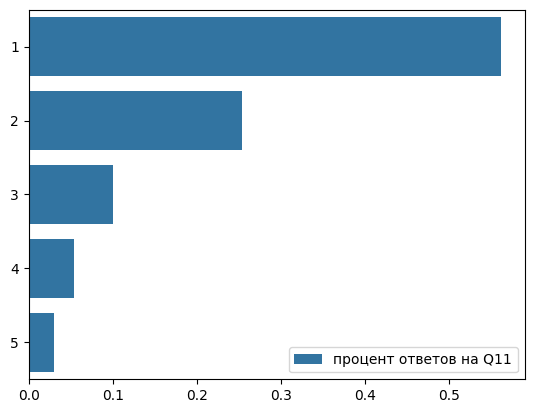

In [36]:
sns.barplot(y=[1,2,3,4,5], x=(df["Q11A"].value_counts() / len(df)).sort_index().values, orient='h', label='процент ответов на Q11')

In [37]:
(df["Q13A"].value_counts() / len(df)).sort_index().values[0:3]

array([0.29230581, 0.16765799, 0.09175049])

<Axes: >

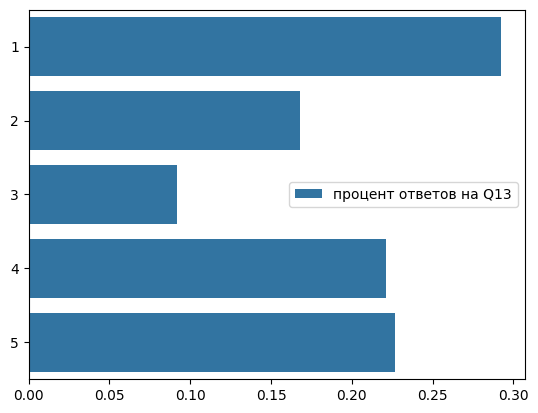

In [38]:
sns.barplot(y=[1,2,3,4,5], x=(df["Q13A"].value_counts() / len(df)).sort_index().values, orient='h', label='процент ответов на Q13')

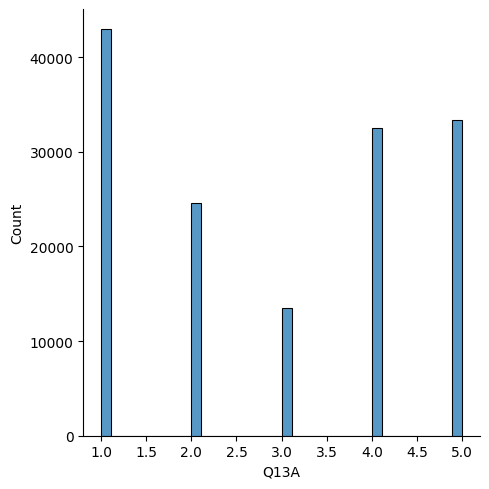

In [39]:
sns.displot(df["Q13A"])

#### Question position EDA

In [40]:
df[quest_pos].describe().T

,count,mean,std,min,25%,50%,75%,max
Q1I,146942.0,10.533435,5.771875,1.0,6.0,11.0,16.0,20.0
Q2I,146942.0,10.525582,5.759086,1.0,6.0,11.0,16.0,20.0
Q3I,146942.0,10.502035,5.769641,1.0,6.0,11.0,16.0,20.0
Q4I,146942.0,10.492466,5.764416,1.0,5.0,10.0,15.0,20.0
Q5I,146942.0,10.486804,5.764021,1.0,5.0,10.0,16.0,20.0
Q6I,146942.0,10.503559,5.745918,1.0,6.0,10.0,15.0,20.0
Q7I,146942.0,10.469410,5.773168,1.0,5.0,10.0,15.0,20.0
Q8I,146942.0,10.465735,5.764737,1.0,5.0,10.0,15.0,20.0
Q9I,146942.0,10.492235,5.773654,1.0,5.0,10.0,15.0,20.0
Q10I,146942.0,10.482871,5.757099,1.0,5.0,10.0,15.0,20.0


<Axes: xlabel='Q1I', ylabel='Count'>

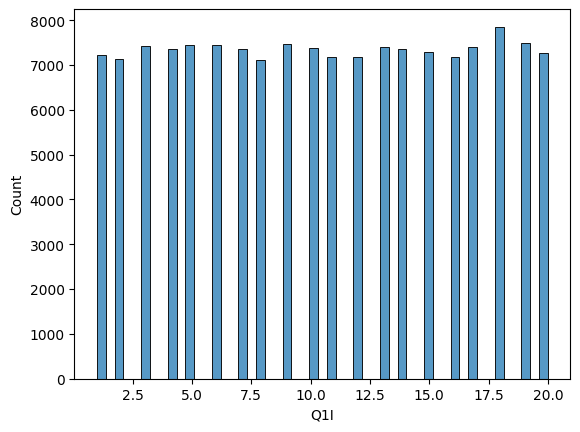

In [41]:
sns.histplot(df['Q1I'])

As we can see, each position of each question really is random, and the distribution of positions is uniform

#### Question answer time EDA

Each answer time is given in milliseconds. It will be more handy for analysis to convert milliseconds to seconds.

In [42]:
ans_tim = df[quest_tim] / 1000

In [43]:
ans_tim.describe().T

,count,mean,std,min,25%,50%,75%,max
Q1E,146942.0,14.527864,375.149088,0.178,5.21300,7.263,10.93300,80895.528
Q2E,146942.0,11.244676,158.073569,-62.148,4.54525,6.319,9.34400,32341.882
Q3E,146942.0,16.686954,849.785649,0.177,5.62100,7.919,11.86075,221152.989
Q4E,146942.0,8.319136,151.472154,-5.376,3.29200,4.656,7.04800,29942.574
Q5E,146942.0,20.180391,458.167630,-4.131,6.43100,9.087,13.89100,86528.987
Q6E,146942.0,6.903806,41.481492,0.178,3.07200,4.302,6.45575,4480.406
Q7E,146942.0,11.502672,420.771187,-1.621,3.62100,5.138,7.80900,82345.911
Q8E,146942.0,11.516996,156.487100,-43.906,5.01900,6.919,10.11175,32555.200
Q9E,146942.0,15.053485,247.599766,-3574.216,6.13700,8.453,12.44300,40985.184
Q10E,146942.0,29.362366,784.596235,-7.626,8.95200,12.880,19.80700,119251.023


Now here we can see some very mischievous things. 
- Firstly, a lot of **minimal values in here are negative**, and time **cannot be negative** in our case.
- We also have some very **extreme outliers** in each question: Q20 time : 749602 = 208 hours. Nonsense! All of that is subject to cleaning. Also, we can see, that big outliers drag the mean towards themselves, as in many cases the mean is bigger that even the third percentile

<Axes: ylabel='Q6E'>

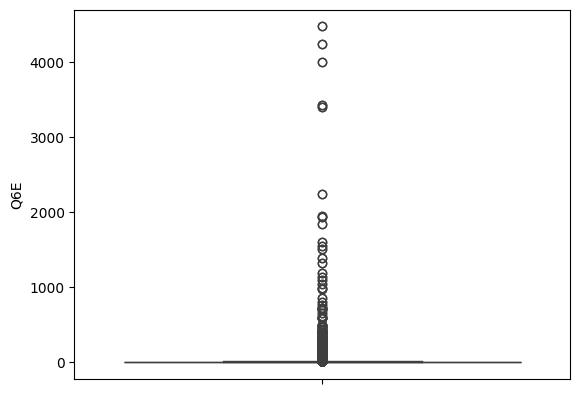

In [44]:
sns.boxplot(ans_tim['Q6E'])

We can see that there's a hell lot of outliers of very big amounts of times. I dont really believe that it took like a hudred of people more than 10 minutes to answer a question, though there's a guy who spent 208 hours answering a question haha

Lets cut the thing by the IQR. Our goal is to get sensible results in terms of answer time. a normal person should take around 2-5 seconds to answer a question. Everything smaller than 1.5 seconds is garbage data, as those are either 1. not real answers 2. answers of people that clicked through things randomly 3. technical noise/error data. To ensure integrity of our data, we will not cut the smallest values to be sensible, we'll just ensure, that the minimum values are not below zero.

In [45]:
for col in quest_tim:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1    

    upper_bound = Q3 + 1.5 * IQR 
    # lower_bound = Q1 - 1.5 * IQR 
    # # low_limit = df[col].quantile(0.05)
    # # high_limit = df[col].quantile(0.95)
    
    mask_lower = df[col].gt(0)
    mask_upper = df[col].gt(upper_bound)
    
    df.loc[~mask_lower, col] = 0
    df.loc[mask_upper, col] = None 


In [46]:
(df[quest_tim]/1000).describe().T

,count,mean,std,min,25%,50%,75%,max
Q1E,134516.0,7.736927,3.707939,0.178,5.055,6.8640,9.63300,19.511
Q2E,135346.0,6.690509,3.114541,0.000,4.413,6.0050,8.37100,16.542
Q3E,134664.0,8.371327,4.064588,0.177,5.445,7.4870,10.51325,21.220
Q4E,135896.0,5.009007,2.426772,0.000,3.199,4.4190,6.29800,12.681
Q5E,133182.0,9.603882,4.766550,0.000,6.195,8.5270,12.05300,25.081
Q6E,135402.0,4.609413,2.178671,0.178,2.986,4.0790,5.77200,11.530
Q7E,135150.0,5.514637,2.698741,0.000,3.510,4.8600,6.92300,14.091
Q8E,135604.0,7.298004,3.343337,0.000,4.880,6.5990,9.11000,17.750
Q9E,135178.0,8.935238,4.132433,0.000,5.957,8.0390,11.15600,21.896
Q10E,135336.0,13.843631,7.053001,0.000,8.682,12.1640,17.58800,36.088


In [47]:
imp = IterativeImputer(RandomForestRegressor())
df[quest_tim] = imp.fit_transform(df[quest_tim])

KeyboardInterrupt: 

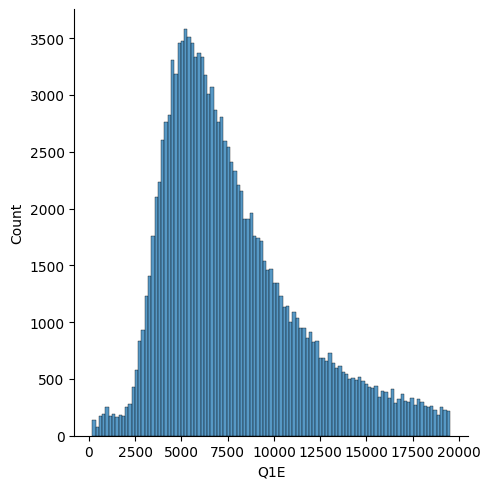

In [48]:
sns.displot(df['Q1E'])

Well we're lookin fabulous. Now the values look sensible.

#### TIPI EDA

In [49]:
df[tipi_cols].describe().T.sort_values('std', ascending=False)

,count,mean,std,min,25%,50%,75%,max
TIPI4,146942.0,3.968818,2.044261,0.0,2.0,4.0,6.0,7.0
TIPI1,146942.0,3.987301,2.004674,0.0,2.0,4.0,6.0,7.0
TIPI6,146942.0,4.561038,2.001701,0.0,3.0,5.0,6.0,7.0
TIPI8,146942.0,3.510814,1.982526,0.0,2.0,3.0,5.0,7.0
TIPI2,146942.0,4.432729,1.902608,0.0,3.0,5.0,6.0,7.0
TIPI9,146942.0,4.701161,1.860798,0.0,3.0,5.0,6.0,7.0
TIPI7,146942.0,4.944400,1.798674,0.0,4.0,5.0,6.0,7.0
TIPI10,146942.0,2.653877,1.715257,0.0,1.0,2.0,4.0,7.0
TIPI3,146942.0,5.174395,1.712916,0.0,4.0,6.0,6.0,7.0
TIPI5,146942.0,5.647126,1.475171,0.0,5.0,6.0,7.0,7.0


Observations: there're minimum values in each of tipi characteristics, which are equal to 0. It should prolly not happen, as according to data description, the answer range for those columns is 1-7. The data also states, that there're people who didnt take the TIPI test. So, are the zeros from those people, or is the data really broken?

In [50]:
df[df[tipi_cols].map(lambda x: not bool(x)).all(axis=1)][tipi_cols]

,TIPI1,TIPI2,TIPI3,TIPI4,TIPI5,TIPI6,TIPI7,TIPI8,TIPI9,TIPI10
289,0,0,0,0,0,0,0,0,0,0
648,0,0,0,0,0,0,0,0,0,0
679,0,0,0,0,0,0,0,0,0,0
867,0,0,0,0,0,0,0,0,0,0
1199,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
145778,0,0,0,0,0,0,0,0,0,0
146597,0,0,0,0,0,0,0,0,0,0
146723,0,0,0,0,0,0,0,0,0,0
146810,0,0,0,0,0,0,0,0,0,0


There're 450 people that didnt take the test at all.

In [51]:
df[df[tipi_cols].map(lambda x: not bool(x)).any(axis=1)][tipi_cols]

,TIPI1,TIPI2,TIPI3,TIPI4,TIPI5,TIPI6,TIPI7,TIPI8,TIPI9,TIPI10
14,4,6,7,5,5,0,6,2,6,1
27,3,5,0,4,4,1,5,1,6,1
75,0,5,1,6,5,7,3,1,2,4
244,6,6,4,5,4,0,4,5,3,3
251,4,3,3,2,6,5,0,5,6,3
...,...,...,...,...,...,...,...,...,...,...
146768,6,0,0,0,0,0,0,0,0,0
146810,0,0,0,0,0,0,0,0,0,0
146861,3,5,0,4,6,5,4,4,4,3
146895,0,0,0,0,0,0,0,0,0,0


There're 2_720 people that have zeros in their tests, even though they have taken those tests.


For overall stability and logic, lets suppose, that if there's a zero in the answer the person didnt answer. 

Either one didnt want to answer or didnt care, in my subjective opinion, one would put 3 in both cases. So, we will replace zeros with threes for those, hwo have taken the TIPI test.

In [52]:
zero_counts = df[tipi_cols].map(lambda x: not bool(x)).sum(axis=1)

row_mask = zero_counts.gt(0) & zero_counts.le(9)

df.loc[row_mask, tipi_cols] = df.loc[row_mask, tipi_cols].replace(0, 3)


So, how many tipi results for the people that have taken the test are there which still have zero in them?

In [53]:
df[df[tipi_cols].map(lambda x: not bool(x)).sum(axis=1) == 9][tipi_cols]

,TIPI1,TIPI2,TIPI3,TIPI4,TIPI5,TIPI6,TIPI7,TIPI8,TIPI9,TIPI10


Job done

#### VCL EDA

In [54]:
df[every_vcl].describe().T.sort_values(by='mean', ascending=False)

,count,mean,std,min,25%,50%,75%,max
VCL16,146942.0,0.968314,0.175163,0.0,1.0,1.0,1.0,1.0
VCL10,146942.0,0.942930,0.231977,0.0,1.0,1.0,1.0,1.0
VCL4,146942.0,0.941392,0.234891,0.0,1.0,1.0,1.0,1.0
VCL15,146942.0,0.929972,0.255194,0.0,1.0,1.0,1.0,1.0
VCL1,146942.0,0.926080,0.261642,0.0,1.0,1.0,1.0,1.0
VCL5,146942.0,0.909543,0.286837,0.0,1.0,1.0,1.0,1.0
VCL2,146942.0,0.878347,0.326886,0.0,1.0,1.0,1.0,1.0
VCL14,146942.0,0.855249,0.351851,0.0,1.0,1.0,1.0,1.0
VCL13,146942.0,0.684814,0.464591,0.0,0.0,1.0,1.0,1.0
VCL3,146942.0,0.384152,0.486396,0.0,0.0,0.0,1.0,1.0


<Axes: ylabel='VCL1'>

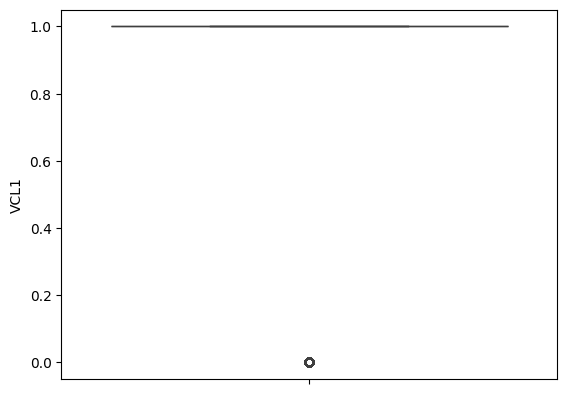

In [55]:
sns.boxplot(df['VCL1'])

Nothing out of the ordinary as expected. We can also see that the words 6,9,12 are the least known (as they're non-existent)

#### Technical EDA

In [56]:
df[technical].describe().T

,count,mean,std,min,25%,50%,75%,max
screenw,146942.0,968.096501,609.557715,0.0,375.0,834.0,1440.0,7680.0
screenh,146942.0,801.796559,182.381416,0.0,667.0,768.0,900.0,2960.0


<Axes: >

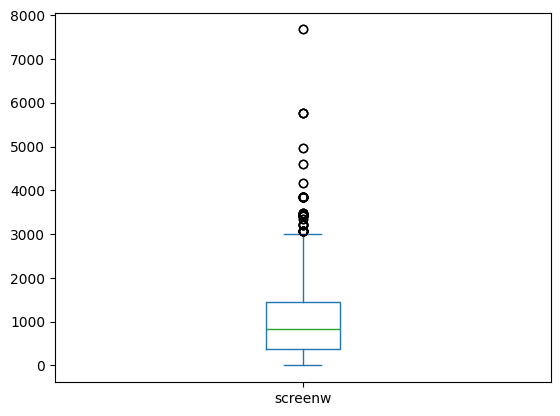

In [57]:
df['screenw'].plot(kind='box')

<Axes: >

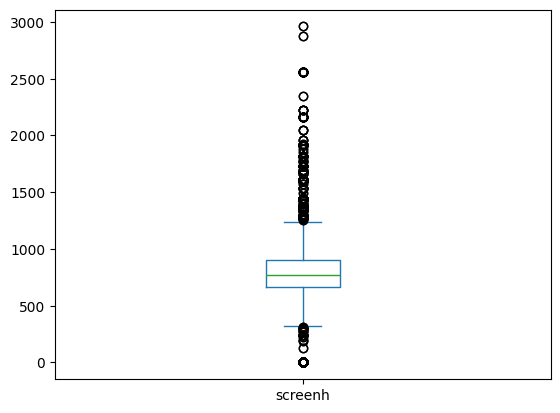

In [58]:
df['screenh'].plot(kind='box')

This is technical data, which doesnt really apply to our topic. We can see some outliers, but they arent important to us. For now...

#### Personal characteristics EDA

In [59]:
df[persn_chr].describe()

,education,urban,gender,engnat,age,hand,religion,orientation,race,voted,married,familysize
count,146942.000000,146942.000000,146942.000000,146942.000000,1.469420e+05,146942.000000,146942.000000,146942.000000,146942.000000,146942.000000,146942.000000,1.469420e+05
mean,2.551973,2.209334,1.467763,1.370663,1.656538e+02,1.168856,4.551224,1.357842,50.563624,1.544664,1.354249,2.924385e+04
std,0.939919,0.775616,0.524288,0.486326,3.340765e+04,0.469472,3.558855,0.897227,20.288700,0.513637,0.625017,7.922650e+06
min,0.000000,0.000000,0.000000,0.000000,1.300000e+01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00
25%,2.000000,2.000000,1.000000,1.000000,1.900000e+01,1.000000,2.000000,1.000000,60.000000,1.000000,1.000000,2.000000e+00
50%,3.000000,2.000000,1.000000,1.000000,2.500000e+01,1.000000,4.000000,1.000000,60.000000,2.000000,1.000000,2.000000e+00
75%,3.000000,3.000000,2.000000,2.000000,3.600000e+01,1.000000,7.000000,1.000000,60.000000,2.000000,2.000000,3.000000e+00
max,4.000000,3.000000,3.000000,2.000000,9.000009e+06,3.000000,12.000000,5.000000,70.000000,2.000000,3.000000,2.147484e+09


<Axes: >

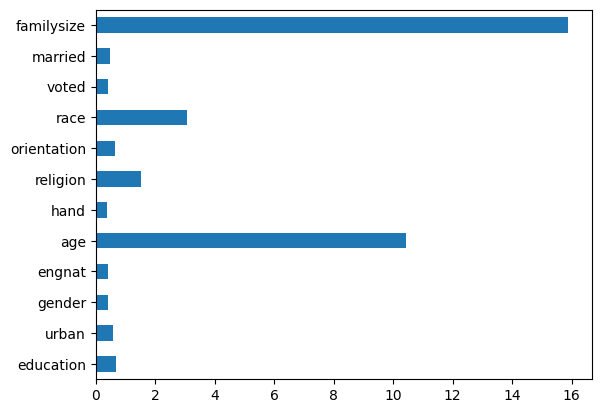

In [60]:
np.log1p(df[persn_chr].describe().loc['std']).plot(kind='barh')

There're some anomoulously big stds present, even had to logarithmisize everything to get a hold of whats going on. It seems there're anomalies in **familisize**, **age** and *maybe* **race**

<Axes: ylabel='familysize'>

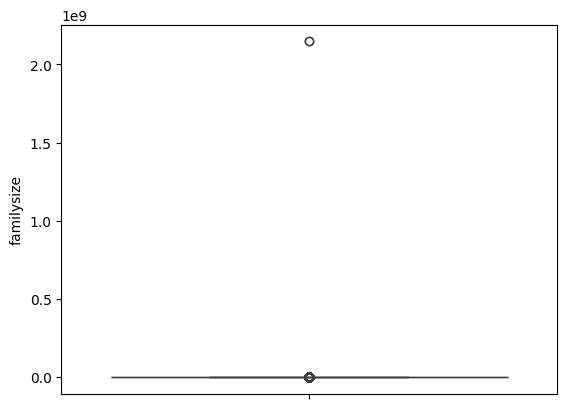

In [61]:
sns.boxplot(df['familysize'])

In [62]:
upper_bound = df['familysize'].quantile(.90)

anomolous_mask = df['familysize'].gt(upper_bound)

df.loc[anomolous_mask, ['familysize']] = df['familysize'].median()

<Axes: ylabel='familysize'>

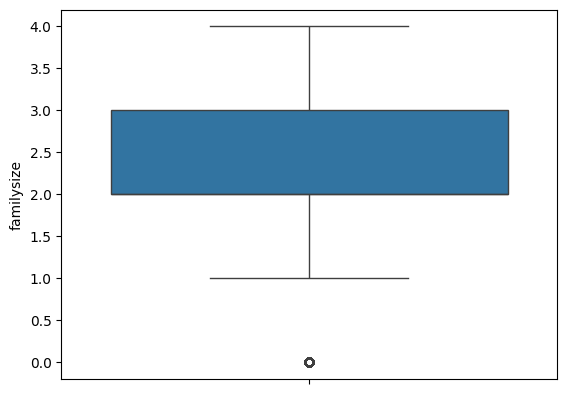

In [63]:
sns.boxplot(df['familysize'])

<Axes: ylabel='age'>

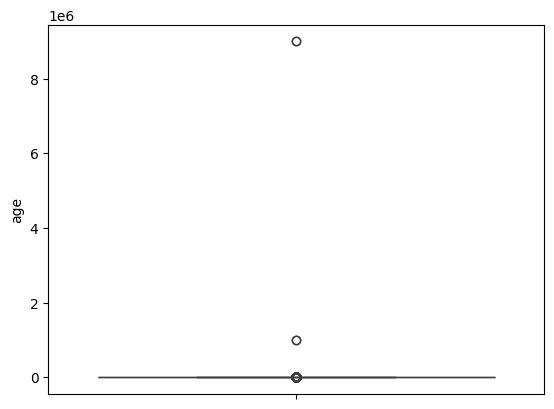

In [64]:
sns.boxplot(df['age'])

In [65]:
upper_bound = df['age'].quantile(.90)

anomolous_mask = df['age'].gt(upper_bound)

df.loc[anomolous_mask, ['age']] = df['age'].median()

<Axes: ylabel='age'>

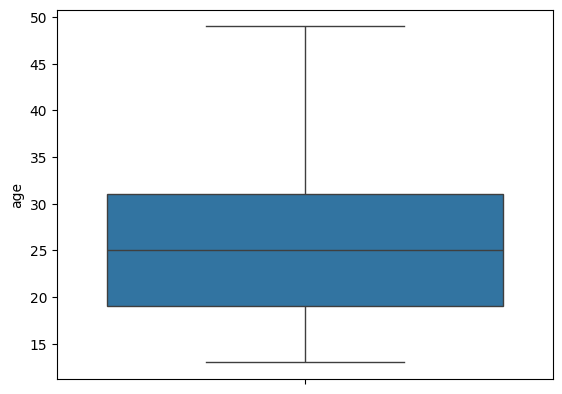

In [66]:
sns.boxplot(df['age'])

There're creatures so ancient that even the fact of their presence makes ones heart sink in a lake of terror.

<Axes: ylabel='race'>

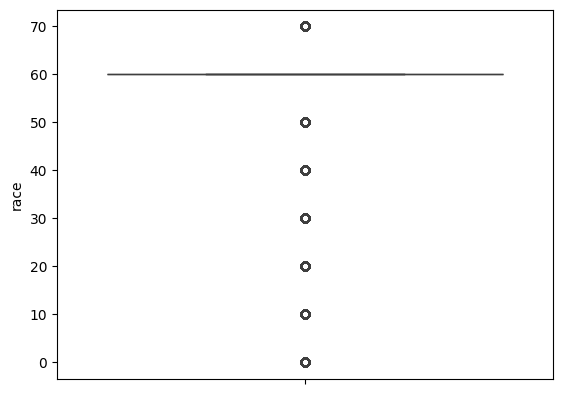

In [67]:
sns.boxplot(df['race'])

<Axes: >

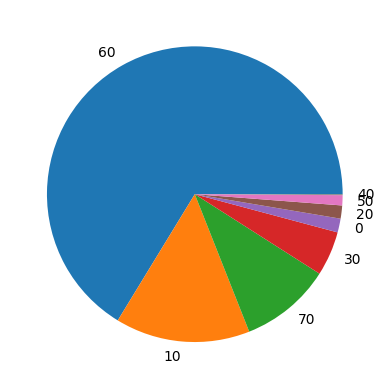

In [68]:
df['race'].value_counts().plot(kind='pie')

everything is orderly with the race, people are just that diverse

<Axes: >

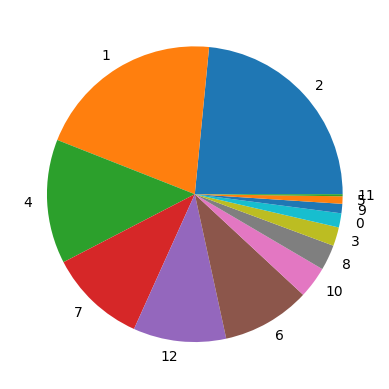

In [69]:
df['religion'].value_counts().plot(kind='pie')

# Clusterizing the high cardinality "major" column

In [70]:
df['major'].nunique()

8935

In [71]:
df['major'].head()

0                 Marketing 
1                mathematics
2                  Chemistry
3    international relations
4                 Management
Name: major, dtype: string

In [72]:
df[df['major'].str.contains('math')]['major'].unique()

<ArrowStringArray>
[                                  'mathematics',
                                          'math',
                                         'maths',
 'maths| physics| chemistry| informatics| econo',
 'financial actuarial math / communication stud',
                    'Physics| maths| management',
                        'Physics an mathematics',
                'Accounting maths business law ',
                                'Biomathematics',
       'computer science & discrete mathematics',
                          'maths/sports science',
                                  'math/science',
                         'mathematics education',
                    'history of art| mathematic',
                                  'Applied math',
                           'Applied mathematics',
                 'math| psychology| engineering',
                                  'mathematics ',
                           'applied mathematics',
                 'Systems scien

#### There're nearly nine thousands unique major values, and as we can see most of those arent unique. They're either mixed majors or just different formats or names for the same major.

 Working with those amounts of data manually is too long for one analyst, especially considering that manually probably means categorizing majors through Levensteins distance and than grouping them up by hand (or by distance closness epsilon). 
 
 Those methods, and others that come up to mind are:
- Time consuming
- Non reliable in semantical sense. E.g. 'social worker' will be far from 'welfare worker', but probably close to 'sociology worker'.

#### Thus, it is *logical* to **use nlp clusterization.** It will:
- Clusterize everything semantically so that different names of the same major end up in the same group. 
- Also, as embedding words in some sense gives a machine a sense of direction a persons attitude, it will eliminate the need to deal with mixed categories, i.e. "Economics| Political Science" are clearly humanities type of majors, and will be put to the some category of people studying one of those subjects (or, if it is a tendency to have this pair of majors, to a cluster of people with the same pair of majors)

In [73]:
majors = df['major']

In [74]:
import torch._utils
import torch



if not os.path.exists('embeddings.pt'):
    talk('embedding')
    transformer = SentenceTransformer('intfloat/multilingual-e5-large', device='xpu')
    embeddings = transformer.encode([f'query: {e}' for e in majors.tolist()], batch_size=64, show_progress_bar=True, convert_to_numpy=True, normalize_embeddings=True)
    torch.save(torch.from_numpy(embeddings), 'embeddings.pt')
else:
    embeddings = torch.load('embeddings.pt', weights_only=False)

Lets reduce the vectors to 15 components, as clusterizing 140_000 1024D points will be computationally expensive and will also not result in anything great because of the curse of dimensiality.

In [75]:
if not os.path.exists('clusters_majors.csv'):
    talk('UMAP process')
    reducer = umap.UMAP(n_components=15, unique=True, metric='cosine', n_jobs=-1)
    X_matrix = np.vstack(embeddings)
    X_umap = reducer.fit_transform(X_matrix)
else:
    df['cluster'] = pd.read_csv('clusters_majors.csv').set_index(['Unnamed: 0'])

/tmp/ipykernel_119103/1719409682.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['cluster'] = pd.read_csv('clusters_majors.csv').set_index(['Unnamed: 0'])


We'll use hierarchical dbscan to ensure we get a sensible amount of clusters, but also we'll not mix a lot of them to some junk cluster. The parameters for initialization were picked empirically based on the amount of clusters and their contents 

In [76]:
if not os.path.exists('clusters_majors.csv'):
    talk('Clusterization')
    dbscan = ALThdb(
        min_cluster_size=8,   # Minimum size to be considered a major cluster (15 5, 830 c)
        min_samples=2,         # How conservative the clustering is (higher = more noise)
        cluster_selection_epsilon=0.4,  # Allows varying densities
    )
    df['cluster'] = dbscan.fit_predict(X_umap)
    df = df.copy()
    df['cluster'].to_csv('clusters_majors.csv')

In [77]:
df['cluster'].nunique()

84

In [78]:
major_clusters = df.groupby('cluster')['major'].nunique().sort_values(ascending=False)

In [79]:
major_clusters.head()

cluster
80    1943
78    1190
61     886
71     501
79     487
Name: major, dtype: int64

In [80]:
major_clusters.index.max()

np.int64(82)

As we can see, the clusters make sense in most cases. There're some leaks, like in cluster 80, when biology got sent in what it seems, a a humanities cluster, but those interdisciplinary errors are rare to accure. Most of the clusters consist of close majors.

In [81]:
for cluster in major_clusters.index:
    name = profession(df, cluster, 3)
    print(f'{cluster}: {name}')

80: ['Psychology', 'psychology', 'History']
78: ['Business', 'Economics', 'Accounting']
61: ['Music', 'Communications', 'Communication']
71: ['Law', 'Political Science', 'law']
79: ['English', 'English ', 'english']
26: ['Unknown', 'IT', 'No']
75: ['Computer Science', 'computer science', 'Computer science']
18: ['Environmental Science', 'Agriculture', 'Ecology']
37: ['Electrical Engineering', 'electrical engineering', 'Electrical engineering']
50: ['Education', 'Education ', 'education']
22: ['Physics', 'Science', 'physics']
8: ['International Relations', 'international relations', 'International relations']
82: ['Engineering', 'engineering', 'civil engineering']
58: ['Criminal Justice', 'Criminology', 'Criminal justice']
21: ['Information Technology', 'Technology', 'Computing']
39: ['Tourism', 'Hospitality', 'Nutrition']
0: ['&#24515;&#29702;&#23398;', '&#22303;&#26408;&#24037;&#31243;', '&#37329;&#34701;']
42: ['Cyber Security', 'Information Security', 'National Security']
19: ['Chem

# First engineered features: question points sums for question categories.

I'll create a categorization of questions, as the binary features will not be very useful in terms of comprehensive analysis. How? We can combine two tactics. First is using common sense. It is clear, that some questions test straightly for machiavellianism, i.e:
- Q1: Never tell anyone the real reason you did something unless it is useful to do so. (testing manipulativeness)
- Q2: The best way to handle people is to tell them what they want to hear. (testing manipulativeness)
- Q15: It is wise to flatter important people. (focus on self interest, emotional detachment)
etc.

We can also look at the correlation matrix question-to-question to see, which questions seem to accompany each other and which test for two opposite personality traits (e.g. misantropy vs kindness and optimism)

In [82]:
questions_denominations = {
"Q1" : "Never tell anyone the real reason you did something unless it is useful to do so.",
"Q2" : "The best way to handle people is to tell them what they want to hear.",
"Q3" : "One should take action only when sure it is morally right.",
"Q4" : "Most people are basically good and kind.",
"Q5" : "It is safest to assume that all people have a vicious streak and it will come out when they are given a chance.",
"Q6" : "Honesty is the best policy in all cases.",
"Q7" : "There is no excuse for lying to someone else.",
"Q8" : "Generally speaking, people won't woforrk hard unless they're forced to do so.",
"Q9" : "All in all, it is better to be humble and honest than to be important and dishonest.",
"Q10" : "When you ask someone to do something for you, it is best to give the real reasons for wanting it rather than giving reasons which carry more weight.",
"Q11" : "Most people who get ahead in the world lead clean, moral lives.",
"Q12" : "Anyone who completely trusts anyone else is asking for trouble.",
"Q13" : "The biggest difference between most criminals and other people is that the criminals are stupid enough to get caught.",
"Q14" : "Most people are brave.",
"Q15" : "It is wise to flatter important people.",
"Q16" : "It is possible to be good in all respects.",
"Q17" : "P.T. Barnum was wrong when he said that there's a sucker born every minute.",
"Q18" : "It is hard to get ahead without cutting corners here and there.",
"Q19" : "People suffering from incurable diseases should have the choice of being put painlessly to death.",
"Q20" : "Most people forget more easily the death of their parents than the loss of their property."
}

In [83]:
quest_ans_corr = df[quest_ans].corr()

<Axes: >

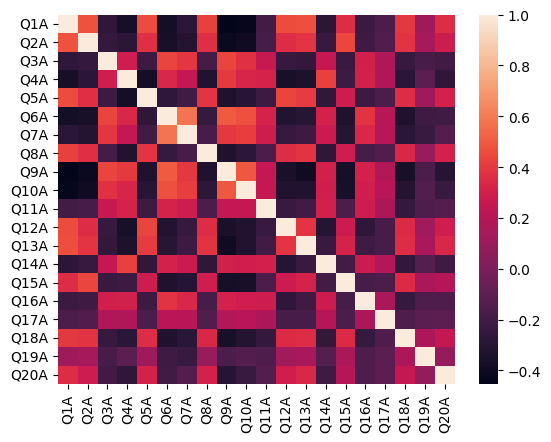

In [84]:
sns.heatmap(quest_ans_corr)

We can see an interesting picture! The correlations are distinct (which is to be expected from binary features) and the correlation matrix in squary.

In [85]:
print(f'Questions that accompany Q3A: One should take action only when sure it is morally right.')
for question, correlation in quest_ans_corr[quest_ans_corr['Q3A'].gt(0)]['Q3A'].sort_values(ascending=False).items():
    print(f'{round(correlation, 3)} {question}: {questions_denominations[question[:-1]]}')

Questions that accompany Q3A: One should take action only when sure it is morally right.
1.0 Q3A: One should take action only when sure it is morally right.
0.433 Q6A: Honesty is the best policy in all cases.
0.433 Q9A: All in all, it is better to be humble and honest than to be important and dishonest.
0.388 Q7A: There is no excuse for lying to someone else.
0.37 Q10A: When you ask someone to do something for you, it is best to give the real reasons for wanting it rather than giving reasons which carry more weight.
0.301 Q16A: It is possible to be good in all respects.
0.286 Q4A: Most people are basically good and kind.
0.261 Q11A: Most people who get ahead in the world lead clean, moral lives.
0.252 Q14A: Most people are brave.
0.176 Q17A: P.T. Barnum was wrong when he said that there's a sucker born every minute.


As we can clearly see, this question targets for persons perception of honesty and kindness. Let create an exhaustive grouping, one can say, clusterization, to check, if the questions positive-correlation groups intertvine with each other.

In [86]:
grn = "\033[32m"
ylw = "\033[33m"
blu = "\033[34m"
rst = "\033[0m"
red = "\033[31m"

In [87]:
questions_groups = [[quest_ans[0]]]

for column in quest_ans:
    print(f'{grn}Questions that accompany {column}: {questions_denominations[column[:-1]]} {rst}')
    
    column_in_any_group = False
    for group in questions_groups:
        if column in group:
            column_in_any_group = True
            current_group = group
            break

    if not column_in_any_group:
        new_group = [column]
        questions_groups.append(new_group)
        current_group = new_group
    correlated_series = quest_ans_corr[quest_ans_corr[column].gt(0.2)][column].sort_values(ascending=False)

    for question, correlation in correlated_series.items():
        if correlation == 1.0: 
            continue
        print(f'\t{round(correlation, 3)} {question}: {questions_denominations[question[:-1]]}')
        if not (question in current_group):
            current_group.append(question)
    print(f"Current Groups State: {questions_groups}\n")

Questions that accompany Q1A: Never tell anyone the real reason you did something unless it is useful to do so. 
	0.474 Q2A: The best way to handle people is to tell them what they want to hear.
	0.462 Q13A: The biggest difference between most criminals and other people is that the criminals are stupid enough to get caught.
	0.46 Q5A: It is safest to assume that all people have a vicious streak and it will come out when they are given a chance.
	0.458 Q12A: Anyone who completely trusts anyone else is asking for trouble.
	0.416 Q8A: Generally speaking, people won't woforrk hard unless they're forced to do so.
	0.394 Q18A: It is hard to get ahead without cutting corners here and there.
	0.356 Q20A: Most people forget more easily the death of their parents than the loss of their property.
	0.354 Q15A: It is wise to flatter important people.
Current Groups State: [['Q1A', 'Q2A', 'Q13A', 'Q5A', 'Q12A', 'Q8A', 'Q18A', 'Q20A', 'Q15A']]

Questions that accompany Q2A: The best way to handle peo

In [88]:
questions_groups

[['Q1A', 'Q2A', 'Q13A', 'Q5A', 'Q12A', 'Q8A', 'Q18A', 'Q20A', 'Q15A'],
 ['Q3A', 'Q6A', 'Q9A', 'Q7A', 'Q10A', 'Q16A', 'Q4A', 'Q11A', 'Q14A', 'Q17A'],
 ['Q19A']]

In [89]:
len(questions_groups[0])

9

In [90]:
for category in questions_groups[:2]:
    print(grn,category, round(pg.cronbach_alpha(df[category], items=category)[0], 2),rst)
    for question in category:
        print(questions_denominations[question[:-1]])

 ['Q1A', 'Q2A', 'Q13A', 'Q5A', 'Q12A', 'Q8A', 'Q18A', 'Q20A', 'Q15A'] 0.83 
Never tell anyone the real reason you did something unless it is useful to do so.
The best way to handle people is to tell them what they want to hear.
The biggest difference between most criminals and other people is that the criminals are stupid enough to get caught.
It is safest to assume that all people have a vicious streak and it will come out when they are given a chance.
Anyone who completely trusts anyone else is asking for trouble.
Generally speaking, people won't woforrk hard unless they're forced to do so.
It is hard to get ahead without cutting corners here and there.
Most people forget more easily the death of their parents than the loss of their property.
It is wise to flatter important people.
 ['Q3A', 'Q6A', 'Q9A', 'Q7A', 'Q10A', 'Q16A', 'Q4A', 'Q11A', 'Q14A', 'Q17A'] 0.82 
One should take action only when sure it is morally right.
Honesty is the best policy in all cases.
All in all, it is bett

As we see, our automatic question clustering came up with these two groups. One seems to straightly be testing for machiavelllianism, while the second tests for honesty, kindness and empathy.

I have decided to check, what kind of division was concieved by the authors when they were creating the test, and there're three groups. But one of my groups is just two of intended groups merged. Also it turns out, the modern data analysts tend to divide the groups in two, just like the current division.

Interestingly, automatic grouping excluded Q19 from bot of significant groups. It is not an error, Q19:
- People suffering from incurable diseases should have the choice of being put painlessly to death.

isn't testing for personal features that we're interested in, it doesn't seem do be connected directly with machiavellianism. And it really doesn't belong to the topic: this question is being criticized by the scientific community, as a question that isn't directly measuring machiavellianism. Also, the understanding of hadling ones own life have greatly shifted since 1970 (when the test was created) so this question can be marked as obsolete (and it is by our grouping algorithm). 

We can also see that the Cronbachs alpha is >= 0.8 for both groups, which even further confirms the structural integrity of groups.

**Now lets compare the automatically created features with my own categorization of questions.**

In [91]:
cat_question = {'Moral, righteousness' : ['Q3', 'Q7', 'Q17', 'MorRit'],
              'Kindness, Honesty': ['Q4', 'Q9', 'Q10', 'Q14', 'Q16', 'KindHin'],
              'Macciavelism': ['Q1', 'Q2', 'Q5', 'Q15', 'Q18', 'Macc'],
              'Misanthropy': ['Q8', 'Q12', 'Q13', 'Q20', 'Misant']}

In [92]:
for category in cat_question.values():
    questions_cat = [f'{e}A' for e in category[:-1]]
    print(category, round(pg.cronbach_alpha(df[questions_cat], items=questions_cat)[0], 2))

['Q3', 'Q7', 'Q17', 'MorRit'] 0.51
['Q4', 'Q9', 'Q10', 'Q14', 'Q16', 'KindHin'] 0.72
['Q1', 'Q2', 'Q5', 'Q15', 'Q18', 'Macc'] 0.76
['Q8', 'Q12', 'Q13', 'Q20', 'Misant'] 0.68


As I am not a psychologist by any measure, my categorization seems to be more inconsistent than the automatic one. I have also used the domain knowledge about Q19, that is why it isnt on my categorization list. 

Considering, that the automatically generated questions are more significant we will use them.

In [93]:
cat_question = {'Machiavellianism': {'questions': questions_groups[0], 'feat_name':'MachScr'},
                'Honesty, Kindness': {'questions': questions_groups[1], 'feat_name': 'KindScr'},
                }

In [94]:
for category, metadata in cat_question.items():
    new_feature_name = metadata['feat_name']
    df[new_feature_name] = 0
    for column in metadata['questions']:
        df[new_feature_name] += df[column]

/tmp/ipykernel_119103/1238485734.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[new_feature_name] = 0
/tmp/ipykernel_119103/1238485734.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[new_feature_name] = 0


### EDA FOR THE NEW SCORING FEATURES 

##### MachScr EDA

In [95]:
new_feat = ['MachScr', 'KindScr']

In [96]:
len(questions_groups[0])

9

In [97]:
df['MachScr'].describe()

count    146942.000000
mean         29.329232
std           8.544957
min           9.000000
25%          23.000000
50%          30.000000
75%          36.000000
max          45.000000
Name: MachScr, dtype: float64

In [98]:
df['MachScr'].median()

np.float64(30.0)

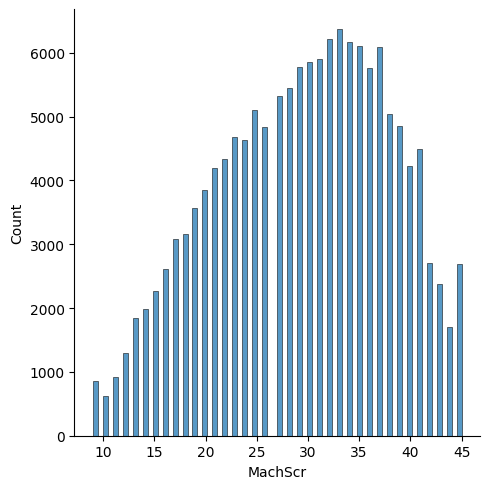

In [99]:
sns.displot(df['MachScr'])

<Axes: xlabel='MachScr'>

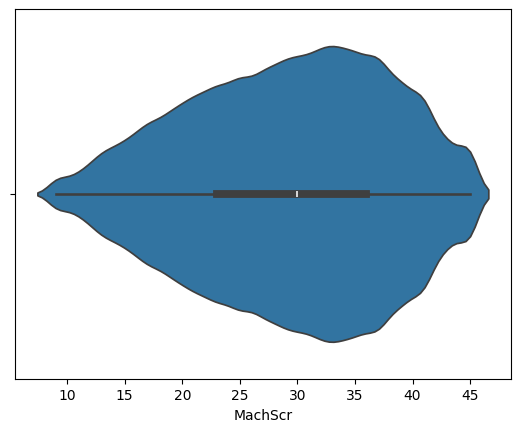

In [100]:
sns.violinplot(data=df, x='MachScr')

As we can see:
- the **median** for our data is *30* (when mathematically it should be around 27)
- **50 percents** of our data is **between 25 and 35**. 

- The graph is left-skewed.

 I've googled a bit and it turns out, that this is a **normal situation** for phsychometrics (left-skewed ditribution), especially considering, that the test scoring is from 1 to 5, where 3 is "**i am neutral** towards the statement". Therefore, it is logical that the median is 30 = 3\*10. People dont like to pick the highest options, and only do so when they *really* agree or disagree with the statement, so, for most questions they answer 3 to 4, which leads us to our current situation

As the current form of this score metric is misleading in numerical terms, it would be beneficial to transform it through the Z-scale, so the value 30 doesn't disturb us anymore and we also could abandon thinking about non standard 9-45 range.

In [101]:
# scaler = StandardScaler()
# scaler.fit(df[['MachScr']])
# df['MachScr'] = scaler.fit_transform(df[['MachScr']])

<Axes: ylabel='MachScr'>

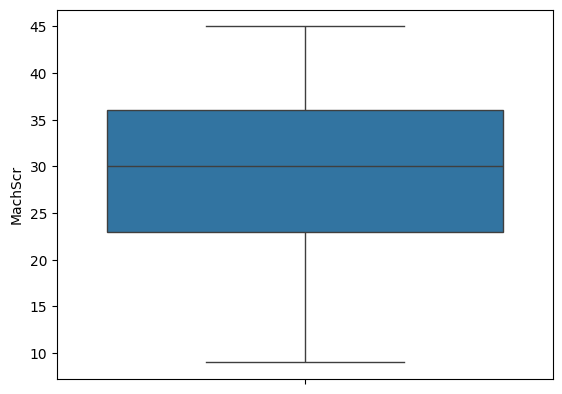

In [102]:
sns.boxplot(df['MachScr'])

##### KindScr EDA

In [103]:
df['KindScr'].describe()

count    146942.000000
mean         25.973690
std           8.465566
min          10.000000
25%          19.000000
50%          26.000000
75%          32.000000
max          50.000000
Name: KindScr, dtype: float64

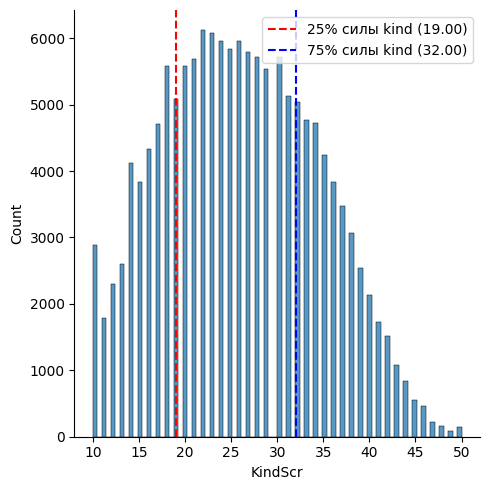

In [104]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# 1. Считаем квантили для нужной колонки
q25 = df["KindScr"].quantile(0.25)
q75 = df["KindScr"].quantile(0.75)

# 2. Строим displot и сохраняем его в переменную g
g = sns.displot(data=df, x="KindScr", kind="hist")

# 3. Добавляем линии на каждую координатную сетку (ось)
for ax in g.axes.flat:
    # Линия для Q25
    ax.axvline(q25, color="red", linestyle="--", linewidth=1.5, label=f"25% силы kind ({q25:.2f})")
    # Линия для Q75
    ax.axvline(q75, color="blue", linestyle="--", linewidth=1.5, label=f"75% силы kind ({q75:.2f})")
    
    # Добавляем легенду, чтобы было понятно, где какая линия
    ax.legend()

plt.show()


<Axes: xlabel='KindScr', ylabel='Density'>

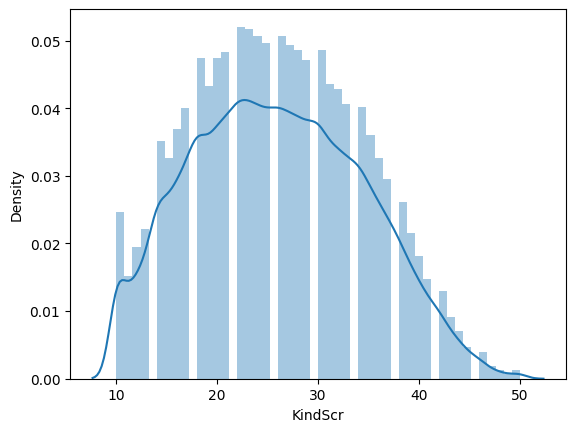

In [105]:
sns.distplot(df['KindScr'])

<Axes: ylabel='KindScr'>

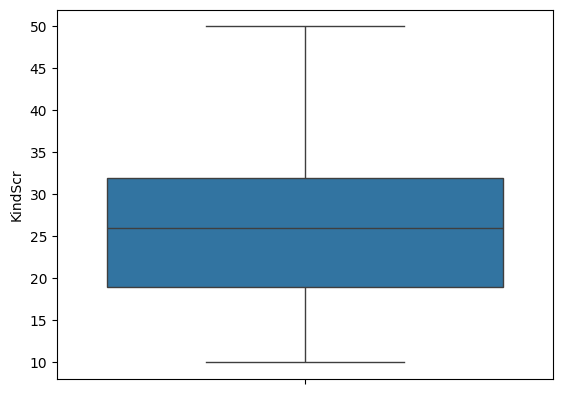

In [106]:
sns.boxplot(df['KindScr'])

In [107]:
len(questions_groups[1])

10

In [108]:
df['KindScr'].quantile(.25), df['KindScr'].quantile(.75)

(np.float64(19.0), np.float64(32.0))

Ironically, this distribution is right-skewed. People tend to score low on kindness, philantropy etc., which isnt a wonder either. The median is on 25, while the mathematical median is $\frac{50+10}{2}=30$. It seems, that people generally tend to answer low on question about kindness and philantropy. That probably is because they're cautious about their worldview and beliefs.

# Liar Analysis

In [109]:
len(df)

146942

#### Liars and personal characteristics interaction.

Lets check how do the personal characteristics of a person affect their lying. We'll do that by making use of the VCL feature, which checks the word knowledge of respondents. There're 3 imaginary words, we will decide if a person is a liar by checking how many of non existent words they know.

In [110]:
df['LiarSum'] = df['VCL6'] + df['VCL9'] + df['VCL12']

/tmp/ipykernel_119103/1707504590.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['LiarSum'] = df['VCL6'] + df['VCL9'] + df['VCL12']


In [170]:
vcl_cols = [f'VCL{i}' for i in range(1, 17)]

In [175]:
df[df[vcl_cols].sum(axis=1) >=14]

,Q1A,Q1I,Q1E,Q2A,Q2I,Q2E,Q3A,Q3I,Q3E,Q4A,...,race,voted,married,familysize,major,cluster,MachScr,KindScr,LiarSum,IsLiar
2,5.0,16.0,4186.0,5.0,12.0,2900.0,1.0,2.0,7160.0,1.0,...,10,2,1,2,Chemistry,19,43.0,10.0,3,1
56,5.0,14.0,NaN,4.0,2.0,13113.0,2.0,12.0,8950.0,1.0,...,10,2,1,0,Unknown,26,43.0,24.0,3,1
66,3.0,15.0,NaN,3.0,3.0,14380.0,4.0,10.0,10984.0,1.0,...,60,2,1,2,Unknown,26,26.0,22.0,3,1
89,4.0,10.0,6514.0,5.0,16.0,4618.0,1.0,8.0,4661.0,4.0,...,70,2,1,2,physiology,80,34.0,22.0,1,1
90,4.0,15.0,8880.0,2.0,1.0,NaN,1.0,3.0,18004.0,1.0,...,60,2,2,2,psychology,80,35.0,15.0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
146861,5.0,10.0,5858.0,5.0,11.0,2630.0,1.0,4.0,5442.0,1.0,...,70,2,3,2,Unknown,26,43.0,18.0,3,1
146906,1.0,18.0,NaN,3.0,7.0,NaN,5.0,2.0,NaN,2.0,...,60,2,2,2,Classica,61,21.0,36.0,3,1
146907,2.0,18.0,NaN,5.0,19.0,NaN,3.0,10.0,NaN,4.0,...,10,2,1,0,sociology,80,27.0,21.0,3,1
146950,5.0,11.0,3156.0,5.0,18.0,3551.0,1.0,14.0,4371.0,1.0,...,60,1,1,2,Politcial science,71,39.0,10.0,2,1


np.float64(1.3088765773505315)

6         1.076055
8         1.704483
22        1.410487
30        1.190975
32        1.164158
            ...   
146961    1.151658
146962    1.361114
146969    1.663066
146975    1.744163
146976    1.292692
Length: 37330, dtype: float64

6         1.076055
8         1.704483
22        1.410487
30        1.190975
32        1.164158
            ...   
146961    1.151658
146962    1.361114
146969    1.663066
146975    1.744163
146976    1.292692
Length: 37330, dtype: float64

In [ ]:
quantile = 0.25
q25 = df[df['testelapse'] <= df['testelapse'].quantile(quantile)]
q_b25 = df[df['testelapse'] > df['testelapse'].quantile(quantile)]

q25_to_norm_diff = q25[quest_ans].std(axis=1) - q_b25[quest_ans].std().median()
q75_diff = q25_to_norm_diff.quantile(0.75)
q25_diff = q25_to_norm_diff.quantile(0.25)
high_diff = q25_to_norm_diff[~q25_to_norm_diff.between(q25_diff, q75_diff)]


np.float64(0.31667196823315336)

In [111]:
df['IsLiar'] = df['LiarSum'].map(lambda x: 1 if x else x)

/tmp/ipykernel_119103/3421374402.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['IsLiar'] = df['LiarSum'].map(lambda x: 1 if x else x)


<Axes: xlabel='MachScr', ylabel='Density'>

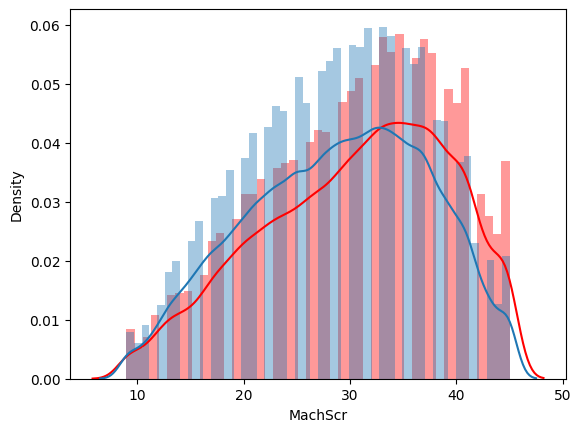

In [112]:
sns.distplot(df[df['IsLiar'] == 1]['MachScr'], color='red')
sns.distplot(df[df['IsLiar'] == 0]['MachScr'])

<Axes: xlabel='KindScr', ylabel='Density'>

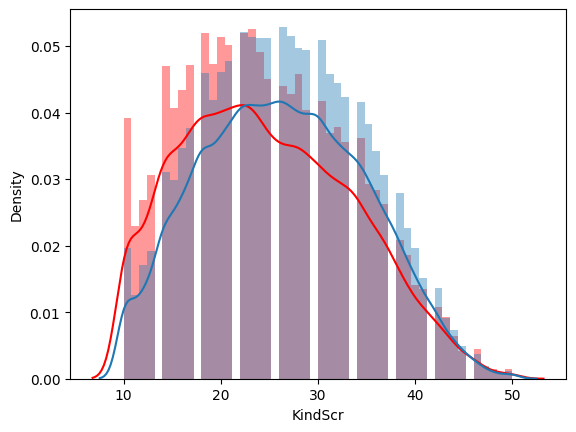

In [113]:
sns.distplot(df[df['IsLiar'] == 1]['KindScr'], color='red')
sns.distplot(df[df['IsLiar'] == 0]['KindScr'])

In [114]:
from scipy.stats import bootstrap

In [115]:
bootstrap((df['IsLiar'], ), statistic=np.mean, batch=100)

BootstrapResult(confidence_interval=ConfidenceInterval(low=np.float64(0.24969715942344597), high=np.float64(0.25407987009623995)), bootstrap_distribution=array([0.25329722, 0.25217433, 0.25235127, ..., 0.25292973, 0.25367832,
       0.25051381], shape=(9999,)), standard_error=np.float64(0.0011288582687794186))

In [116]:
kindness_liars_group = df[df['IsLiar'] == 1]['KindScr']
kindness_liars_samp_size = len(kindness_liars_group)

kindness_honst_group = df[df['IsLiar'] == 0]['KindScr']
kindness_honst_samp_size = len(kindness_honst_group)
t_stat, p_val_welch = sp.stats.mannwhitneyu(kindness_liars_group, kindness_honst_group)
# t_stat, p_val_welch = sps
print(f"Mann-Whitney test: p-value = {p_val_welch}, t-stat={t_stat}")

Mann-Whitney test: p-value = 3.922757948887428e-248, t-stat=1797164508.0


QQ Plot for kindness stats:

((array([-4.36674606, -4.16886963, -4.06127521, ...,  4.06127521,
          4.16886963,  4.36674606], shape=(109926,)),
  array([10., 10., 10., ..., 50., 50., 50.], shape=(109926,))),
 (np.float64(8.281772802834194),
  np.float64(26.394629114131327),
  np.float64(0.9937166208993861)))

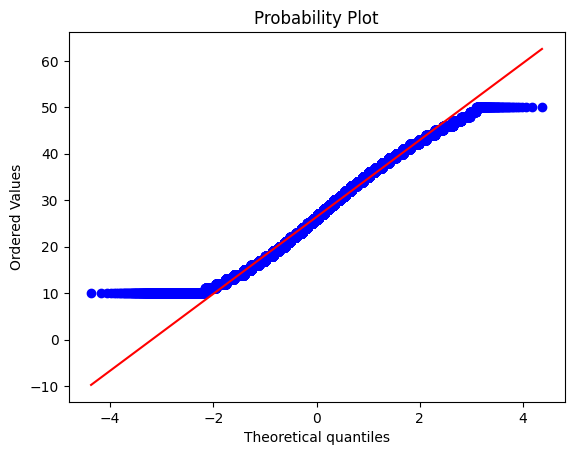

In [117]:
sp.stats.probplot(kindness_honst_group, plot=plt)

There're plateaus on the qqplot which show that the distributions differ from normal slightly. Therefore, it is better to prefer Mann Whitney test over the regular g-Hedges which assumes normality.

In [118]:
# kind_whitney_U, p_val_kind = sp.stats.mannwhitneyu(kindness_liars_group, kindness_honst_group)
# prob_super_kind = kind_whitney_U/(kindness_honst_samp_size * kindness_liars_samp_size)
# print(f'Probability of Superiority of liars to honest {round(prob_super_kind, 3)}, p-value: {p_val_kind}')
# print(pg.compute_effsize(kindness_liars_group, kindness_honst_group, eftype='hedges'))
print(f'Kindness honest mean: {round(kindness_honst_group.median(), 3)}, liars mean: {round(kindness_liars_group.median(), 3)}')

Kindness honest mean: 26.0, liars mean: 24.0


In [119]:
mach_liars = df[df['IsLiar'] == 1]['MachScr']
mach_liars_sample_size = len(mach_liars)

mach_honst = df[df['IsLiar'] == 0]['MachScr']
mach_honst_sample_size = len(mach_honst)

t_stat, p_val_welch = sp.stats.ttest_ind(mach_liars, mach_honst, equal_var=False)
print(f"Welch test: p-value = {p_val_welch}, t-stat={t_stat}")

Welch test: p-value = 2.2993746174552045e-223, t-stat=32.03575511428275


In [120]:
mach_whitney_U, p_val_mach = sp.stats.mannwhitneyu(mach_liars, mach_honst)
prob_super_mach = mach_whitney_U/(mach_honst_sample_size * mach_liars_sample_size)


print(f'Probability of Superiority of liars to honest {round(prob_super_mach, 3)}, p-value: {p_val_mach}')
print(f'Mach liars mean: {round(mach_liars.mean(), 3)}, honest mean: {round(mach_honst.mean(), 3)}')

Probability of Superiority of liars to honest 0.558, p-value: 6.800420560995353e-245
Mach liars mean: 30.573, honest mean: 28.911


As we can see, there're highly significant differences between liars and honest people, i.e. machiavellistic score goes up for liars while the overall kindness goes down. The differences are not really big though and expected.

#### RESUME: Liars and personal characteristics interactions

There is a difference between lying people and honest ones in terms of overall personal characteristic. The difference is statistically significant proven by Welch's test, the amplitude of the difference is measured by the Probability of Superiority calculated with U from significant Mann Whitney tests:
##### Kindness analysis
- For kindness group of questions Welch test: $p < .001, t=-32.2$ - distributions are different.
- For kindness group of questions the comparison of difference effect for liars to honest people distributions was conducted by Mann-Whitney's test with following results: $p < .001, \mathit{PS} = 0.442$ which means that if we pick a random person from a liars group, there's a 44.2% chance that they **score higher than the people from the honest group**, i.e. liars tend to answer slightly lower than the honest people. The difference isn't big, this fact is seen in mean comparison.
- Even though there's a a slight difference for the kindness measurement, it is small, which can be seen in means comparison: **Kindness honest group mean: 26.395, liars mean: 24.724**
##### Machiavllianism analysis
- For machiavllianism group of questions Welch test: $p < .001, t=32$ - distributions are different.
- For machiavllianism group of questions the comparison of difference effect for liars to honest people distributions was conducted by Mann-Whitney's test with following results: $p < .001, \mathit{PS} = 0.558$ which means that if we pick a random person from a liars group, there's a 55.8% chance that they **score higher than the people from the honest group**, i.e. liars tend to answer slightly higher than the honest people. The difference isn't big, this fact is seen in mean comparison: 
- Even though there's a a slight difference for the machivellianism measurement, it is small, which can be seen in means comparison: **Machivellianism honest group mean: 28.911, liars mean: 30.573**

##### Nota bene
The probability of superiority is somewhat **symmetrical** for kindness and machivellianism questions. For kindness a random liar scores lower with a $55.8$% chance ($1-0.442$ where 0.442 is the PS for liars over honest people), for machivellianism, a random liar scores higher with the same $55.8$% chance. Liars tend to be less kind the more they are machiavellianistic.

#### Liars and majors interactions.

Lets check the percentages of liars across different majors. For this we'll group the data by clusters and check the ratios of liars per cluster. The norm for the liars ratio will be the ratio of the overall population.

In [121]:
liars_clusters = df.groupby('cluster').IsLiar.agg(['sum', 'count'])
liars_clusters['ratio'] = liars_clusters['sum'] / liars_clusters['count'] 

In [122]:
norm_liar_ratio = df['IsLiar'].sum()/df['IsLiar'].count()
float(round(norm_liar_ratio, 3))

0.252

The liars are approx. the fourth of the overall population.

We'll group the LiarSum by clusters to see which clusters have the distributions of lying percentage that significantly differs from the main population. We'll use Welch's test to check for the distribution differences with $\alpha=.05$, after confirming differences we'll measure their amplitude with the probability of superiority i.e. $f=\frac{U}{n_1*n_2}$ where U is U_stat of Mann-Whitney test and $n_1$, $n_2$ are sample sizes. $f$ should be interpreted as follows: suppose there're two distributions. We'll randomly pick two measurements, one per distribution. The PoS will show the chance that the value from one distribution will be higher than the other. It works just like ROC-AUC because as it turns out **ROC-AUC is PoS**. So 0.5 means the distributions dont differ, 1 means that every value from one distribution will be bigger than in the other while negative one is counterwise.

In [123]:
print(round(norm_liar_ratio, 3))
data_liars_to_norm = []
for cluster in range(-1, 83):
    cluster_mask = df['cluster'] == cluster
    liars_sum_cluster = df[cluster_mask]['LiarSum']

    liars_sum_overall = df[~cluster_mask]['LiarSum']
    population_size = len(liars_sum_overall)

    u_stat, p_val_whit = sp.stats.mannwhitneyu(liars_sum_cluster, liars_sum_overall)
    sample_size = len(liars_sum_cluster)
    prob_of_super = u_stat/(sample_size * population_size)
    current_liars_ratio = liars_clusters.loc[cluster]['ratio']
    current_liars_count = liars_clusters.loc[cluster]['sum']
    current_overall_count = liars_clusters.loc[cluster]['count']
    if p_val_whit <= 0.05:
        # eff_size = pg.compute_effsize(liars_sum_cluster, liars_sum_overall, eftype='hedges')
        print(f'Cluster: {cluster} len: {sample_size}\t  Effects: p_val_mann: {round(p_val_whit, 2)}\t PoS: {round(prob_of_super, 3)}, ratio: {round(current_liars_ratio, 2)}')
        different = True
        # print(f'{round(liars_clusters.loc[cluster]['ratio'], 2)}\t{sp.stats.shapiro(liars_sum_cluster).pvalue}\t{profession(df, cluster, 1)}') # Using shapiro is unreliable here as it turns out
        # sp.stats.probplot(liars_sum_cluster, dist='norm', plot=axes[cluster+1])
    else:
        print(f'{red}Cluster: {cluster} len: {sample_size}\t  Effects: p_val_mann: {round(p_val_whit, 2)}\t PoS: {round(prob_of_super, 3)}, ratio: {round(current_liars_ratio, 2)}{rst}')
        different = False
    interval = prop.proportion_confint(count=current_liars_count, nobs=current_overall_count, alpha=0.05, method='wilson')
    if norm_liar_ratio > interval[0] and norm_liar_ratio < interval[1]:
        intersect = True
    else:
        intersect = False
    data_liars_to_norm.append([cluster, len(df[df['cluster'] == cluster]), p_val_whit, prob_of_super, current_liars_ratio, interval[0], interval[1], intersect, different])
# plt.tight_layout()
# plt.show()
liars_to_norm = pd.DataFrame(data_liars_to_norm, columns=['cluster', 'count', 'p_val_whit', 'PS', 'ratio', 'interval_zero', 'interval_one', 'intersect', 'isDifferent']).set_index('cluster')
liars_to_norm['major'] = [profession(df, e)[0] for e in liars_to_norm.index]

0.252
Cluster: -1 len: 123	  Effects: p_val_mann: 0.05	 PoS: 0.461, ratio: 0.18
Cluster: 0 len: 276	  Effects: p_val_mann: 0.0	 PoS: 0.558, ratio: 0.36
Cluster: 1 len: 78	  Effects: p_val_mann: 0.01	 PoS: 0.437, ratio: 0.13
Cluster: 2 len: 74	  Effects: p_val_mann: 0.0	 PoS: 0.427, ratio: 0.11
Cluster: 3 len: 50	  Effects: p_val_mann: 0.99	 PoS: 0.5, ratio: 0.24
Cluster: 4 len: 46	  Effects: p_val_mann: 0.15	 PoS: 0.547, ratio: 0.35
Cluster: 5 len: 1040	  Effects: p_val_mann: 0.02	 PoS: 0.516, ratio: 0.28
Cluster: 6 len: 288	  Effects: p_val_mann: 0.02	 PoS: 0.47, ratio: 0.2
Cluster: 7 len: 340	  Effects: p_val_mann: 0.59	 PoS: 0.506, ratio: 0.26
Cluster: 8 len: 1116	  Effects: p_val_mann: 0.8	 PoS: 0.498, ratio: 0.25
Cluster: 9 len: 10	  Effects: p_val_mann: 0.39	 PoS: 0.559, ratio: 0.4
Cluster: 10 len: 36	  Effects: p_val_mann: 0.92	 PoS: 0.496, ratio: 0.22
Cluster: 11 len: 96	  Effects: p_val_mann: 0.44	 PoS: 0.517, ratio: 0.29
Cluster: 12 len: 30	  Effects: p_val_mann: 0.11	 PoS: 0

In [124]:
rejected, corrected_p_vals, _, _ = multipletests(liars_to_norm['p_val_whit'], alpha=0.05, method="fdr_bh")

In [125]:
liars_to_norm['p_val_whit'] = corrected_p_vals
liars_to_norm['isDifferent'] = rejected
liars_to_norm['cliffDelta'] = (2*liars_to_norm['PS'])-1

In [126]:
liars_to_norm[liars_to_norm['isDifferent'] == True].sort_values('ratio')

,count,p_val_whit,PS,ratio,interval_zero,interval_one,intersect,isDifferent,major,cliffDelta
cluster,,,,,,,,,,
2,74,2.379122e-02,0.427195,0.108108,0.055807,0.199088,False,True,pedagogy,-0.145610
21,1310,1.369785e-10,0.458612,0.172519,0.153024,0.193929,False,True,Information Technology,-0.082775
37,1506,1.276599e-07,0.467553,0.188579,0.169624,0.209118,False,True,Electrical Engineering,-0.064894
53,1240,1.697687e-06,0.467281,0.188710,0.167905,0.211437,False,True,Mathematics,-0.065437
75,4658,8.277448e-19,0.469792,0.194504,0.183391,0.206121,False,True,Computer Science,-0.060417
82,5368,3.253952e-13,0.476491,0.206036,0.195428,0.217064,False,True,Engineering,-0.047018
78,17060,1.547370e-12,0.486711,0.229894,0.223642,0.236269,False,True,Business,-0.026579
80,23486,1.668469e-23,0.516247,0.279571,0.273868,0.285346,False,True,Psychology,0.032493
71,5903,4.992178e-13,0.522194,0.294088,0.282601,0.305842,False,True,Law,0.044388


In [127]:
with open('smth.csv', 'w') as f:
    liars_to_norm.to_csv(f)

In [128]:
profession(df, 21)

['Information Technology',
 'Technology',
 'Computing',
 'information technology',
 'Information technology']

<Axes: xlabel='PS', ylabel='Density'>

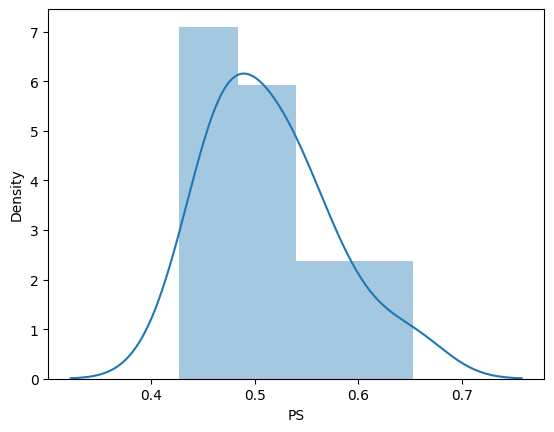

In [129]:
sns.distplot(liars_to_norm[liars_to_norm['isDifferent'] == True]['PS'])

In [130]:
liars_to_norm.sort_values(by=['PS'], ascending=False)['PS'].describe()

count    84.000000
mean      0.501263
std       0.045042
min       0.427195
25%       0.469762
50%       0.496212
75%       0.522349
max       0.652632
Name: PS, dtype: float64

In [131]:
# liars_to_norm.apply(abs).sort_values(by=['PS'], ascending=False)['PS'].head(10).plot(kind='barh').tick_params('y', rotation=45, size=10)

In [132]:
liars_to_norm[liars_to_norm['major'].str.contains('Edu')]

,count,p_val_whit,PS,ratio,interval_zero,interval_one,intersect,isDifferent,major,cliffDelta
cluster,,,,,,,,,,
50,2130,0.705416,0.503009,0.260094,0.241908,0.279144,True,False,Education,0.006017
51,12,0.642675,0.451251,0.166667,0.046965,0.448031,True,False,Educational sciences,-0.097498
52,32,0.090877,0.586214,0.437500,0.281653,0.606744,False,False,Science Education,0.172429


In [133]:
different_liars = liars_to_norm[liars_to_norm['isDifferent'] == True]
lower_bound = different_liars['PS'].quantile(.25)
upper_bound = different_liars['PS'].quantile(.75)

non_liars_mask = different_liars['PS'].lt(lower_bound)
norm_liars_mask = different_liars['PS'].between(lower_bound, upper_bound)
active_liars_mask = different_liars['PS'].gt(upper_bound)

non_liars = different_liars[non_liars_mask].sort_values(by='PS')
norm_liars = different_liars[norm_liars_mask].sort_values(by='PS')
active_liars = different_liars[active_liars_mask].sort_values(by='PS')

In [134]:
prop.proportion_confint(count=df['IsLiar'].sum(), nobs=df['IsLiar'].count(), alpha=0.05, method='wilson')

(0.24969582459028114, 0.2541349794925148)

In [135]:
non_liars

,count,p_val_whit,PS,ratio,interval_zero,interval_one,intersect,isDifferent,major,cliffDelta
cluster,,,,,,,,,,
2,74,2.379122e-02,0.427195,0.108108,0.055807,0.199088,False,True,pedagogy,-0.145610
21,1310,1.369785e-10,0.458612,0.172519,0.153024,0.193929,False,True,Information Technology,-0.082775
53,1240,1.697687e-06,0.467281,0.188710,0.167905,0.211437,False,True,Mathematics,-0.065437
37,1506,1.276599e-07,0.467553,0.188579,0.169624,0.209118,False,True,Electrical Engineering,-0.064894


In [136]:
norm_liars

,count,p_val_whit,PS,ratio,interval_zero,interval_one,intersect,isDifferent,major,cliffDelta
cluster,,,,,,,,,,
75,4658,8.277448e-19,0.469792,0.194504,0.183391,0.206121,False,True,Computer Science,-0.060417
82,5368,3.253952e-13,0.476491,0.206036,0.195428,0.217064,False,True,Engineering,-0.047018
78,17060,1.547370e-12,0.486711,0.229894,0.223642,0.236269,False,True,Business,-0.026579
80,23486,1.668469e-23,0.516247,0.279571,0.273868,0.285346,False,True,Psychology,0.032493
71,5903,4.992178e-13,0.522194,0.294088,0.282601,0.305842,False,True,Law,0.044388
48,870,4.339818e-03,0.525326,0.296552,0.267150,0.327742,False,True,Philosophy,0.050651
58,1256,4.405843e-05,0.528404,0.302548,0.277777,0.328523,False,True,Criminal Justice,0.056807


In [137]:
active_liars

,count,p_val_whit,PS,ratio,interval_zero,interval_one,intersect,isDifferent,major,cliffDelta
cluster,,,,,,,,,,
0,276,0.000101,0.557747,0.362319,0.307860,0.420558,False,True,&#24515;&#29702;&#23398;,0.115494
44,128,0.005150,0.564549,0.375000,0.295924,0.461360,False,True,Pre-Med,0.129098
68,64,0.002314,0.598299,0.437500,0.322940,0.559138,False,True,Health Administration,0.196598
81,36,0.000221,0.652632,0.555556,0.395811,0.704587,False,True,Architectural Engineering,0.305264


Conclusions per cluster.

For comparisons:
- General population ratio: $\text{ratio}\approx0.252$

For the people that don't lie:

- As expected, pedagogy comes FIRST with a $\text{PoS}= 0.427$ and a liar $\text{ratio}\approx0.11$. Using the 95% confidence interval, the ratio of liars in pedagogy doesnt include the normal ratio of the population. The $\delta_{cliff} = -0.14$ which is a small, almost negligeble but existant effect. Good and honest people
- Other majors show small differences, but they're negligeble.


For the normal group of liars that are different from the general population (the IQR group):
- All of the differences are negligeble with min(difference) = -0.06 (very slightly less lying) for Computer Science
- And max(difference) $\approx 0.06$ for Criminal Justice (very slightly more lying)

For the active liars group:
- The Chinese and Pre-Med groups show a light tendency to lie about their word knowledge more often.
- Chinese group: $\text{ratio}\approx0.36$; $95\% \text{CI}\space[0.30, 0.42]$; $\delta_{cliff} \approx 0.12$
- Pre-Med group: $\text{ratio}\approx0.38$; $95\% \text{CI}\space[0.30, 0.46]$; $\delta_{cliff} \approx 0.13$
- The Health Administrators has a borderline noticable difference $\delta_{cliff}\approx0.2$ to the lying side of the spectrum with $\text{ratio}\approx0.44$ and a confidence interval of $95\%\text{CI}\space [0.3, 0.46]$
- Architectural Engineering group are the absolute liars in relativity to other people: $\text{ratio}\approx0.56$; $95\% \text{CI}\space[0.40, 0,70]$ $\delta_{cliff} = 0.30$

I personally don't see a pattern in this data, the only thing that strucks the mind, is that all of those majors seem to involve interacting with people at some point, or they're about people overall.
- In pedagogy, you should be a great example to children, and it seems that most of teachers seem to follow the good trait of honesty.
- IT. Now here where the difference looks significant even from the point where the sample size isnt small. I dont know why

In [138]:
for cluster in norm_liars.index[len(norm_liars)//2-1: len(norm_liars)//2+2]:
    current_cluster = norm_liars.loc[cluster]
    print(f'{cluster}\tCount {current_cluster['count']}\t Ratio {round(current_cluster['ratio'], 3)}\t p_val_whit {current_cluster['p_val_whit']:.3f}\t PS {round(current_cluster['PS'], 3)}\t {profession(df, cluster, 1)[0]}')

78	Count 17060	 Ratio 0.23	 p_val_whit 0.000	 PS 0.487	 Business
80	Count 23486	 Ratio 0.28	 p_val_whit 0.000	 PS 0.516	 Psychology
71	Count 5903	 Ratio 0.294	 p_val_whit 0.000	 PS 0.522	 Law


Small deviations. Business unexpectedly tends to be more honest in terms of word knowledge, while psychologists and artists tend to be a little bit on a lying side of the spectrum.

In [139]:
for cluster in norm_liars.index[-5:]:
    current_cluster = norm_liars.loc[cluster]
    print(f'{cluster}\tCount {current_cluster['count']}\t Ratio {round(current_cluster['ratio'], 3)}\t p_val_whit {round(current_cluster['p_val_whit'],3):.3f}\t PS {round(current_cluster['PS'], 3)}\t {profession(df, cluster, 1)[0]}')

78	Count 17060	 Ratio 0.23	 p_val_whit 0.000	 PS 0.487	 Business
80	Count 23486	 Ratio 0.28	 p_val_whit 0.000	 PS 0.516	 Psychology
71	Count 5903	 Ratio 0.294	 p_val_whit 0.000	 PS 0.522	 Law
48	Count 870	 Ratio 0.297	 p_val_whit 0.004	 PS 0.525	 Philosophy
58	Count 1256	 Ratio 0.303	 p_val_whit 0.000	 PS 0.528	 Criminal Justice


In [140]:
for cluster in active_liars.index[-10:]:
    current_cluster = active_liars.loc[cluster]
    print(f'{cluster}\tCount {current_cluster['count']}\t Ratio {round(current_cluster['ratio'], 3)}\t p_val_whit {round(current_cluster['p_val_whit'],3):.3f}\t PS {round(current_cluster['PS'], 3)}\t {profession(df, cluster, 1)[0]}')

0	Count 276	 Ratio 0.362	 p_val_whit 0.000	 PS 0.558	 &#24515;&#29702;&#23398;
44	Count 128	 Ratio 0.375	 p_val_whit 0.005	 PS 0.565	 Pre-Med
68	Count 64	 Ratio 0.438	 p_val_whit 0.002	 PS 0.598	 Health Administration
81	Count 36	 Ratio 0.556	 p_val_whit 0.000	 PS 0.653	 Architectural Engineering


The majority of active liars are the groups of small amounts of people and dont seem to inspire a lot of trust. There're however interesting and probably explainable cases.

- **Cluster 0**, in which the embedder had facilitated **the Chinese people**. They tend to lie about word knowledge, probably because of the fact that english is not their native language, and thats why even unkown words that look english struck familiar. They're probably checked them just because of the gut sense.

It is interesting, that the architectural engineering cluster scores the HIGHEST amongst all lying people. I don't know why, but i have my doubt on significance of this difference due to a small amount of people in the group. it can be non-represantative of the whole majority of architects. Though it might be true that they tend to lie for some reason

# Major and personal characteristics interaction

#### Kindness and major interaction

In [141]:
norm_kindness = df['KindScr'].median()
interval = sp.stats.bootstrap(
            (df['KindScr'].to_numpy(),), 
            np.median,                
            confidence_level=0.95,    
            n_resamples=2000,        
            method='percentile'              
        )

In [142]:
norm_kindness
interval

BootstrapResult(confidence_interval=ConfidenceInterval(low=np.float64(26.0), high=np.float64(26.0)), bootstrap_distribution=array([26., 26., 26., ..., 26., 26., 26.], shape=(2000,)), standard_error=np.float64(0.0))

the norm kindness is equal to 26 confirmed 100% 

In [143]:
grouped_kindness_desc = df.groupby('cluster').describe()['KindScr']

In [144]:
norm_kindness_mw, kind_to_norm_mw = compare_to_norm('KindScr', criterion='mw')
# norm_kindness_tt, kind_to_norm_tt = compare_to_norm('KindScr', criterion='tt')

Cluster: -1 len: 123	  Effects: p_val_mann: 0.06	 PoS: 0.548, median: 27.0
Cluster: 0 len: 276	  Effects: p_val_mann: 0.07	 PoS: 0.531, median: 27.5
Cluster: 1 len: 78	  Effects: p_val_mann: 0.3	 PoS: 0.534, median: 28.0
Cluster: 2 len: 74	  Effects: p_val_mann: 0.4	 PoS: 0.528, median: 26.0
Cluster: 3 len: 50	  Effects: p_val_mann: 0.93	 PoS: 0.496, median: 26.0
Cluster: 4 len: 46	  Effects: p_val_mann: 0.0	 PoS: 0.693, median: 31.0
Cluster: 5 len: 1040	  Effects: p_val_mann: 0.0	 PoS: 0.54, median: 28.0
Cluster: 6 len: 288	  Effects: p_val_mann: 0.05	 PoS: 0.533, median: 27.0
Cluster: 7 len: 340	  Effects: p_val_mann: 0.0	 PoS: 0.572, median: 28.0
Cluster: 8 len: 1116	  Effects: p_val_mann: 0.0	 PoS: 0.458, median: 24.0
Cluster: 9 len: 10	  Effects: p_val_mann: 0.2	 PoS: 0.384, median: 22.0
Cluster: 10 len: 36	  Effects: p_val_mann: 0.65	 PoS: 0.522, median: 25.5
Cluster: 11 len: 96	  Effects: p_val_mann: 0.49	 PoS: 0.48, median: 25.5
Cluster: 12 len: 30	  Effects: p_val_mann: 0.02	 

In [145]:
kind_to_norm = kind_to_norm_mw[kind_to_norm_mw['isDifferent'] == True].sort_values('PS').drop('isDifferent', axis=1)
kind_to_norm['major'] = [profession(df, e, 1)[0] for e in kind_to_norm.index]

In [146]:
kind_to_norm.head()

,count,p_val_whit,PS,median,lftIntrv,rgtIntrv,cliffDelta,major
cluster,,,,,,,,
73,12,8.500499e-03,0.247457,19.5,16.0,22.0,-0.505086,business| english
14,10,3.194705e-02,0.270226,17.0,13.0,26.5,-0.459549,Occupational health and safety
71,5903,3.588867e-130,0.406259,22.0,22.0,23.0,-0.187483,Law
42,274,2.949342e-05,0.420744,23.0,21.0,24.0,-0.158512,Cyber Security
48,870,1.290081e-05,0.453363,24.0,24.0,25.0,-0.093275,Philosophy


In [147]:
kind_to_norm.loc[50]


count              2130
p_val_whit          0.0
PS             0.628954
median             30.0
lftIntrv           30.0
rgtIntrv           30.0
cliffDelta     0.257907
major         Education
Name: 50, dtype: object

In [148]:
non_kind_majors_bound, kind_majors_bound = kind_to_norm['PS'].quantile(.25), kind_to_norm['PS'].quantile(.75)

non_kind_majors_mask = kind_to_norm['PS'].le(non_kind_majors_bound)
neutr_kind_majors_mask = kind_to_norm['PS'].between(non_kind_majors_bound, kind_majors_bound, inclusive='neither')
kind_majors_mask = kind_to_norm['PS'].ge(kind_majors_bound)

non_kind_majors = kind_to_norm[non_kind_majors_mask]
neutr_kind_majors = kind_to_norm[neutr_kind_majors_mask]
kind_majors = kind_to_norm[kind_majors_mask]

In [149]:
print(profession(df, 71))
non_kind_majors[non_kind_majors['count'].gt(20)]

['Law', 'Political Science', 'law', 'Politics', 'political science']


,count,p_val_whit,PS,median,lftIntrv,rgtIntrv,cliffDelta,major
cluster,,,,,,,,
71,5903,3.588867e-130,0.406259,22.0,22.0,23.0,-0.187483,Law
42,274,2.949342e-05,0.420744,23.0,21.0,24.0,-0.158512,Cyber Security
48,870,1.290081e-05,0.453363,24.0,24.0,25.0,-0.093275,Philosophy
75,4658,7.036211e-25,0.454673,24.0,24.0,24.0,-0.090654,Computer Science
8,1116,8.786500e-06,0.457982,24.0,23.0,25.0,-0.084036,International Relations
26,55442,1.037755e-79,0.470373,25.0,25.0,25.0,-0.059254,Unknown


In [150]:
def comp_quartiles(cluster_id, feature_group, quartile=.5):
    """Returns: cluster_median, overall_median"""
    clust_mask = df['cluster'] == cluster_id

    cluster_quartile = pd.Series([float(df[clust_mask][q].quantile(quartile)) for q in feature_group]).median()
    overall_quartile = pd.Series([float(df[~clust_mask][q].quantile(quartile)) for q in feature_group]).median()
    return cluster_quartile, overall_quartile

In [151]:
df[df['cluster'] == 71]['KindScr'].quantile(0.75)

np.float64(29.0)

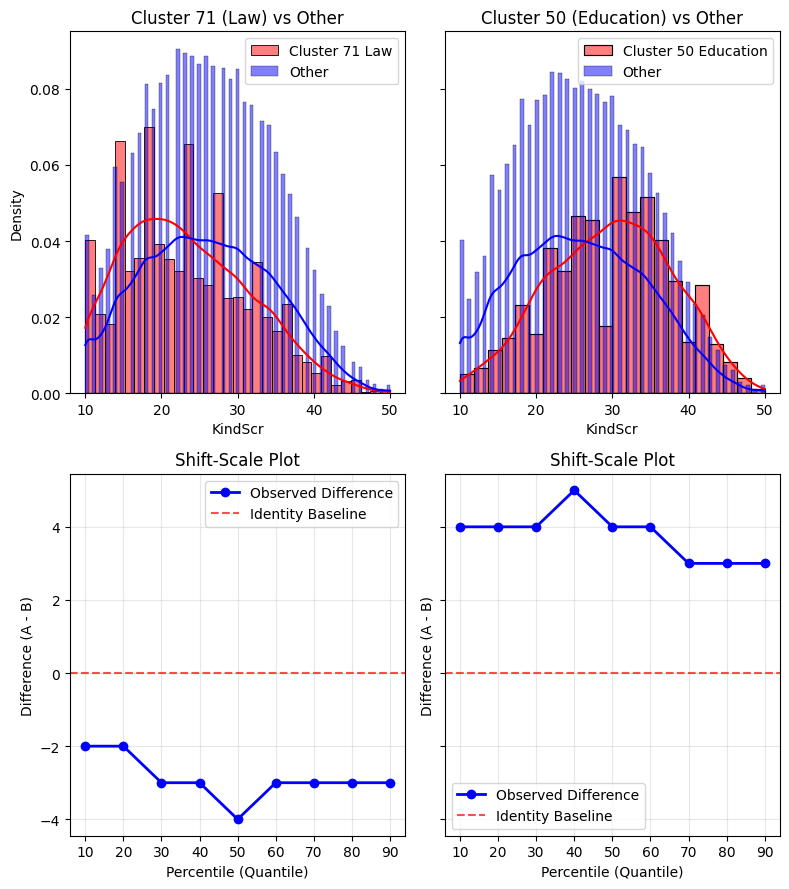

[]

In [152]:
clusters_to_plot = [71, 50]

shiftdist(feat_col='cluster', feat_col_vals=clusters_to_plot, feature='KindScr')

In [153]:
# comp_quartiles(np.array([1,2,3,4,5]), np.array([2,3,4,5,6]), quartile=0.5)

In [154]:
for cluster in clusters_to_plot:
    cluster_median, overall_median = comp_quartiles(cluster, questions_groups[1])
    cluster_3Q, overall_3Q = comp_quartiles(cluster, questions_groups[1], .75)
    print(f'{profession(df, cluster)[0]} median {cluster_median}, overall median {overall_median}\n{profession(df, cluster)[0]} 75% of answers: {cluster_3Q}, overall 75% of answers: {overall_3Q}\n')

Law median 2.0, overall median 2.0
Law 75% of answers: 3.75, overall 75% of answers: 4.0

Education median 3.0, overall median 2.0
Education 75% of answers: 4.0, overall 75% of answers: 4.0



`Median kindness = 26`

`Median kindness question answer = 2`

Note: out of **All of clusters in this group, ONLY the politicians scored less on a 75% answer (in points) for a random question from kindness category.** 75% answer means, that 75% and less of politicians answered this amount of points or less. 3.5 means, that their answer is between 3 and 4, which means that 75% of politicians tend to answer lower then 75% of ordinary people (which is ONLY the case with politicians, even in non-kind group)

##### Non-kind majors
**Cluster 71 "Law and politics"** 
- Scores absolute **WORST on the kindness metric**. Their *kindness median* is $95\%\text{CI}\space[22,23]$. The median is lower than that of general population by 3 to 4 points. 
- Politicians answer 2 on a kindness question in 50% of cases.
- In general, **comparing two random people from "Law and politics" group and "Every other kind of people",** the politicians **will score higher on kindness in 40% of cases**.
- **The effect size is small** with $\delta_{cliff}\approx-0.19$ but *consistent*. 
- The measured difference across deciles (overall difference, shift) equals to approx. 3 points, the difference spikes at the median to 4 points. As the difference is consistent and the median is approx. 23, we can say that at least **half of the politicians, answered 2 or 3 on EACH question**, which is either "*I dont care*" or "*I do not agree*" for <u>kindness</u> checking questions.


**Cluster 42 "Cybersec specialists"** 
- Scores **second on being the most non-kind cluster**. Their *kindness median* is $95\%\text{CI}\space[21,24]$. The median is lower than that of general population by 5 to 2 points.
- In general, **comparing two random people from "Cybersecurity" group and "Every other kind of people",** the sybersec **will score higher on kindness in 42% of cases**.
- **The effect size is small** with $\delta_{cliff}\approx-0.15$ but *consistent*. 
- The measured **difference** across deciles (overall difference, shift) **equals to approx. <u>2-3 points</u>**, the difference goes closer to normal (i.e. to 2 points in both cases) at the lowest (20 percent of most non-kind people) and highest (+-20% of the most kind people). Even with the fact stated, the difference is consistent and the median is approx. 23, we can say that at least **half of the sybersec specialists, answered 2 or 3 on EACH question**, which is either "*I dont care*" or "*I do not agree*" for <u>kindness</u> checking questions.

Analysis of other clusters in this group will be redundant, as the differences of other majors of the "negative" group are not for away from the general population.

In [155]:
neutr_kind_majors[neutr_kind_majors['count'].gt(20) & neutr_kind_majors['cliffDelta'].abs().gt(0.11)]

,count,p_val_whit,PS,median,lftIntrv,rgtIntrv,cliffDelta,major
cluster,,,,,,,,
29,224,4.247715e-03,0.562899,28.0,27.0,29.0,0.125799,Dentistry
65,156,1.537968e-02,0.564689,27.0,25.0,30.0,0.129379,Applied science
18,886,1.620465e-11,0.568741,28.0,27.0,28.0,0.137482,Environmental Science
7,340,2.384331e-05,0.572259,28.0,27.0,29.5,0.144517,Liberal Arts
24,94,2.709124e-02,0.577015,28.0,26.5,29.0,0.154030,Interior Design
55,106,9.641934e-03,0.583240,28.0,26.0,31.0,0.166479,Kinesiology
30,70,4.144648e-02,0.583256,29.0,26.0,31.0,0.166512,automotive engineering
27,98,2.060149e-03,0.601488,29.0,26.0,31.0,0.202976,Behavioral Science
68,64,1.338092e-02,0.602993,29.5,26.0,32.0,0.205986,Health Administration


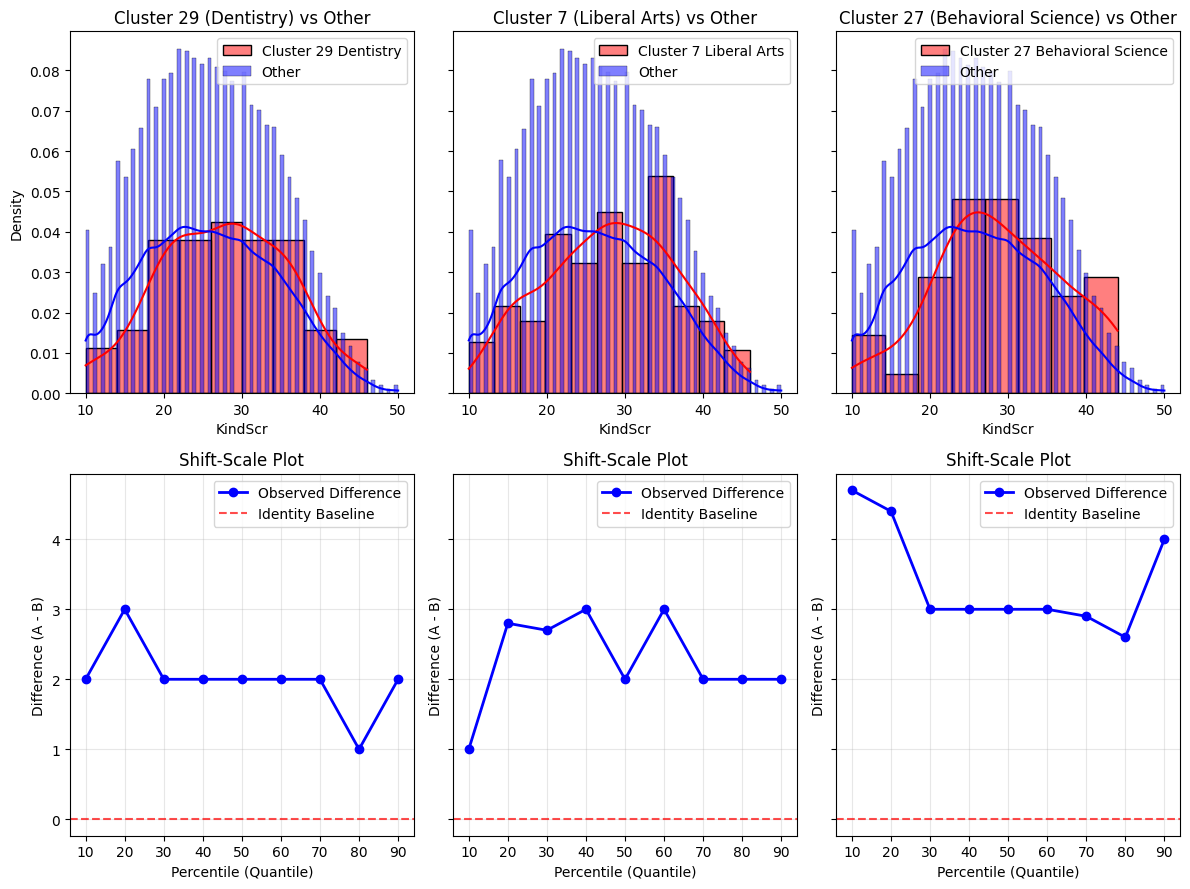

[]

In [156]:
clusters_to_plot = [29, 7, 27]


shiftdist(feat_col='cluster', feat_col_vals=clusters_to_plot, feature='KindScr')

In [157]:
print('Q2 and Q3 of an answer to a question from kindness category')
for cluster in clusters_to_plot:
    cluster_median, overall_median = comp_quartiles(cluster, questions_groups[1])
    cluster_3Q, overall_3Q = comp_quartiles(cluster, questions_groups[1], .75)
    print(f'{profession(df, cluster)[0]} median {cluster_median}, overall median {overall_median}\n{profession(df, cluster)[0]} 75% of answers: {cluster_3Q}, overall 75% of answers: {overall_3Q}\n')

Q2 and Q3 of an answer to a question from kindness category
Dentistry median 2.0, overall median 2.0
Dentistry 75% of answers: 4.0, overall 75% of answers: 4.0

Liberal Arts median 2.5, overall median 2.0
Liberal Arts 75% of answers: 4.0, overall 75% of answers: 4.0

Behavioral Science median 2.0, overall median 2.0
Behavioral Science 75% of answers: 4.0, overall 75% of answers: 4.0



`Kindness median = 26`

In the *neutral magnitude of difference group* we see:

**Cluster 29 "Dentistry"** (N = 224)
- Are more kind than the general public. Even though they dont even achieve maximum kindness score, on most of the occasions most of dentists answer 2 points more than a regular human.
- Scores significantly on the kindness metric. Their *kindness median* is $95\%\text{CI}\space[27, 29]$ with a central value of **28.0**. 
- In general, **comparing two random people from "Dentistry" group and "Every other kind of people",** the Dentistry group **will score higher on kindness in 56% of cases** (p-value: $4.20e-03$).
- **The effect size is small** with $\delta_{cliff}\approx 0.13$ but *consistent*.


**Cluster 7 "Liberal Arts"** (N = 340)
- Scores significantly on the kindness metric. Their *kindness median* is $95\%\text{CI}\space[27, 29]$ with a central value of **28.0**. 
- In general, **comparing two random people from "Liberal Arts" group and "Every other kind of people",** the Liberal Arts group **will score higher on kindness in 57% of cases** (p-value: $2.36e-05$).
- **The effect size is small** with $\delta_{cliff}\approx 0.14$ but *consistent*.
- Usually liberal arts majors **will score 2 to 3 point higher than a regular human**

**Cluster 27 "Behavioural Science"** (N = 98)
- Scores significantly on the kindness metric. Their *kindness median* is $95\%\text{CI}\space[26, 31]$ with a central value of **29.0**. 
- In general, **comparing two random people from "Behavioral Science" group and "Every other kind of people",** the Behavioral Science group **will score higher on kindness in 60% of cases** (p-value: $2.04e-03$).
- **The effect size is small** with $\delta_{cliff}\approx 0.20$ but *consistent*.
- Usually behavioural scientists score **3 points more than a regular person**

In [158]:
kind_majors[kind_majors['count'].gt(20)]

,count,p_val_whit,PS,median,lftIntrv,rgtIntrv,cliffDelta,major
cluster,,,,,,,,
23,40,2.188340e-02,0.621878,29.0,27.0,31.5,0.243756,Cosmetology
50,2130,1.423423e-91,0.628954,30.0,30.0,30.0,0.257907,Education
13,92,5.257032e-08,0.675339,30.5,29.0,33.0,0.350677,Speech Pathology
28,202,1.121962e-17,0.679627,32.0,31.0,33.0,0.359253,Counseling
4,46,2.949342e-05,0.693170,31.0,28.0,36.0,0.386340,Interdisciplinary Studies
16,36,1.570960e-06,0.749792,36.0,32.0,38.0,0.499584,Business mgt


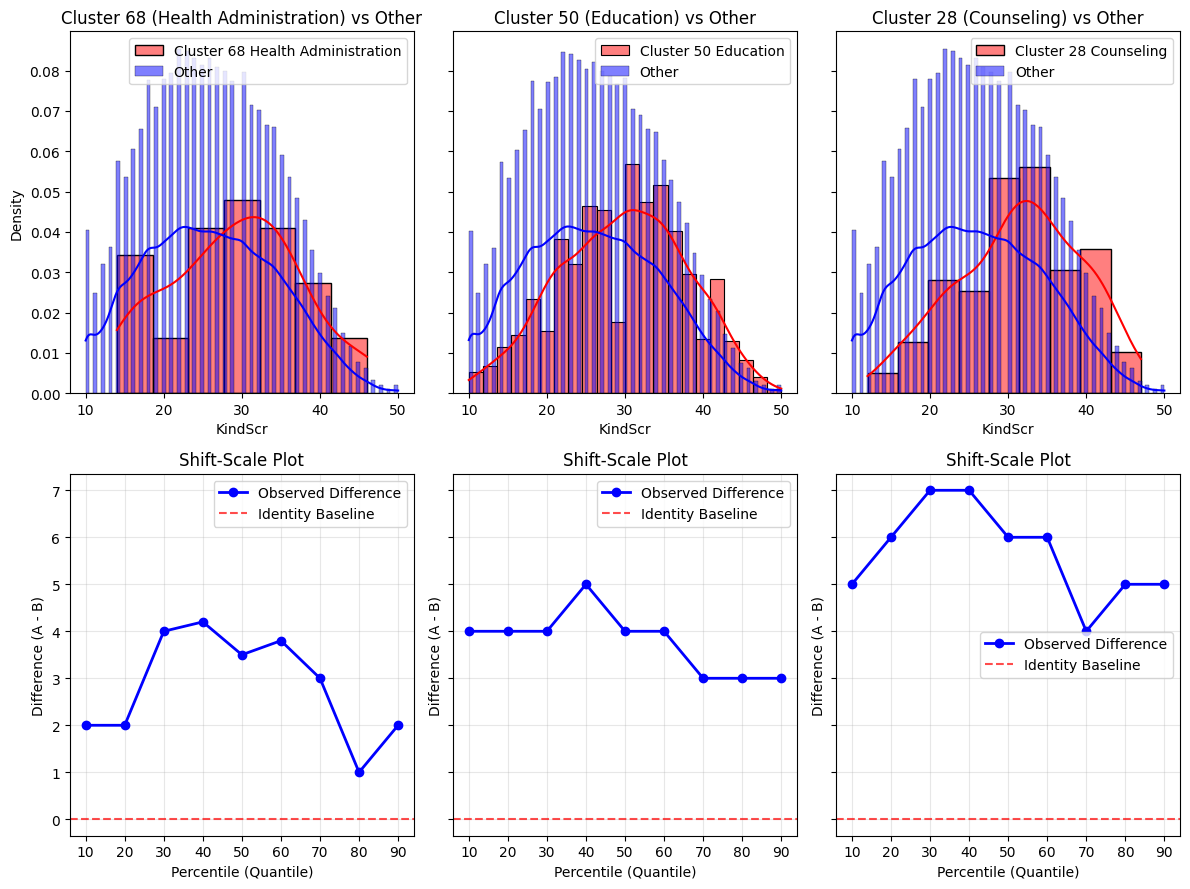

[]

In [159]:
clusters_to_plot = [68, 50, 28]

shiftdist(feat_col='cluster', feat_col_vals=clusters_to_plot, feature='KindScr')

In [160]:
print('Q2 and Q3 of an answer to a question from kindness category')
for cluster in clusters_to_plot:
    cluster_median, overall_median = comp_quartiles(cluster, questions_groups[1])
    cluster_3Q, overall_3Q = comp_quartiles(cluster, questions_groups[1], .75)
    print(f'{profession(df, cluster)[0]} median {cluster_median}, overall median {overall_median}\n{profession(df, cluster)[0]} 75% of answers: {cluster_3Q}, overall 75% of answers: {overall_3Q}\n')

Q2 and Q3 of an answer to a question from kindness category
Health Administration median 3.0, overall median 2.0
Health Administration 75% of answers: 4.5, overall 75% of answers: 4.0

Education median 3.0, overall median 2.0
Education 75% of answers: 4.0, overall 75% of answers: 4.0

Counseling median 3.5, overall median 2.0
Counseling 75% of answers: 4.0, overall 75% of answers: 4.0



`Kindness median = 26`

**Cluster 68 "Health Administration"** (N = 64)
- Scores significantly on the kindness metric. Their *kindness median* is $95\%\text{CI}\space[26, 32]$ with a central value of **29.5**. 
- In general, **comparing two random people from "Health Administration" group and "Every other kind of people",** the Health Administration group **will score higher on kindness in 60% of cases** (p-value: $1.32e-02$).
- **The effect size is small** with $\delta_{cliff}\approx 0.21$. The consistency of the difference is questionable. Though, the difference remains positive, the magnitude varies. I.e. top 20 most non-kind administrators still score 2 points more than a non-kind ordinary person. The man population of administrators, average administrators, tend to score not two but four points more than an average person. And when we come to the kindest 80-100% there's still a difference but it drops to 1 to 2 point.

**Cluster 50 "Education"** (N = 2130)
- Scores significantly on the kindness metric. Their *kindness median* is $95\%\text{CI}\space[30, 30]$ with a central value of **30.0**. 
- In general, **comparing two random people from "Education" group and "Every other kind of people",** the Education group **will score higher on kindness in 63% of cases** (p-value: $1.41e-91$).
- **The effect size is small** with $\delta_{cliff}\approx 0.26$ but *consistent*.
- Teachers usually score significantly (relative to other people) higher than the general population. First 60% of all measurements surpass the public by four points, and then in 70% to 100% the difference goes down to 3. This means that teachers on average choose an answer that is +3 from the answer that a regular person chose at least once. Or they could have chosen 3 answers and score one point more than regular people.
- Normal explanation: even the most non-kind teachers score 4 points more than the most non-kind average people. We can also see a spike on the 40th percentile, where a slightly less than average teacher scores not 4 but 5 points more than a slightly less than average person. 

**Cluster 28 "Counseling"** (N = 202)
- Scores significantly on the kindness metric. Their *kindness median* is $95\%\text{CI}\space[31, 33]$ with a central value of **32.0**. 
- In general, **comparing two random people from "Counseling" group and "Every other kind of people",** the Counseling group **will score higher on kindness in 68% of cases** (p-value: $1.11e-17$).
- **The effect size is medium** with $\delta_{cliff}\approx 0.36$.
- The least kind 20 percents of counselors score from 5 to 7 points more than the least 20 percents of the public. The difference remains for 30% to 40% of "less than average" counselors (they tend to be extremely more positive in this category). Than, the "average and slightly more than average" group countinues the tendency to be more kind than the general public with +6 points (which is two almost absolutely positive answers for kindness, as the median for answer in this place is 2)

As for the buiseness management. I think, that the current size of buiseness management sample is too small to talk about hte overall picture of people of that profession. Even more, their kind portrait looks suspicious, as managers and people from buiseness tend to be on a machiavellianistic side of the spectrum (which is even logical if you think about it for a moment). Therefore we will omit the analysis of this cluster.

<Axes: xlabel='KindScr', ylabel='Density'>

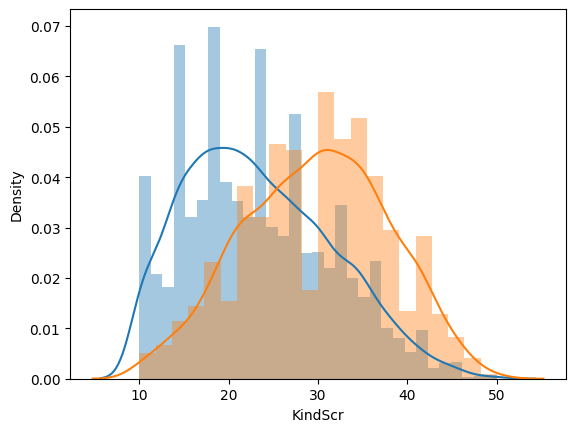

In [161]:
sns.distplot(df[df['cluster'] == 71]['KindScr']) # LAW AND POLITICS
sns.distplot(df[df['cluster'] == 50]['KindScr']) # EDUCATION

Comparative plot of densities of kindness scores for one of the most kind and the least kindest clusters. The shift is clearly seen.

#### Machivellianism and major interaction

In [162]:
norm_mach = df['MachScr'].median()

In [163]:
norm_mach

np.float64(30.0)

In [164]:
grouped_mach_desc = df.groupby('cluster').describe()['MachScr']

In [165]:
grouped_mach_desc.sort_values('50%').head(10)

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
16,36.0,20.277778,8.027137,9.0,15.00,19.0,25.00,37.0
43,8.0,19.500000,3.891382,15.0,16.50,19.5,22.50,24.0
28,202.0,22.554455,8.062536,9.0,16.00,21.0,29.00,42.0
4,46.0,23.913043,9.077019,11.0,14.75,22.0,33.25,40.0
27,98.0,23.183673,9.287334,9.0,16.00,22.0,31.00,44.0
13,92.0,22.326087,7.594256,10.0,17.00,22.0,27.00,41.0
38,20.0,24.300000,7.908024,10.0,21.00,23.0,28.00,38.0
55,106.0,24.811321,8.521249,11.0,19.00,23.0,28.00,43.0
51,12.0,25.500000,4.852366,19.0,23.00,24.5,28.00,34.0


In [166]:
grouped_mach_desc.sort_values('50%').tail(10)

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
36,12.0,33.000000,3.765875,29.0,29.0,32.5,36.0,39.0
42,274.0,31.664234,7.816839,10.0,27.0,33.0,37.0,45.0
35,74.0,28.783784,10.528852,9.0,19.0,33.0,37.0,44.0
33,26.0,31.461538,5.508036,18.0,30.0,33.0,34.0,41.0
9,10.0,32.600000,3.627059,28.0,30.0,33.0,34.0,38.0
60,154.0,30.597403,8.405196,10.0,26.0,33.0,36.0,45.0
46,20.0,30.100000,9.452930,13.0,28.0,33.5,35.0,41.0
56,28.0,31.500000,7.941919,19.0,23.0,34.0,36.0,44.0
76,26.0,30.461538,9.900427,13.0,24.0,34.0,35.0,45.0


In [167]:
mach_norm, mach_to_norm = compare_to_norm('MachScr', criterion='mw')

Cluster: -1 len: 123	  Effects: p_val_mann: 0.0	 PoS: 0.424, median: 27.0
Cluster: 0 len: 276	  Effects: p_val_mann: 0.47	 PoS: 0.512, median: 30.0
Cluster: 1 len: 78	  Effects: p_val_mann: 0.4	 PoS: 0.528, median: 29.0
Cluster: 2 len: 74	  Effects: p_val_mann: 0.07	 PoS: 0.439, median: 26.0
Cluster: 3 len: 50	  Effects: p_val_mann: 0.33	 PoS: 0.461, median: 29.0
Cluster: 4 len: 46	  Effects: p_val_mann: 0.0	 PoS: 0.334, median: 22.0
Cluster: 5 len: 1040	  Effects: p_val_mann: 0.0	 PoS: 0.471, median: 29.0
Cluster: 6 len: 288	  Effects: p_val_mann: 0.0	 PoS: 0.428, median: 28.0
Cluster: 7 len: 340	  Effects: p_val_mann: 0.0	 PoS: 0.422, median: 27.0
Cluster: 8 len: 1116	  Effects: p_val_mann: 0.0	 PoS: 0.552, median: 32.0
Cluster: 9 len: 10	  Effects: p_val_mann: 0.24	 PoS: 0.607, median: 33.0
Cluster: 10 len: 36	  Effects: p_val_mann: 0.24	 PoS: 0.557, median: 31.0
Cluster: 11 len: 96	  Effects: p_val_mann: 0.24	 PoS: 0.465, median: 28.0
Cluster: 12 len: 30	  Effects: p_val_mann: 0.01

KeyboardInterrupt: 

In [ ]:
mach_to_norm['major'] = [profession(df, e)[0] for e in mach_to_norm.index]
mach_to_norm = mach_to_norm[mach_to_norm['isDifferent']]

In [ ]:
mach_to_norm = mach_to_norm.sort_values(by=['PS', 'median'])

In [ ]:
mach_to_norm.head(10)

,count,p_val_whit,PS,median,lftIntrv,rgtIntrv,isDifferent,cliffDelta,major
cluster,,,,,,,,,
43,8,3.677678e-03,0.164540,19.5,15.0,24.0,True,-0.670920,Theater and Communication
16,36,5.557842e-08,0.223174,19.0,16.0,23.0,True,-0.553652,Business mgt
13,92,2.013577e-13,0.270093,22.0,20.0,23.0,True,-0.459814,Speech Pathology
28,202,9.262784e-26,0.282123,21.0,19.0,22.0,True,-0.435754,Counseling
27,98,1.602384e-09,0.314756,22.0,19.0,25.0,True,-0.370487,Behavioral Science
38,20,2.554267e-02,0.332499,23.0,21.0,28.0,True,-0.335002,gender studies
4,46,4.022459e-04,0.334027,22.0,19.0,26.0,True,-0.331947,Interdisciplinary Studies
55,106,2.730594e-07,0.346715,23.0,21.0,25.0,True,-0.306570,Kinesiology
12,30,1.677280e-02,0.354633,25.0,21.5,29.5,True,-0.290735,Communication Disorders


In [ ]:
non_mach_majors_bound, mach_majors_bound = mach_to_norm['PS'].quantile(.25), mach_to_norm['PS'].quantile(.75)

non_mach_majors_mask = mach_to_norm['PS'].le(non_mach_majors_bound)
neutr_mach_majors_mask = mach_to_norm['PS'].between(non_mach_majors_bound, mach_majors_bound, inclusive='neither')
mach_majors_mask = mach_to_norm['PS'].ge(mach_majors_bound)

non_mach_majors = mach_to_norm[non_mach_majors_mask]
neutr_mach_majors = mach_to_norm[neutr_mach_majors_mask]
mach_majors = mach_to_norm[mach_majors_mask]

##### Non-mach majors

In [ ]:
non_mach_majors[non_mach_majors['count'].gt(20)]

,count,p_val_whit,PS,median,lftIntrv,rgtIntrv,isDifferent,cliffDelta,major
cluster,,,,,,,,,
16,36,5.557842e-08,0.223174,19.0,16.0,23.0,True,-0.553652,Business mgt
13,92,2.013577e-13,0.270093,22.0,20.0,23.0,True,-0.459814,Speech Pathology
28,202,9.262784e-26,0.282123,21.0,19.0,22.0,True,-0.435754,Counseling
27,98,1.602384e-09,0.314756,22.0,19.0,25.0,True,-0.370487,Behavioral Science
4,46,4.022459e-04,0.334027,22.0,19.0,26.0,True,-0.331947,Interdisciplinary Studies
55,106,2.730594e-07,0.346715,23.0,21.0,25.0,True,-0.306570,Kinesiology
12,30,1.677280e-02,0.354633,25.0,21.5,29.5,True,-0.290735,Communication Disorders


In [ ]:
print(f'Intersection\t {np.intersect1d(kind_majors.index, non_mach_majors.index)}')
print(f'Unique kind\t {np.setdiff1d(kind_majors.index, non_mach_majors.index)} ')
print(f'Unique mach\t {np.setdiff1d(non_mach_majors.index, kind_majors.index)}')

Intersection	 [ 4 13 16 28 43]
Unique kind	 [23 47 50] 
Unique mach	 [12 27 38 55]


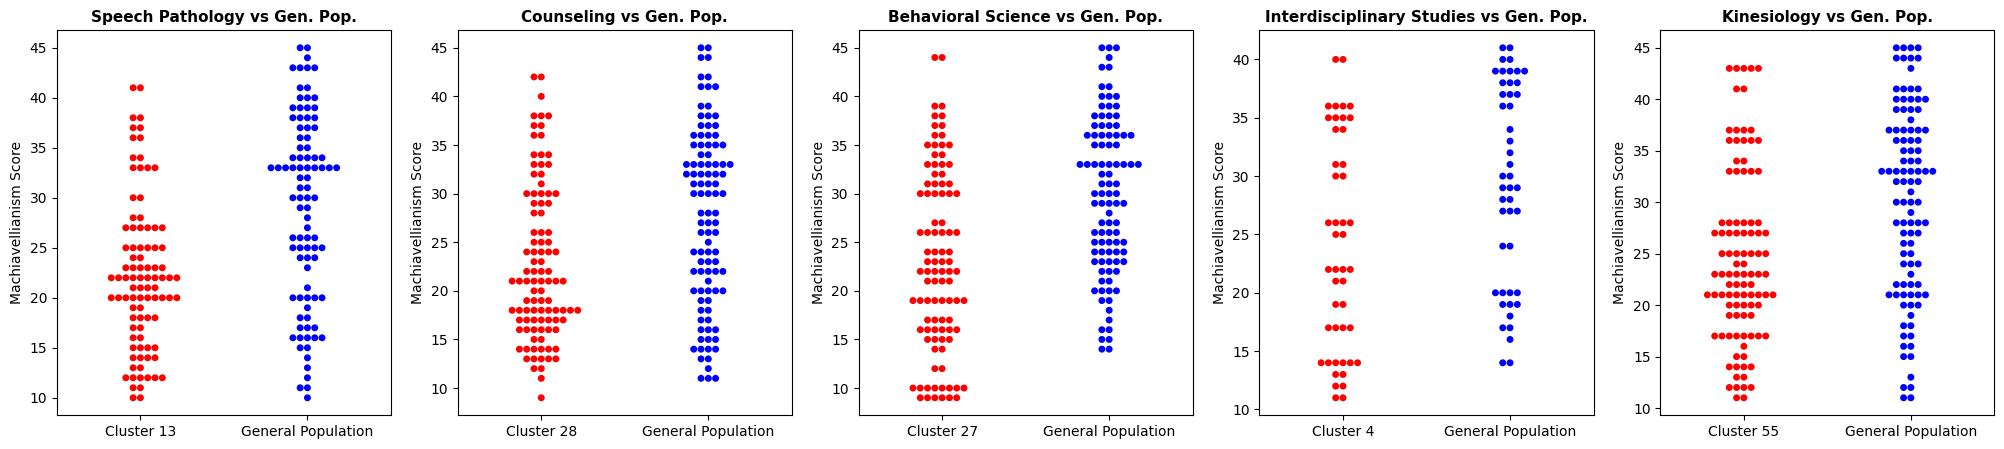

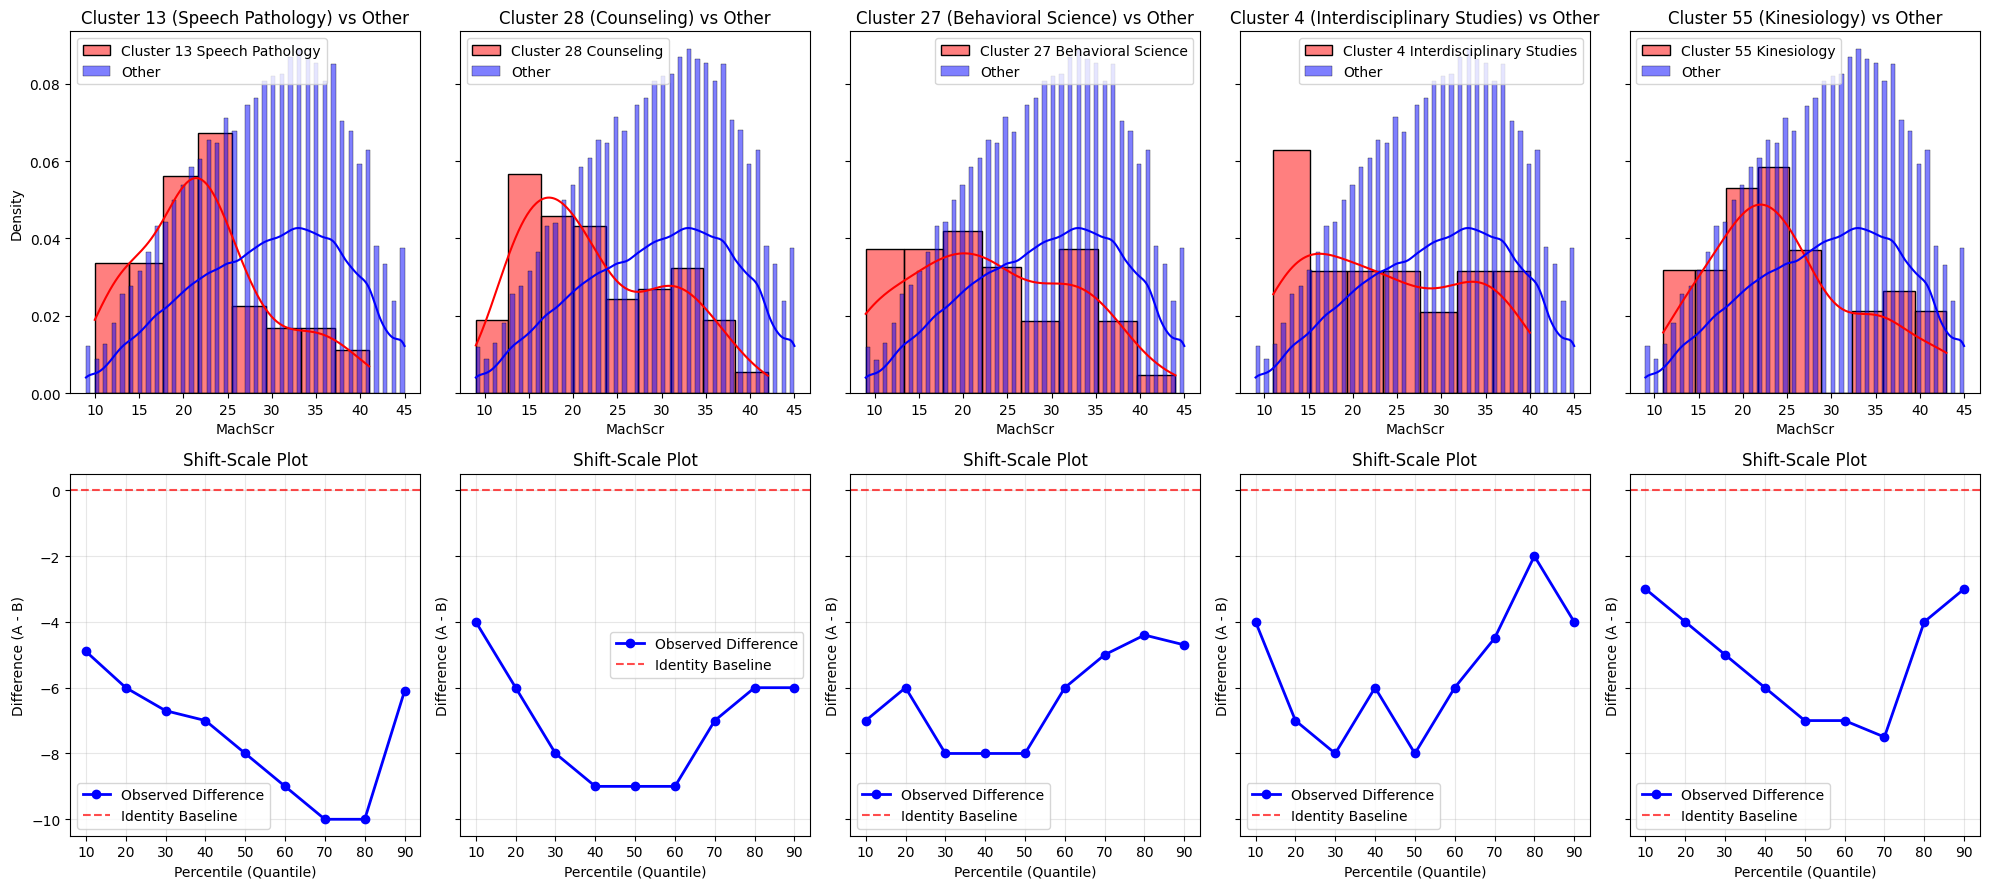

[]

In [ ]:
clusters_to_plot = [13, 28, 27, 4, 55]
# pd.concat([df[df['cluster'] == 28]['MachScr'], df[df['cluster'] == 28]['KindScr']], axis=1).corr()
# pd.concat([df['MachScr'], df['KindScr']], axis=1).corr()
num_clusters = len(clusters_to_plot)

fig, axes = plt.subplots(nrows=1, ncols=num_clusters, figsize=(5 * num_clusters, 5), squeeze=False)
axes = axes.flatten()

for i, cluster_id in enumerate(clusters_to_plot):
    ax_shift = axes[i]
    
    cluster_data = df[df['cluster'] == cluster_id]['MachScr'].to_frame()
    cluster_data['Group'] = f'Cluster {cluster_id}'
    
    if len(cluster_data) > 100:
        cluster_data, _ = train_test_split(cluster_data, train_size=100, random_state=42)
    
    gp_data = df[df['cluster'] != cluster_id]['MachScr'].to_frame()
    gp_data['Group'] = 'General Population'
    
    if len(gp_data) > len(cluster_data):
        gp_data, _ = train_test_split(gp_data, train_size=len(cluster_data), random_state=42)
        
    plot_df = pd.concat([cluster_data, gp_data], axis=0)
    
    sns.swarmplot(
        data=plot_df, 
        x='Group', 
        y='MachScr', 
        hue='Group', 
        palette={'General Population': 'blue', f'Cluster {cluster_id}': 'red'},
        ax=ax_shift,
        legend=False
    )
    
    prof_name = profession(df, cluster_id)[0]
    ax_shift.set_title(f'{prof_name} vs Gen. Pop.', size=11, weight='bold')
    ax_shift.set_xlabel('')
    ax_shift.set_ylabel('Machiavellianism Score')


shiftdist(feat_col='cluster', feat_col_vals=clusters_to_plot, feature='MachScr')

In [ ]:
print(generate_report(non_mach_majors.loc[27]))

**Cluster 27 "Behavioral Science"** (N = 98)
- Scores significantly on the Machivellianism metric. Their *machivellianism median* is $95\%\text{CI}\space[19, 25]$ with a central value of **22.0**. 
- In general, **comparing two random people from "Behavioral Science" group and "Every other kind of people",** the Behavioral Science group **will score higher on machivellianism in 31% of cases** (p-value: $1.60e-09$).
- **The effect size is medium** with $\delta_{cliff}\approx -0.37$.



In [ ]:
df['MachScr'].min(), df[df['cluster']==13]['MachScr'].quantile(.8), df[df['cluster']==71]['MachScr'].quantile(.8), df['MachScr'].max()

(np.float64(9.0), np.float64(27.0), np.float64(39.0), np.float64(45.0))

`Population median mach = 30`

**Cluster 13 "Speech Pathology"** (N = 92)
- Scores significantly lower on the Machivellianism metric. Their *machivellianism median* is $95\%\text{CI}\space[20, 23]$ with a central value of **22.0**. 
- In general, **comparing two random people from "Speech Pathology" group and "Every other kind of people",** the Speech Pathology group **will score higher on machivellianism in 27% of cases** (p-value: $2.24e-13$).
- **The effect size is medium** with $\delta_{cliff}\approx -0.46$.
- We can also see a confidently descending shift-scale plot, which means, that with the score rising, the gap between machivellianistic metrics of general population (gp. for short further) and speech pathologists (sp. for short further) increases significantly. The first twenty percent of the most non-mach sp. and non-mach gp. have a gap of 5-6 points, where sp. tends to score lower. The next 30-70% "moderatly mach sp." score from 7 to whopping 10 points lower than the "moderatly mach gp.". The difference is the same for the "mach sp.": 10 points. Then, the difference drops to 6 points at the "most mach sp." which probably shows us, that the machiavellianistic people tend to be like each other, despite professional differences( we see the same picture in every other profession, the difference lowers at the maximal percent.)

**Cluster 28 "Counseling"** (N = 202)
- Scores significantly lower on the Machivellianism metric. Their *machivellianism median* is $95\%\text{CI}\space[19, 22]$ with a central value of **21.0**. 
- In general, **comparing two random people from "Counseling" group and "Every other kind of people",** the Counseling group **will score higher on machivellianism in 28% of cases** (p-value: $1.07e-25$).
- **The effect size is medium** with $\delta_{cliff}\approx -0.44$.
- The shift-scale plot is vastly descending from 0 to 30 percent, then it is stable for 40-60% and then rises at the top 70-100%. It means, that the first non-mach part (0-30%) is deviating from the main group more the more points they score on the metric, while the 10% mach is only four points away from the gp. the 30% power mach cs. (Counselling for short) are already 8 points away from the general population. Then, they're $\approx9$ points less mach then the gp. When we get to the most mach part of cs. 70-100% they start to approach the gp. (7 at 70%, 6 at 80-100%). They're closer to gp. but still are significantly lower.

**Cluster 27 "Behavioral Science"** (N = 98)
- Scores significantly lower on the Machivellianism metric. Their *machivellianism median* is $95\%\text{CI}\space[20, 26]$ with a central value of **22.0**. 
- In general, **comparing two random people from "Behavioral Science" group and "Every other kind of people",** the Behavioral Science group **will score higher on machivellianism in 31% of cases** (p-value: $1.74e-09$).
- **The effect size is medium** with $\delta_{cliff}\approx -0.37$.
- The picture of shift scale is almost the same as for the counselling. The first low mach part of bs. is 7 point away from the main population. The 20% mach are 6 points, then, for the 30-50% score mach the difference is 8 points. The shift grows smaller with every proceeding quantile: 60% - 6, 70% - 5, 80 $\approx$ 4.5, 90 $\approx$ 4.5

##### Neutrally machivellianistic majors

In [ ]:
neutr_mach_majors

,count,p_val_whit,PS,median,lftIntrv,rgtIntrv,isDifferent,cliffDelta,major
cluster,,,,,,,,,
50,2130,2.243764e-115,0.355313,25.0,24.0,25.0,True,-0.289375,Education
45,44,1.102814e-02,0.373146,25.5,21.0,29.5,True,-0.253707,Landscape Architecture
7,340,3.177602e-06,0.421839,27.0,25.0,28.0,True,-0.156322,Liberal Arts
-1,123,1.078875e-02,0.423625,27.0,25.0,30.0,True,-0.152750,Fashion Merchandising
24,94,3.100746e-02,0.425692,26.0,23.0,30.0,True,-0.148615,Interior Design
18,886,3.420577e-13,0.426513,27.0,27.0,28.0,True,-0.146973,Environmental Science
6,288,9.641901e-05,0.427546,28.0,27.0,29.5,True,-0.144908,Geography
61,6650,1.120959e-78,0.431421,28.0,27.0,28.0,True,-0.137159,Music
77,304,6.156720e-04,0.437309,27.0,25.0,29.0,True,-0.125382,Social Science


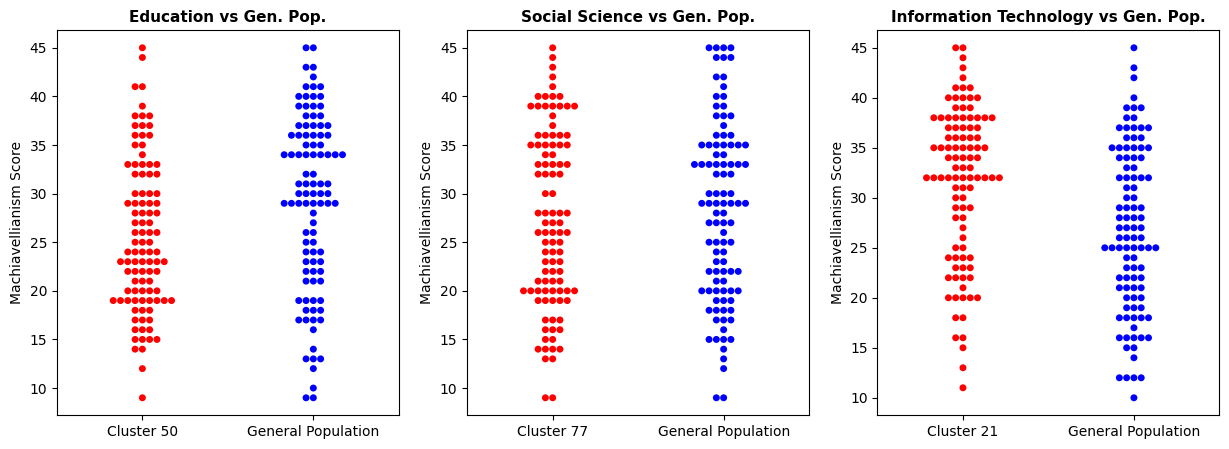

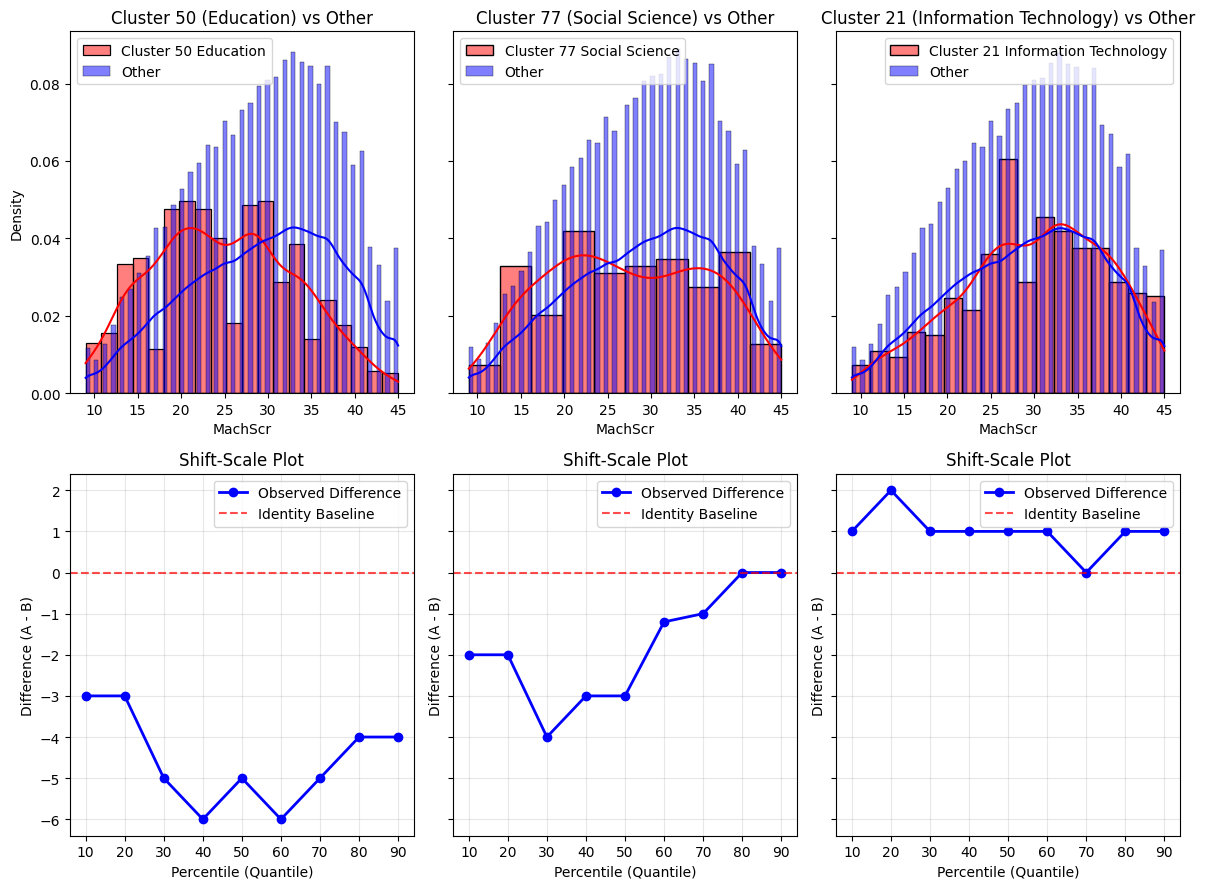

[]

In [ ]:
clusters_to_plot = [50, neutr_mach_majors.index[len(neutr_mach_majors.index)//2], 21]
num_clusters = len(clusters_to_plot)

fig, axes = plt.subplots(nrows=1, ncols=num_clusters, figsize=(5 * num_clusters, 5), squeeze=False)
axes = axes.flatten()

for i, cluster_id in enumerate(clusters_to_plot):
    ax_shift = axes[i]
    
    cluster_data = df[df['cluster'] == cluster_id]['MachScr'].to_frame()
    cluster_data['Group'] = f'Cluster {cluster_id}'
    
    if len(cluster_data) > 100:
        cluster_data, _ = train_test_split(cluster_data, train_size=100, random_state=42)
    
    gp_data = df[df['cluster'] != cluster_id]['MachScr'].to_frame()
    gp_data['Group'] = 'General Population'
    
    if len(gp_data) > len(cluster_data):
        gp_data, _ = train_test_split(gp_data, train_size=len(cluster_data), random_state=42)
        
    plot_df = pd.concat([cluster_data, gp_data], axis=0)
    
    sns.swarmplot(
        data=plot_df, 
        x='Group', 
        y='MachScr', 
        hue='Group', 
        palette={'General Population': 'blue', f'Cluster {cluster_id}': 'red'},
        ax=ax_shift,
        legend=False
    )
    
    prof_name = profession(df, cluster_id)[0]
    ax_shift.set_title(f'{prof_name} vs Gen. Pop.', size=11, weight='bold')
    ax_shift.set_xlabel('')
    ax_shift.set_ylabel('Machiavellianism Score')

shiftdist(feat_col='cluster', feat_col_vals=clusters_to_plot, feature='MachScr')

In [ ]:
print(generate_report(neutr_mach_majors.loc[21]))

**Cluster 21 "Information Technology"** (N = 1310)
- Scores significantly on the Machivellianism metric. Their *machivellianism median* is $95\%\text{CI}\space[30, 32]$ with a central value of **31.0**. 
- In general, **comparing two random people from "Information Technology" group and "Every other kind of people",** the Information Technology group **will score higher on machivellianism in 52% of cases** (p-value: $2.89e-02$).
- **The effect size is negligible** with $\delta_{cliff}\approx 0.04$.



**Cluster 50 "Education"** (N = 2130)
- Usually scores slightly lower than normal on the Machivellianism metric. Their *machivellianism median* is $95\%\text{CI}\space[24, 25]$ with a central value of **25.0**. 
- In general, **comparing two random people from "Education" group and "Every other kind of people",** the Education group **will score higher on machivellianism in 36% of cases** (p-value: $2.22e-115$).
- **The effect size is small** with $\delta_{cliff}\approx -0.29$.
- One of the highest on kindness majors. The first 20% score mach score 3 points lower. Then the difference is as follows: 30%: -5, 40%: -6, 50%: -5, 60%: -6, 70%: -5, 80%: -4, 90%: -4.

**Cluster 61 "Music"** (N = 6650)
- Usually scores slightly lower than normal on the Machivellianism metric. Their *machivellianism median* is $95\%\text{CI}\space[27, 28]$ with a central value of **28.0**. 
- In general, **comparing two random people from "Music" group and "Every other kind of people",** the Music group **will score higher on machivellianism in 43% of cases** (p-value: $1.11e-78$).
- **The effect size is small** with $\delta_{cliff}\approx -0.14$.

**Cluster 21 "Information Technology"** (N = 1310)
- Scores sligthly higher on the Machivellianism metric. Their *machivellianism median* is $95\%\text{CI}\space[30, 32]$ with a central value of **31.0**. 
- In general, **comparing two random people from "Information Technology" group and "Every other kind of people",** the Information Technology group **will score higher on machivellianism in 52% of cases** (p-value: $2.94e-02$).
- **The effect size is negligible** with $\delta_{cliff}\approx 0.04$.
- The difference between it. and gp. is mainly 1 point higher than average, with exceptions at 30% mach score which is 2 points higher and at 70%, which are just like the general population.

##### Machivellianistic majors

In [ ]:
mach_majors[mach_majors['count'].gt(30)]

,count,p_val_whit,PS,median,lftIntrv,rgtIntrv,isDifferent,cliffDelta,major
cluster,,,,,,,,,
75,4658,6.566923e-07,0.522759,31.0,31.0,31.0,True,0.045518,Computer Science
59,840,2.199606e-02,0.526538,31.0,30.0,32.0,True,0.053075,Architecture
26,55442,3.326799e-174,0.543936,31.0,31.0,31.0,True,0.087872,Unknown
8,1116,1.718463e-08,0.551708,32.0,31.0,33.0,True,0.103416,International Relations
82,5368,2.179595e-37,0.552080,32.0,31.0,32.0,True,0.104159,Engineering
71,5903,1.739021e-64,0.565624,32.0,32.0,33.0,True,0.131248,Law
42,274,1.278845e-05,0.582015,33.0,32.0,34.0,True,0.164030,Cyber Security
17,146,1.841374e-03,0.583384,32.0,30.0,34.0,True,0.166768,Materials Engineering


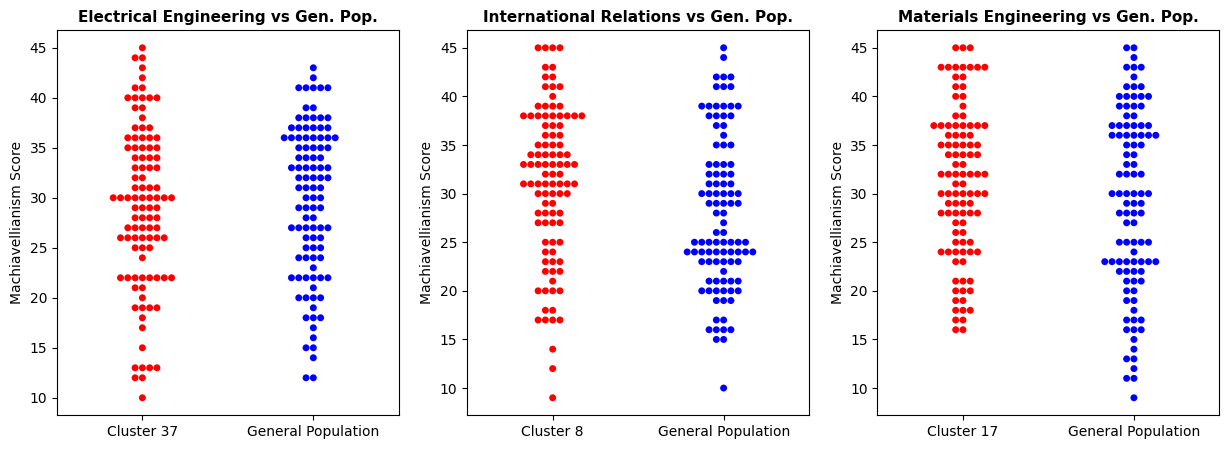

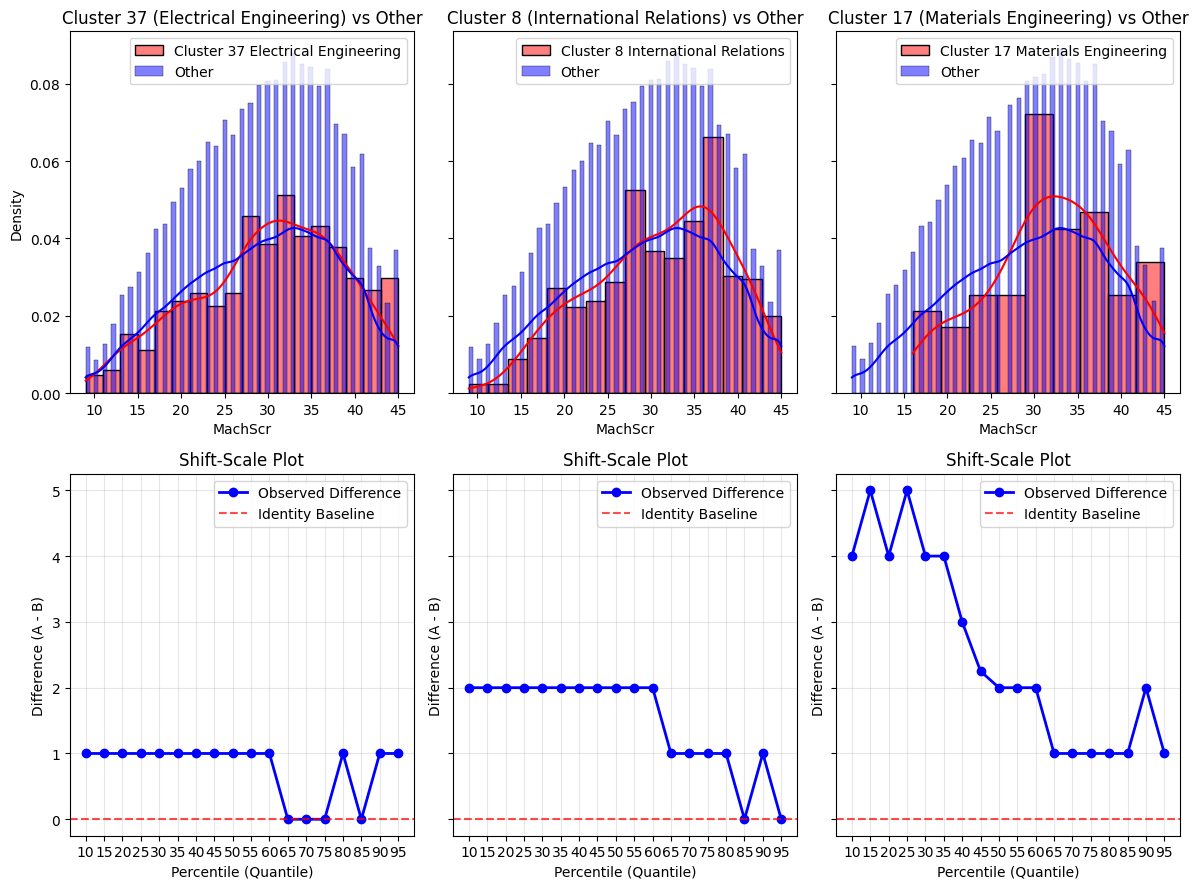

[]

In [ ]:
clusters_to_plot = [37, 8, 17]
num_clusters = len(clusters_to_plot)

fig, axes = plt.subplots(nrows=1, ncols=num_clusters, figsize=(5 * num_clusters, 5), squeeze=False)
axes = axes.flatten()

for i, cluster_id in enumerate(clusters_to_plot):
    ax_shift = axes[i]
    
    cluster_data = df[df['cluster'] == cluster_id]['MachScr'].to_frame()
    cluster_data['Group'] = f'Cluster {cluster_id}'
    
    if len(cluster_data) > 100:
        cluster_data, _ = train_test_split(cluster_data, train_size=100, random_state=42)
    
    gp_data = df[df['cluster'] != cluster_id]['MachScr'].to_frame()
    gp_data['Group'] = 'General Population'
    
    if len(gp_data) > len(cluster_data):
        gp_data, _ = train_test_split(gp_data, train_size=len(cluster_data), random_state=42)
        
    plot_df = pd.concat([cluster_data, gp_data], axis=0)
    
    sns.swarmplot(
        data=plot_df, 
        x='Group', 
        y='MachScr', 
        hue='Group', 
        palette={'General Population': 'blue', f'Cluster {cluster_id}': 'red'},
        ax=ax_shift,
        legend=False
    )
    
    prof_name = profession(df, cluster_id)[0]
    ax_shift.set_title(f'{prof_name} vs Gen. Pop.', size=11, weight='bold')
    ax_shift.set_xlabel('')
    ax_shift.set_ylabel('Machiavellianism Score')

shiftdist(feat_col='cluster', feat_col_vals=clusters_to_plot, feature='MachScr', step=5)

In [ ]:
print(generate_report(mach_majors.loc[8]))

**Cluster 8 "International Relations"** (N = 1116)
- Scores significantly on the Machivellianism metric. Their *machivellianism median* is $95\%\text{CI}\space[31, 33]$ with a central value of **32.0**. 
- In general, **comparing two random people from "International Relations" group and "Every other kind of people",** the International Relations group **will score higher on machivellianism in 55% of cases** (p-value: $1.72e-08$).
- **The effect size is negligible** with $\delta_{cliff}\approx 0.10$.



**Cluster 37 "Electrical Engineering"** (N = 1506)
- Scores significantly on the Machivellianism metric. Their *machivellianism median* is $95\%\text{CI}\space[30, 31]$ with a central value of **31.0**. 
- In general, **comparing two random people from "Electrical Engineering" group and "Every other kind of people",** the Electrical Engineering group **will score higher on machivellianism in 52% of cases** (p-value: $8.38e-03$).
- **The effect size is negligible** with $\delta_{cliff}\approx 0.05$.
- Scores 1 point higher than gp. all of the time except for the 70th quantile, which is identical to gp.

**Cluster 8 "International Relations"** (N = 1116)
- Scores significantly on the Machivellianism metric. Their *machivellianism median* is $95\%\text{CI}\space[31, 33]$ with a central value of **32.0**. 
- In general, **comparing two random people from "International Relations" group and "Every other kind of people",** the International Relations group **will score higher on machivellianism in 55% of cases** (p-value: $1.85e-08$).
- **The effect size is negligible** with $\delta_{cliff}\approx 0.10$.
- Most of the differences is described by the 60% mach gorup. all of them score 2 points higher than gp. Than, the differences start to fade, 70-80% score 1 point higher than gp. and 80-100 is identical to the gp.

**Cluster 17 "Materials Engineering"** (N = 146)
- Scores significantly on the Machivellianism metric. Their *machivellianism median* is $95\%\text{CI}\space[30, 34]$ with a central value of **32.0**. 
- In general, **comparing two random people from "Materials Engineering" group and "Every other kind of people",** the Materials Engineering group **will score higher on machivellianism in 58% of cases** (p-value: $1.91e-03$).
- **The effect size is small** with $\delta_{cliff}\approx 0.17$.
- This group is most different from gp. in its beggining 30% (the most low-mach group). The me. does not have a minimum of 10 (the scale minimum), it starts strongly around 16-18 points.then the difference starts to fade: 35%: +4 points, 40-60%: +2 points, 60-95% (except 90 which is 2): 1 point.

0.045470757110873394
-0.13127046888609023


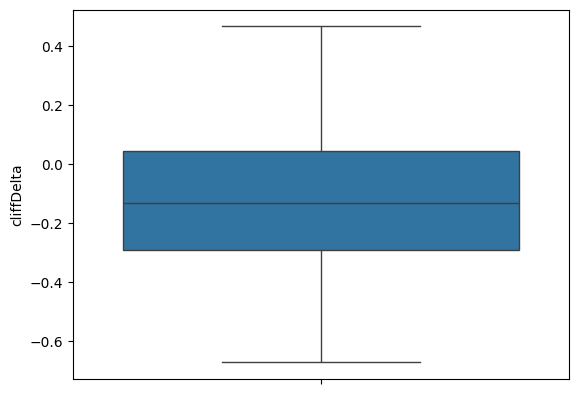

In [ ]:
sns.boxplot(mach_to_norm['cliffDelta'])
print(mach_to_norm['cliffDelta'].quantile(.75))
print(mach_to_norm['cliffDelta'].quantile(.5))

##### Conclusion

As we can see, most of the differences for machivellianism are in the range of $\approx$ 0 to -0.25. Also the .75 quantile of Cliffs delta is 0.04, which tells, that big positive differences (e.g. highly more machivellianistic people) aren't the majority of different people, they are the least part (of those who are different, <25%). 

There's a frequently occuring phenomena, when looking at the deciles difference. For most (but not all) observed cases the difference is smaller on the first 20% and last 20% percent. The biggest decile difference is usually somewhere at the IQR. That is probably explained by the fact, that people with strong beliefs and a well-established worldview tend to behave identically no matter the major. And for those who are inbetween, the difference can mostly be explained by their occupation and interests, rather than a strong belief system.

**Non-mach majors**
- Tend to be social/education vectored. Communication Disorders, Behavioral Science, Counseling, Counseling, are all majors of people, who understand human nature deeply and use their knowledge in their professional occupation.
- Are highly different from the gp. (relatively to other) with their Cliff's delta min max interval of [-0.46, -0.29]
- The lowest median is **25** $95\%CI\space[16, 23]$ and the highest is **25** with $95\%CI\space[21.5, 29.5]$

**Neutrally machivellianistic majors**
- Occupy the middle IQR of the significant $\delta_{cliff}$ distribution, falling roughly into $[-0.29, 0.04]$: significant, but small-to-negligeble differences from the gp.
- Are a mix of fields. **Education** (N = 2130) leans slightly less mach on average, with a median of **25**, $95\%CI\space[24, 25]$, $\delta_{cliff}\approx-0.29$, and is at the same time one of the highest-scoring majors on kindness. **Music** (N = 6650) is much closer to the gp., with a median of **28**, $95\%CI\space[27, 28]$, $\delta_{cliff}\approx-0.14$.
- On the other side of the neutral zone sits **Information Technology** (N = 1310) with a median of **31**, $95\%CI\space[30, 32]$, $\delta_{cliff}\approx0.04$ (PoS = 52\%), i.e. practically indistinguishable from the gp.
- The decile differences are diverce across the least, the median and the most machivellianistic majors. For the least, the differences are quite big, i.e. -3 to -6, the median, they're -1 to -3, the most mach, is +1 to +2. The data fits the general phenomena: the biggest differences are contained within the IQR, while the extreme quantiles converge back to the gp. For these majors, the small difference is better explained by occupation and interests, rather than by a strong belief system.

**Machivellianistic majors**
- Form the upper tail of the significant $\delta_{cliff}$ distribution (the top quartile of PS), with $\delta_{cliff}$ roughly in $[0.04, 0.17]$: significant, yet still small-to-negligeble positive differences from the gp.
- Tend to be technical/pragmatic fields: **Electrical Engineering** (N = 1506, median **31**, $95\%CI\space[30, 31]$, $\delta_{cliff}\approx0.05$), **International Relations** (N = 1116, median **32**, $95\%CI\space[31, 33]$, $\delta_{cliff}\approx0.10$), and **Materials Engineering** (N = 146, median **32**, $95\%CI\space[30, 34]$, $\delta_{cliff}\approx0.17$).
- The decile differences are typically just 1-2 points above the gp. and, exactly following the general phenomena, they converge back to the gp. at the upper quantiles. The most machivellianistic people in these majors are nearly identical to the most machivellianistic people of any other major.
- Even the most machivellianistic group stays below the medium-effect threshold, which supports the overall takeaway: strong machivellianism is mostly an individual trait, not something a major strongly selects for.

# UNDONE Area of childhood living analysis

Area of childhood living == Urban feature

#### Urban and personal characteristic interaction

In [ ]:
df['cluster'].nunique()

84

In [ ]:
urban_group = df.groupby('urban')

In [ ]:
urban_description = urban_group.describe()

In [ ]:
df['urban'].value_counts()

urban
3    61536
2    55892
1    28252
0     1262
Name: count, dtype: int64

##### Urban and mach interaction

In [ ]:
median, res, kw_1, kw_2 = compare_groups(df, 'urban', 'MachScr')

In [ ]:
print(kw_1, kw_2)
display(res)

638.0714487512671 5.618225083864767e-138


,count,median,ci_low,ci_high,PS,cliffDelta,p_raw,p_fdr,isDifferent
group,,,,,,,,,
0,1262,30.0,29.0,30.0,0.4849,-0.0303,6.339016e-02,6.339016e-02,False
1,28252,29.0,29.0,29.5,0.4806,-0.0387,3.540401e-24,4.720534e-24,True
2,55892,29.0,29.0,30.0,0.4735,-0.0530,2.077350e-65,4.154700e-65,True
3,61536,31.0,31.0,31.0,0.5385,0.0771,9.460306e-141,3.784122e-140,True


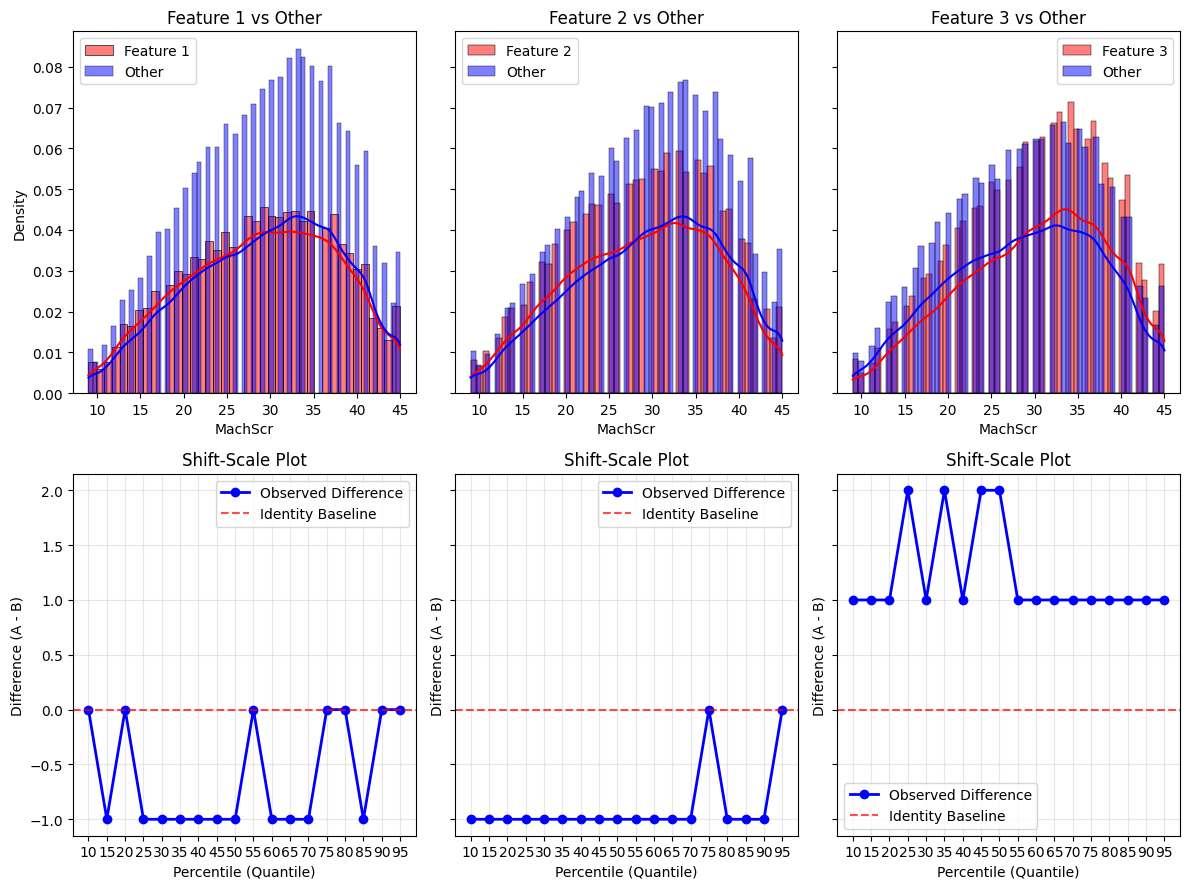

In [ ]:
diff = shiftdist(feat_col='urban', feat_col_vals=[1,2,3], feature='MachScr', step=5)

**Group 1 (Rural childhood)** (N = 28,252)
- Scores significantly, but only *barely*, lower on the Machiavellianism metric. Its *Machiavellianism median* is $95\%\text{CI}\space[29.0, 29.5]$ with a central value of **29.0**.
- In general, **comparing two random people from Cluster 1 and from the rest of the population,** the Cluster 1 member **will score higher on Machiavellianism in ~48% of cases** (p-value: $4.72e-24$).
- **The effect size is negligible** with $\delta_{cliff}\approx -0.04$.
- The shift-dist plot confirms this reading: the decile differences flicker between $0$ and $-1$ with no trend whatsoever, the gap never exceeds a single point and repeatedly collapses to zero. This is not a shape difference, just a faint, uniform downward wobble of the whole distribution.

**Group 2 (Suburbian childhood)** (N = 55,892)
- Scores significantly lower. Its *Machiavellianism median* is $95\%\text{CI}\space[29.0, 30.0]$ with a central value of **29.0**.
- **Comparing two random people from Cluster 2 and from the rest,** the Cluster 2 member **will score higher in only ~47% of cases** (p-value: $4.15e-65$).
- **The effect size is negligible**, the largest of the downward shifts, yet still far below the "small" threshold with $\delta_{cliff}\approx -0.05$.
- The shift-dist plot is a flat line at $-1$: the cluster sits exactly one point below the rest across nearly the entire distribution, and the deficit eases to $0$ only near the top. So it is a rigid one-point downward translation rather than a reshape — and, once again, the most Machiavellian people tend to look alike regardless of cluster membership.

**Group 3 (Urban childhood)** (N = 61,536)
- Scores significantly *higher*. Its *Machiavellianism median* is $95\%\text{CI}\space[31.0, 31.0]$ — the interval collapses to a single point thanks to the huge N — with a central value of **31.0**.
- **Comparing two random people from Cluster 3 and from the rest,** the Cluster 3 member **will score higher in ~54% of cases** (p-value: $3.78e-140$).
- **The effect size is negligible-to-small** with $\delta_{cliff}\approx +0.08$, the strongest of all four clusters, yet still under the 0.147 "small" cutoff.
- The shift-dist plot is confidently ascending: $+1$ across the whole distribution, swelling to $+2$ in the lower-middle deciles. The gap is therefore largest among the "moderately Machiavellian" members and narrows back to one point at both tails — the elevation lives in the bulk of the distribution, not in the extremes, mirroring the pattern seen across professions where the tails converge.

**Overall:** with $N\approx 147k$, even a 1-2 point translation yields astronomical p-values, so here the p-values measure *reliability*, not *importance*. All three shift-dist plots show rigid, shape-preserving offsets (+-1–2 points), and every Cliff's delta stays below 0.08: the clusters are statistically distinguishable but substantively near-identical on this metric.

##### Urban and kind interaction

In [ ]:
median, res, kw_stat, kw_p_val = compare_groups(df, 'urban', 'KindScr')

In [ ]:
res

,count,median,ci_low,ci_high,PS,cliffDelta,p_raw,p_fdr,isDifferent
group,,,,,,,,,
0,1262,26.0,25.0,27.0,0.5064,0.0128,4.320799e-01,4.320799e-01,False
1,28252,26.0,26.0,27.0,0.5228,0.0457,5.798326e-33,2.319330e-32,True
2,55892,25.0,25.0,26.0,0.4912,-0.0175,1.622428e-08,3.244857e-08,True
3,61536,26.0,25.0,26.0,0.4937,-0.0126,3.444203e-05,4.592270e-05,True


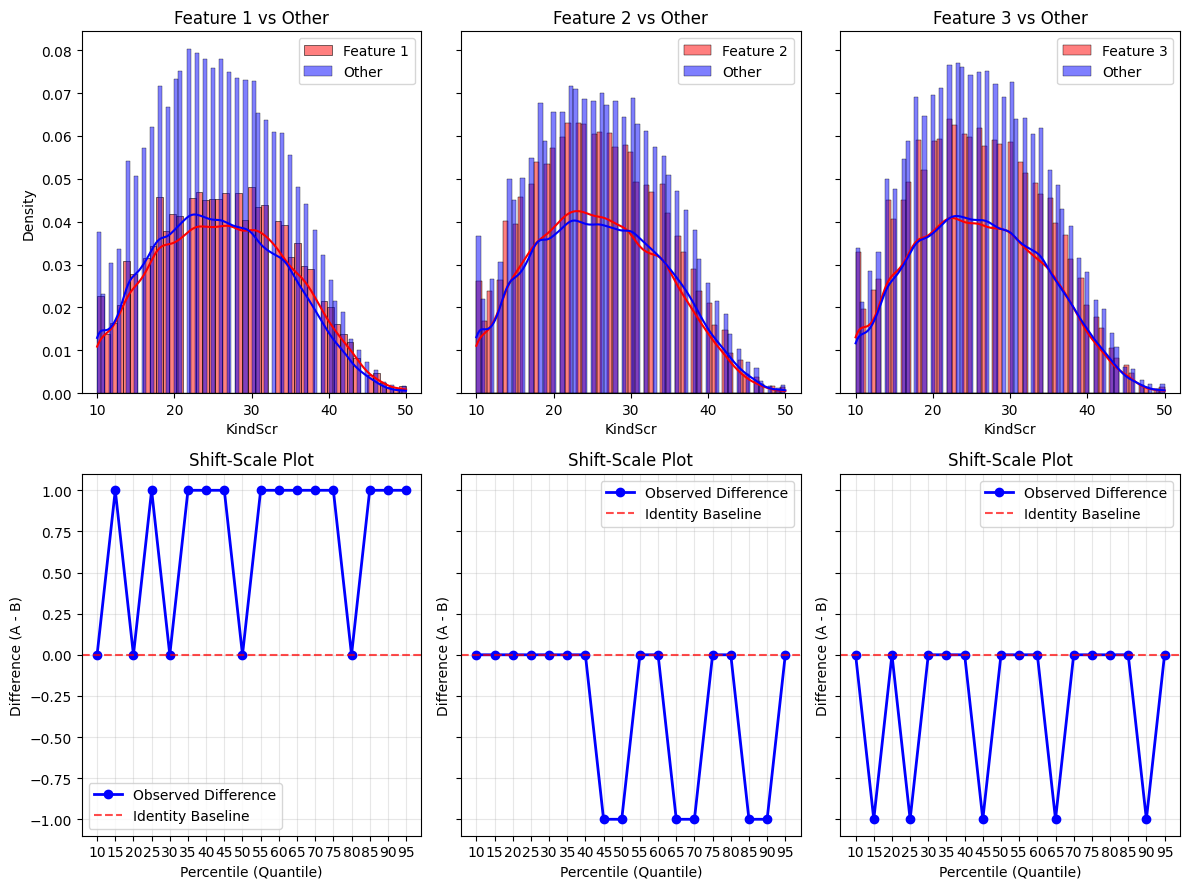

In [ ]:
diff = shiftdist(feat_col='urban', feat_col_vals=[1,2,3], feature='KindScr', step=5)

**Group 1 (Rural childhood)** (N = 28,252)
- Scores significantly, but only marginally, *higher* on the Kindness metric. Its *Kindness median* is $95\%\text{CI}\space[26.0, 27.0]$ with a central value of **26.0**.
- In general, **comparing two random people from Cluster 1 and from the rest of the population,** the Cluster 1 member **will score higher on Kindness in ~52% of cases** (p-value: $2.32e-32$).
- **The effect size is negligible** with $\delta_{cliff}\approx +0.05$.
- The shift-dist plot confirms this reading: the decile differences flicker between $0$ and $+1$ with no trend whatsoever the gap never exceeds a single point and repeatedly collapses to zero. This is not a shape difference, just a faint, uniform upward wobble of the whole distribution.

**Group 2 (Suburbian childhood)** (N = 55,892)
- Scores significantly lower. Its *Kindness median* is $95\%\text{CI}\space[25.0, 26.0]$ with a central value of **25.0** - the lowest of all four clusters.
- **Comparing two random people from Cluster 2 and from the rest,** the Cluster 2 member **will score higher in only ~49% of cases** (p-value: $3.24e-08$).
- **The effect size is negligible** with $\delta_{cliff}\approx -0.02$ actually the smallest absolute delta among the significant clusters.
- The shift-dist plot is mostly flat at $0$, dipping to $-1$ only sporadically across scattered deciles. So the cluster sits essentially on top of the rest, with an occasional one-point deficit appearing here and there rather than any systematic translation - once again, a statistically detectable but substantively trivial displacement.

**Group 3 (Urban childhood)** (N = 61,536)
- Scores significantly lower. Its *Kindness median* is $95\%\text{CI}\space[25.0, 26.0]$ with a central value of **26.0**.
- **Comparing two random people from Cluster 3 and from the rest,** the Cluster 3 member **will score higher in ~49% of cases** (p-value: $4.59e-05$).
- **The effect size is negligible** with $\delta_{cliff}\approx -0.01$ - the weakest signal of the three significant clusters.
- The shift-dist plot mirrors Cluster 2's: predominantly zeros with isolated $-1$ dips at a handful of deciles. There is no coherent downward slope, no widening gap at the tails — just a barely-perceptible, irregular drift below the population baseline.


#### Urban and self-perception (TIPI) interaction

In [ ]:
df['TIPI1'].value_counts

TIPI1
6    28926
5    25478
2    25120
3    19902
1    19280
7    15466
4    12320
0      450
Name: count, dtype: int64

In [ ]:
orient_denominations8[2]

'Bisexual'

TIPI1, Extraverted, enthusiastic.
Asexual: 2.0	 GP: 4.0, diffs: -1.0


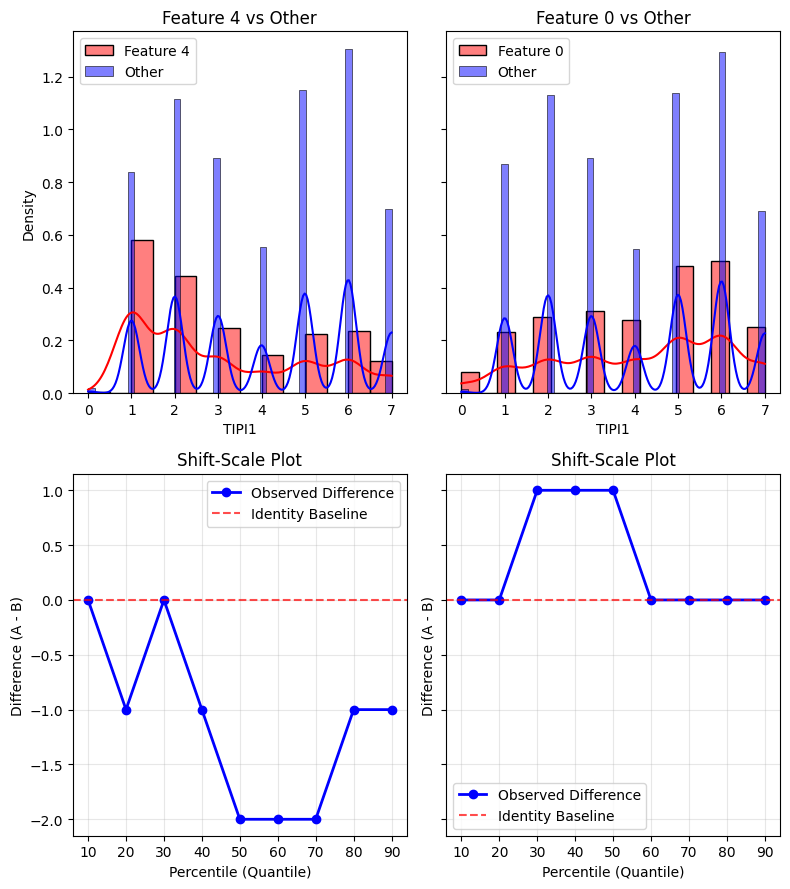

TIPI2, Critical, quarrelsome.
TIPI3, Dependable, self-disciplined.
TIPI4, Anxious, easily upset.
TIPI5, Open to new experiences, complex.
TIPI6, Reserved, quiet.
Asexual: 6.0	 GP: 5.0, diffs: 1.0


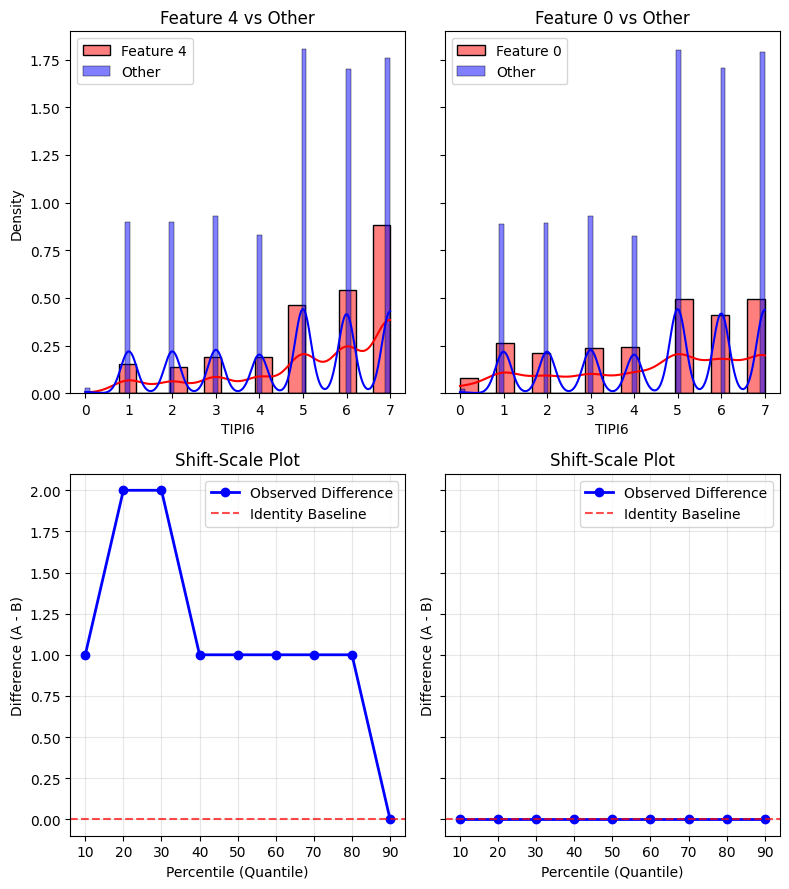

TIPI7, Sympathetic, warm.
TIPI8, Disorganized, careless.
TIPI9, Calm, emotionally stable.
Bisexual: 4.0	 GP: 5.0, diffs: -1.0


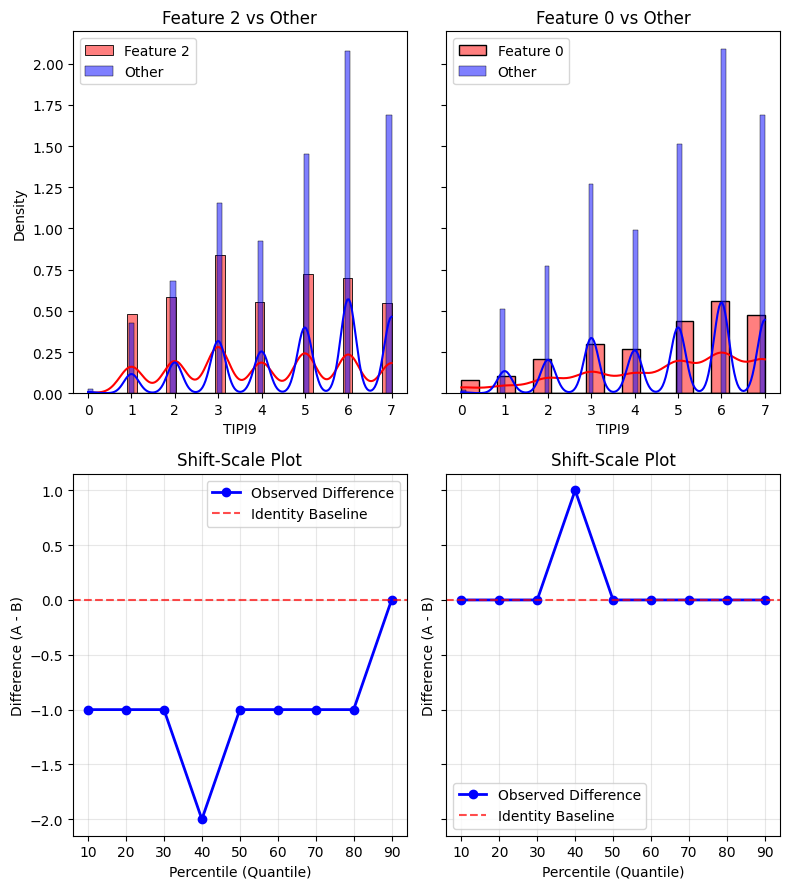

TIPI10, Conventional, uncreative.


In [ ]:
for i in range(1, 11):
    print(f'TIPI{i}, {TIPI_DENOMINATIONS[f"TIPI{i}"]}')
    feat = 'orientation'
    tipi_num = f'TIPI{i}'
    for orient in range(0, 6):
        mask = df[feat] == orient
        orient_stat = df[mask][tipi_num]
        gp_stat = df[~mask][tipi_num]
        diffs = compare_quantiles(orient_stat, gp_stat)
        if abs(np.mean(diffs)) >= 1:
            print(f'{orient_denominations[orient]}: {round(orient_stat.median(), 3)}\t GP: {round(gp_stat.median(), 3)}, diffs: {round(np.median(diffs), 3)}')
            diffs = shiftdist(feat_col=feat, feat_col_vals=[orient, 0], feature=tipi_num, ) 
    # print('\n')

# TIPI interactions

## TIPI interactions with personal characteristics.

In [ ]:
def tipi_generator(number):
    number = str(number)
    non_agr_tipi_num_mask = df['TIPI'+number].le(3)
    non_agr_tipi_num = df[non_agr_tipi_num_mask]

    neutr_tipi_num_mask = df['TIPI'+number].eq(4)
    neutr_tipi_num = df[neutr_tipi_num_mask]

    agr_tipi_num_mask = df['TIPI'+number].ge(5)
    agr_tipi_num = df[agr_tipi_num_mask]
    return (non_agr_tipi_num, neutr_tipi_num, agr_tipi_num, df['TIPI'+str(number)])

In [ ]:
def mann_stat(dist1, dist2):
    u_stat, p_value = sp.stats.mannwhitneyu(dist1, dist2)
    prob_of_super = u_stat/(len(dist1)*len(dist2))
    return p_value, prob_of_super

##### TIPI 1: Extraverted, enthusiastic.

In [ ]:
non_agr_tipi_1, neutr_tipi_1, agr_tipi_1, tipi_1_gen = tipi_generator(5)

MannwhitneyuResult(statistic=np.float64(1385947324.0), pvalue=np.float64(2.8439505173149933e-65))

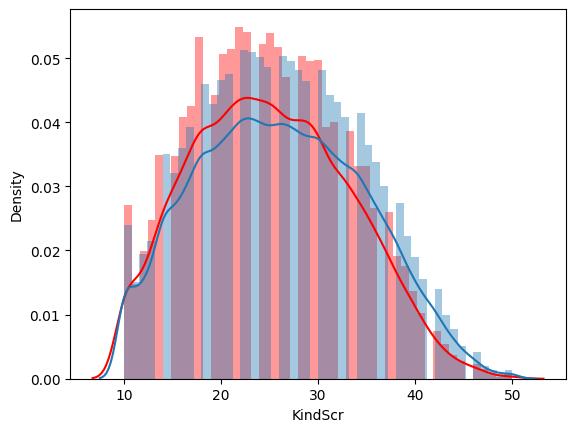

In [ ]:
agr_tipi_1_ind = agr_tipi_1.index
mask_general_population = map(lambda x: not x, df.index.isin(agr_tipi_1_ind))
mask_general_population = pd.Series(mask_general_population, index=df.index)
sns.distplot(df.loc[mask_general_population, 'KindScr'],color='red', label='General Population')
sns.distplot(df.loc[~mask_general_population, 'KindScr'])
sp.stats.mannwhitneyu(df.loc[mask_general_population, 'KindScr'], df.loc[~mask_general_population, 'KindScr'])

<Axes: >

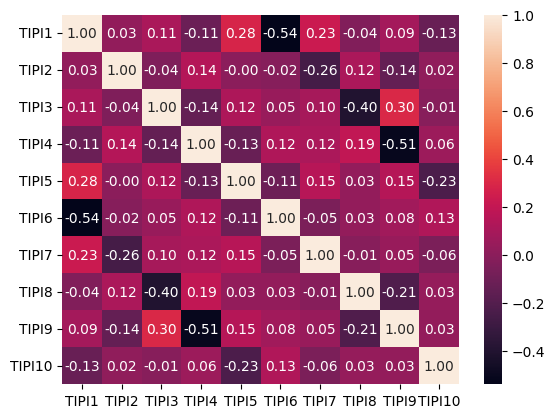

In [ ]:
sns.heatmap(df[tipi_cols].corr(), annot=True, fmt=".2f")

15106 9170 122666


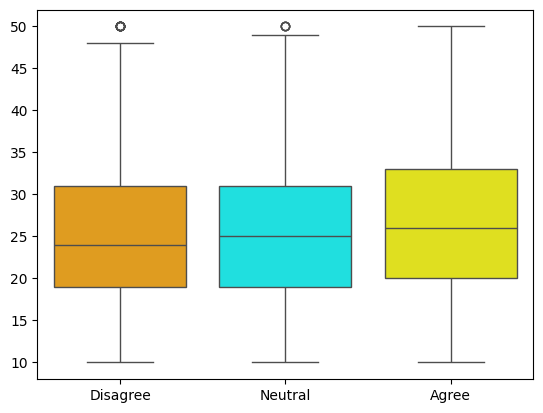

In [ ]:
feature = 'KindScr'
plot_data = pd.DataFrame(
    {
        "Disagree": non_agr_tipi_1[feature],
        "Neutral": neutr_tipi_1[feature],
        "Agree": agr_tipi_1[feature],
    }
)
sns.boxplot(plot_data, palette=['orange','cyan', 'yellow'])
# print(mann_stat(agr_tipi_1['LiarSum'], neutr_tipi_1['LiarSum']))
print(len(non_agr_tipi_1), len(neutr_tipi_1), len(agr_tipi_1))

(np.float64(1.5703071118837878e-200), np.float64(0.44309834872552906))
31620 91046


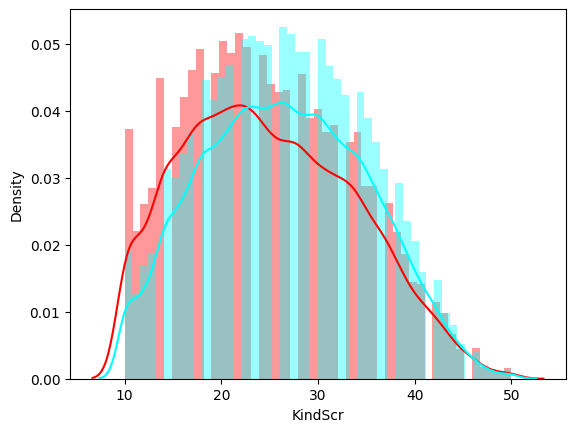

In [ ]:
agr_tipi_1_liars_mask = agr_tipi_1['IsLiar'] == True
agr_tipi1_liars = agr_tipi_1[agr_tipi_1_liars_mask]
agr_tipi1_honest = agr_tipi_1[~agr_tipi_1_liars_mask]
sns.distplot(agr_tipi1_liars['KindScr'], color='red') 
sns.distplot(agr_tipi1_honest['KindScr'], color='cyan')
print(mann_stat(agr_tipi1_liars['KindScr'], agr_tipi1_honest['KindScr']))
print(len(agr_tipi1_liars), len(agr_tipi1_honest))

(np.float64(2.5201273638651754e-05), np.float64(0.4924477785158903))
31620 91046


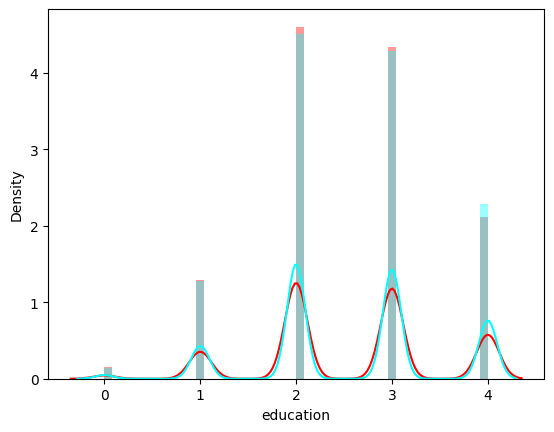

In [ ]:
feature = 'education'
agr_tipi_1_liars_mask = agr_tipi_1['IsLiar'] == True
agr_tipi1_liars = agr_tipi_1[agr_tipi_1_liars_mask]
agr_tipi1_honest = agr_tipi_1[~agr_tipi_1_liars_mask]
sns.distplot(agr_tipi1_liars[feature], color='red') 
sns.distplot(agr_tipi1_honest[feature], color='cyan')
print(mann_stat(agr_tipi1_liars[feature], agr_tipi1_honest[feature]))
print(len(agr_tipi1_liars), len(agr_tipi1_honest))

In [ ]:
sns.distplot(neutr_tipi1['KindScr'],color='red')
sns.distplot(df['KindScr'])

NameError: name 'neutr_tipi1' is not defined

# Orientation and personal charateristic interaction

## Orientation and Kindness metric

In [ ]:
orient_denominations = {0: "Undefined", 1: "Heterosexual", 2: "Bisexual", 3: "Homosexual", 4: "Asexual", 5: "Other"}

In [ ]:
median, res, kw_stat, kw_p_val = compare_groups(df, 'orientation', 'KindScr')

In [ ]:
median

np.float64(26.0)

In [ ]:
res

,count,median,ci_low,ci_high,PS,cliffDelta,p_raw,p_fdr,isDifferent
group,,,,,,,,,
0,2822,29.0,28.0,29.0,0.5794,0.1588,1.603804e-47,4.811413e-47,True
1,113144,26.0,26.0,26.0,0.5255,0.0510,3.832198e-46,7.664396e-46,True
2,17698,24.0,24.0,24.0,0.4503,-0.0993,2.782102e-102,1.669261e-101,True
3,5990,25.0,25.0,26.0,0.4896,-0.0209,6.077802e-03,6.077802e-03,True
4,3426,23.0,23.0,24.0,0.4472,-0.1056,3.341253e-26,5.011879e-26,True
5,3862,27.0,27.0,27.0,0.5335,0.0671,1.008005e-12,1.209606e-12,True


In [ ]:
print(df[df['orientation'] == 1]['IsLiar'].sum()/df[df['orientation'] == 1]['IsLiar'].count())
print(df[df['orientation'] != 1]['IsLiar'].sum()/df[df['orientation'] != 1]['IsLiar'].count())

0.2434243088453652
0.2803124445233446


In [ ]:
# shiftdist(feat_col='orientation', feat_col_vals=[0, 1, 2], feature='IsLiar', denom_dict=orient_denominations)
shiftdist(feat_col='orientation', feat_col_vals=[3, 4, 5], feature='MachScr', denom_dict=orient_denominations)

NameError: name 'shiftdist' is not defined

# HIGHLY UNDONE Childhood area - major groups description

In [ ]:
rural_majors = df[df['urban'] == 1]['cluster'].value_counts() / len(df[df['urban'] == 1]['cluster'])
suburban_majors = df[df['urban'] == 2]['cluster'].value_counts() / len(df[df['urban'] == 2]['cluster'])
urban_majors = df[df['urban'] == 3]['cluster'].value_counts() / len(df[df['urban'] == 3]['cluster'])

In [ ]:
a = pd.merge(rural_majors, suburban_majors, on='cluster').merge(urban_majors, on='cluster', how='outer', suffixes=('_rural', '_suburban')).fillna(0).sort_values(ascending=False, by=['count_x', 'count_y', 'count'])

a

NameError: name 'rural_majors' is not defined

In [ ]:
for cl, diff in (a['count_x'] - a['count']).sort_values(ascending=False, key=abs).items():
    print(f'Cluster: {profession(df, cl, 1)[0]:<25} {round(diff, 3)} Rural-Urban difference:' )

Cluster: Business                  -0.024 Rural-Urban difference:
Cluster: Psychology                0.019 Rural-Urban difference:
Cluster: Law                       -0.008 Rural-Urban difference:
Cluster: Unknown                   -0.008 Rural-Urban difference:
Cluster: Education                 0.007 Rural-Urban difference:
Cluster: English                   0.005 Rural-Urban difference:
Cluster: Environmental Science     0.004 Rural-Urban difference:
Cluster: &#24515;&#29702;&#23398;  0.003 Rural-Urban difference:
Cluster: Architecture              -0.003 Rural-Urban difference:
Cluster: Tourism                   -0.002 Rural-Urban difference:
Cluster: Engineering               -0.002 Rural-Urban difference:
Cluster: Information Technology    0.002 Rural-Urban difference:
Cluster: International Relations   -0.002 Rural-Urban difference:
Cluster: Dentistry                 -0.001 Rural-Urban difference:
Cluster: Art                       0.001 Rural-Urban difference:
Cluster: Cyber Se

In [ ]:
for cl, diff in (a['count_y'] - a['count']).sort_values(ascending=False, key=abs).items():
    print(f'Cluster: {profession(df, cl, 1)[0]:<25} {round(diff, 3)} Rural-Urban difference:' )

Cluster: Business                  -0.019 Rural-Urban difference:
Cluster: Psychology                0.017 Rural-Urban difference:
Cluster: Engineering               -0.01 Rural-Urban difference:
Cluster: Unknown                   0.008 Rural-Urban difference:
Cluster: Music                     0.006 Rural-Urban difference:
Cluster: Education                 0.005 Rural-Urban difference:
Cluster: Law                       -0.004 Rural-Urban difference:
Cluster: English                   -0.004 Rural-Urban difference:
Cluster: Information Technology    -0.002 Rural-Urban difference:
Cluster: Tourism                   -0.002 Rural-Urban difference:
Cluster: Architecture              -0.002 Rural-Urban difference:
Cluster: Environmental Science     0.001 Rural-Urban difference:
Cluster: Chemistry                 0.001 Rural-Urban difference:
Cluster: Criminal Justice          0.001 Rural-Urban difference:
Cluster: Art                       0.001 Rural-Urban difference:
Cluster: Internatio

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

In [ ]:

# vec_x = a['count_x'].values.reshape(1, -1)
# vec_y = a['count_y'].values.reshape(1, -1)

# # This will output a 1x1 matrix containing your single score
# score = cosine_similarity(vec_x, vec_y)[0][0]
# print(score)


0.9991079095596835


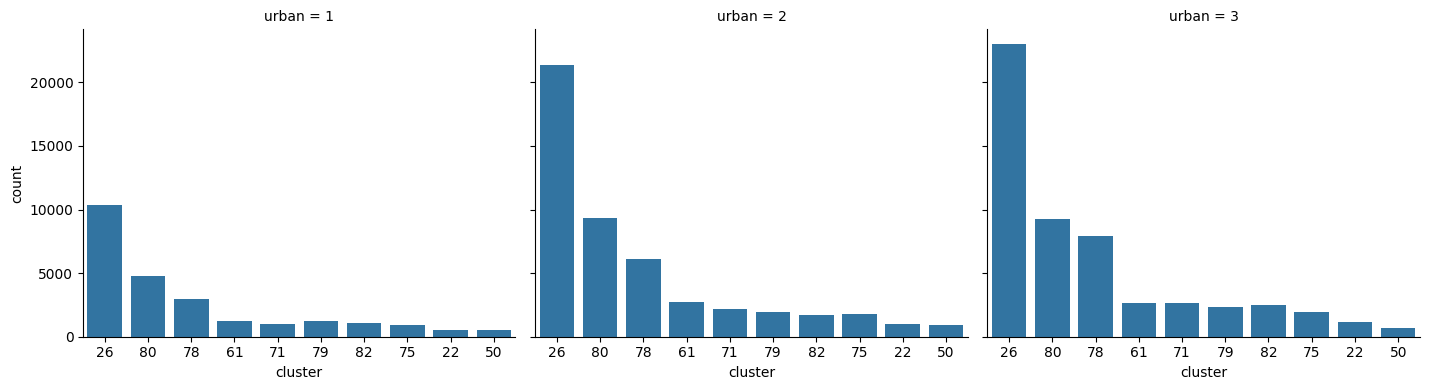

In [ ]:
# # 1. Отбираем топ-10 кластеров для всего датасета (или отдельно по группам)
# top_10_clusters = df['cluster'].value_counts().head(10).sort_values(ascending=False).index
# filtered_df = df[df['cluster'].isin(top_10_clusters)]

# # 2. Строим сравнительные графики: col='urban' разнесет их на разные графики в один ряд
# sns.catplot(
#     data=filtered_df[df['urban'].isin([1, 2, 3])],  # Фильтруем по значениям urban
#     x="cluster", 
#     col="urban",       # Создает отдельные графики для каждого значения 'urban'
#     kind="count",      # Аналог countplot/barplot для подсчета количества
#     order=top_10_clusters,  # Упорядочиваем кластеры по количеству
#     height=4, 
#     aspect=1.2,
# )


# HIGHLY UNDONE Voting analysis 

## Voting interaction with personal characteristics

In [ ]:
voted = df[df['voted'] == 1]
passive = df[df['voted'] == 2]

In [ ]:
overall_median, res, kw_stat, kw_p = compare_groups(df, 'voted', 'MachScr', n_resamples=3_000)

In [ ]:
res

,count,median,ci_low,ci_high,PS,cliffDelta,p_raw,p_fdr,isDifferent
group,,,,,,,,,
0,1162,30.0,29.0,30.0125,0.4935,-0.0129,0.446356,0.446356,False
1,64584,29.0,29.0,29.0000,0.4396,-0.1208,0.000000,0.000000,True
2,81196,31.0,31.0,31.0000,0.5604,0.1207,0.000000,0.000000,True


Voting people are slightly less machiavellianistic.

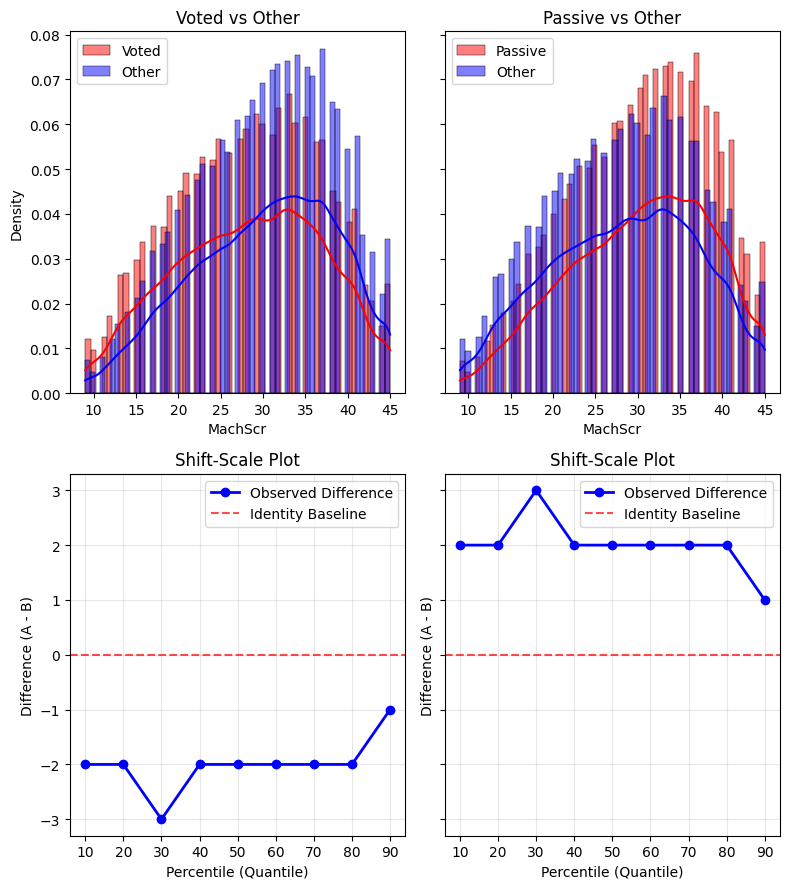

In [ ]:
a = shiftdist('voted', 'MachScr', [1, 2], {1: 'Voted', 2: 'Passive'})

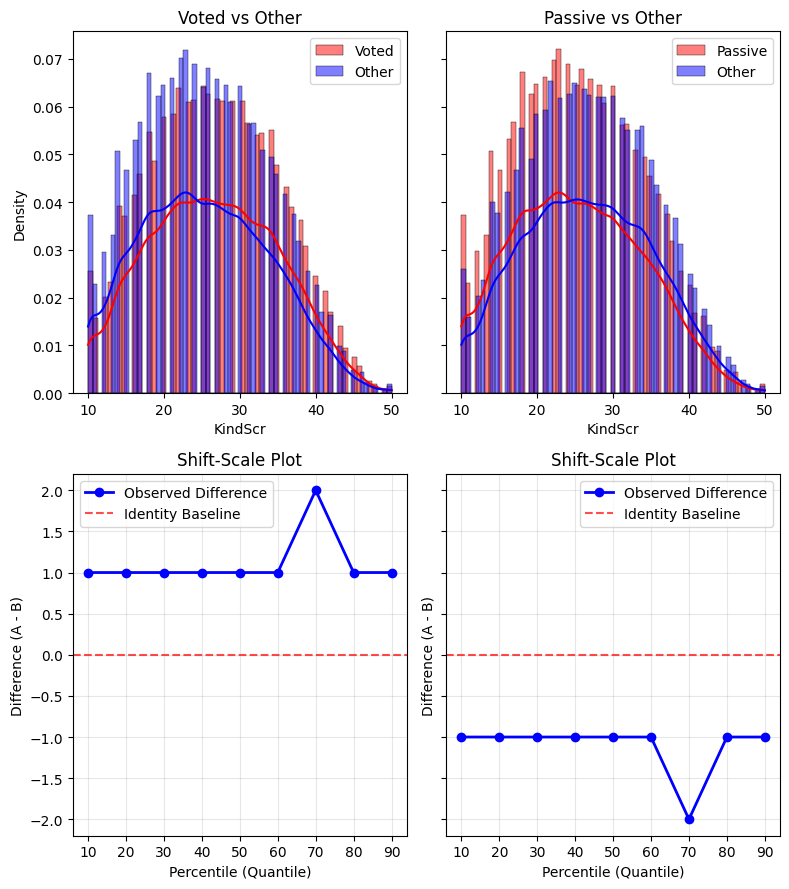

In [ ]:
a = shiftdist('voted', 'KindScr', [1, 2], {1: 'Voted', 2: 'Passive'})

## Voted and IsLiar interaction

In [ ]:
voted['IsLiar'].mean()

np.float64(0.26734175647219127)

In [ ]:
passive['IsLiar'].mean()

np.float64(0.2403566678161486)

In [ ]:
from statsmodels.stats.proportion import proportions_ztest

# Запускаем двусторонний Z-тест
# voted
# 3. Передаем агрегированные пары в Z-тест
successes = np.array([success_A, success_B])
trials = np.array([n_A, n_B])

z_stat, p_value = proportions_ztest(successes, trials, alternative='two-sided')
z_stat, p_value = proportions_ztest(voted['IsLiar'], passive['IsLiar'], alternative='two-sided')


ValueError: operands could not be broadcast together with shapes (64584,) (81196,) 

# Predictive Analysis

In [ ]:
X = df.copy()
X_exp = X.copy()
y = df['cluster']
X = X.drop(['cluster', 'country', 'major'], axis=1)

In [ ]:
df.to_csv('data_processed.csv')

In [ ]:
by_features = ['MachScr', 'KindScr']  # Replace with your actual column names

# 2. Run your description pipeline
# Note: No double brackets around by_features if it's already a list
desc = X_exp.groupby('cluster')[by_features].describe()

# 3. Select the columns you want (count, mean, std, 50%, 75%)
# Since it's a MultiIndex, we filter the second level ('count', 'mean', etc.)
columns_to_keep = ['count', 'mean', 'std', '50%', '75%']
desc_filtered = desc.loc[:, (slice(None), columns_to_keep)]

# 4. Dynamically build the sorting tuples
# This creates: [('age', 'mean'), ('age', 'count'), ('score', 'mean'), ('score', 'count')]
sort_order = []
for col in by_features:
    # sort_order.append((col, 'mean'))
    sort_order.append((col, 'count'))

# 5. Sort everything cleanly
final_df = desc_filtered.sort_values(by=sort_order, ascending=False)

In [ ]:
major_names = df[df[['cluster','major']].duplicated().apply(lambda x: not x)][['cluster','major']]
# major_names = pd.DataFrame()

In [ ]:
final_df[('major', 'name')] = [profession(df,x ) for x in final_df.index]

In [ ]:
len(questions_groups[0]), len(questions_groups[1])

(9, 10)

In [ ]:
final_df.head(20)
# print('Profession \t mean \t 50% \t 70%')
# X_exp.groupby('cluster')[[by]].describe().iloc[:, [0,1,2,5, 6]].sort_values(by=[(by, 'mean'), (by, 'count')], ascending=False)
    # prof = profession(df, e[0])[0][:15]
    # # print(e[1])
    # count = e[1].iloc[0]
    # mean = e[1].iloc[1]
    # fifty_perc = e[1].iloc[2]
    # sev_five_perc = e[1].iloc[3]
    # print(f'{prof} \t {round(mean)} \t {round(fifty_perc, 1)} \t {round(sev_five_perc, 1)}')

MachScr                                   KindScr             \
           count       mean       std   50%   75%    count       mean   
cluster                                                                 
26       55442.0  30.147902  8.408334  31.0  37.0  55442.0  25.442625   
80       23486.0  27.893724  8.697374  28.0  35.0  23486.0  26.918419   
78       17060.0  29.397304  8.473948  30.0  36.0  17060.0  26.190035   
61        6650.0  27.444511  8.300620  28.0  34.0   6650.0  27.221353   
71        5903.0  31.173979  8.269892  32.0  38.0   5903.0  23.360664   
79        5492.0  28.330299  8.364389  29.0  35.0   5492.0  26.525856   
82        5368.0  30.805142  8.359651  32.0  37.0   5368.0  25.872206   
75        4658.0  29.989266  8.415828  31.0  36.0   4658.0  24.669386   
22        2688.0  29.244048  8.620000  30.0  36.0   2688.0  25.636905   
50        2130.0  25.055399  8.201990  25.0  31.0   2130.0  29.748357   
19        1546.0  29.024580  8.357895  30.0  36.0   1546.0  25.763260   
37        1506.0  29.994688  8.506709  31.0  36.0   1506.0  26.065073   
21        1310.0  29.935878  8.393976  31.0  36.0   1310.0  26.070229   
58        1256.0  29.265924  8.449578  30.0  36.0   1256.0  26.409236   
53        1240.0  28.301613  8.703584  29.0  35.0   1240.0  25.785484   
8         1116.0  30.888889  7.898131  32.0  37.0   1116.0  24.736559   
5         1040.0  28.407692  8.620272  29.0  35.0   1040.0  27.051923   
18         886.0  27.139955  8.347444  27.0  34.0    886.0  27.970655   
48         870.0  29.411494  8.780319  30.0  36.0    870.0  24.540230   
59         840.0  30.150000  8.395406  31.0  37.0    840.0  25.821429   

                               \
              std   50%   75%   
cluster                         
26       8.530267  25.0  32.0   
80       8.414480  27.0  33.0   
78       8.538509  26.0  32.0   
61       7.909875  27.0  33.0   
71       8.163331  22.0  29.0   
79       8.098075  26.0  33.0   
82       8.572865  26.0  32.0   
75       8.260766  24.0  31.0   
22       8.471094  25.0  32.0   
50       8.065640  30.0  36.0   
19       8.285651  25.0  32.0   
37       8.552967  26.0  33.0   
21       8.175012  26.0  32.0   
58       7.968246  26.0  33.0   
53       8.332329  26.0  32.0   
8        8.046086  24.0  30.0   
5        7.849597  28.0  33.0   
18       7.694538  28.0  33.0   
48       8.452677  24.0  31.0   
59       8.086188  25.0  32.0   

                                                     major  
                                                      name  
cluster                                                     
26                              [Unknown, IT, No, no, MBA]  
80       [Psychology, psychology, History, Biology, Psy...  
78       [Business, Economics, Accounting, Finance, bus...  
61       [Music, Communications, Communication, Journal...  
71       [Law, Political Science, law, Politics, politi...  
79       [English, English , english, Linguistics, Lite...  
82       [Engineering, engineering, civil engineering, ...  
75       [Computer Science, computer science, Computer ...  
22           [Physics, Science, physics, science, Geology]  
50       [Education, Education , education, Teaching, t...  
19       [Chemistry, chemistry, Chemical Engineering, C...  
37       [Electrical Engineering, electrical engineerin...  
21       [Information Technology, Technology, Computing...  
58       [Criminal Justice, Criminology, Criminal justi...  
53           [Mathematics, Math, mathematics, math, Maths]  
8        [International Relations, international relati...  
5                              [Art, art, Arts, arts, ART]  
18       [Environmental Science, Agriculture, Ecology, ...  
48       [Philosophy, philosophy, Philosophy , philosop...  
59       [Architecture, architecture, Architecture , Ur...

In [ ]:
:

SyntaxError: invalid syntax (1305497275.py, line 1)

In [ ]:
y += 1

In [ ]:
int(y.max())

83

In [ ]:
custom_f1_scorer = make_scorer(f1_score, average='weighted')

In [ ]:
skf = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)

In [ ]:
model = LGBMClassifier(
    objective='multiclass',       # Целевая функция для мультиклассификации
    num_class=int(y.nunique()),      # Ровно 400 классов
    n_estimators=600,             # Количество деревьев (итераций)
    
    # Скорость и глубина деревьев (главные параметры контроля времени)
    num_leaves=32,                # Максимум листьев в дереве (аналог max_depth=5 в XGBoost, но быстрее)
    max_depth=80,                  # Защита от переобучения на глубоких ветках (-1 — без ограничений)
    min_child_samples=10,         # Минимальное число образцов в листе (важно при редких классах!)
    
    # Оптимизация потоков под гибридную архитектуру Core Ultra 9
    n_jobs=12,                  # Используем только производительные P-ядра во избежание зависаний
    
    # Регуляризация и случайность (аналоги subsample и colsample)
    subsample=0.8,                # Доля строк для построения одного дерева
    subsample_freq=1,             # Частота обновления выборки строк (обязательно 1 при subsample)
    colsample_bytree=0.8,         # Доля признаков для каждого дерева
    
    random_state=42,
    verbose=-1                    # Скрывает лишние предупреждения в консоли
)

# model = XGBClassifier(
#     objective='multi:softprob',
#     num_class=int(y.nunique()),
#     tree_method='hist',  # Самый важный параметр для скорости
#     n_estimators=100,    # Начните со 100, при необходимости увеличивайте
#     max_depth=6,
#     n_jobs=8,           # Используем все ядра Ultra 9
#     subsample=0.8,
#     colsample_bytree=0.8,
#     random_state=42
# )

In [ ]:
# from sklearn.neural_network import MLPClassifier

# model = MLPClassifier(
#     hidden_layer_sizes=(256, 128, 64), # Matches our bottleneck architecture
#     activation='relu',
#     solver='adam',
#     batch_size=256,
#     learning_rate_init=0.001,
#     max_iter=20,
#     early_stopping=True,               # Stops training if validation score plateaus
#     random_state=42
# )


In [ ]:
from lightgbm import early_stopping, log_evaluation
callbacks = [
    # Остановит обучение, если мультикатегориальная ошибка (multi_logloss) 
    # не улучшается в течение 15 итераций подряд
    early_stopping(stopping_rounds=30, first_metric_only=True, verbose=True),
    
    # Будет выводить логи (текущую ошибку) каждые 10 итераций в консоль
    log_evaluation(period=10000)
]

In [ ]:
fold_accuracies = []
for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    try:
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]

        # If 'y' is a pandas Series, use .iloc here too:
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx] 

        
        # Verify class distribution inside the fold (Optional print)
        # _, train_counts = np.unique(y_train, return_counts=True)
        # print(f"Fold {fold} class distribution: {train_counts}")
        
        # 5. Configure XGBoost for Multiclass
        # Note: 'multi:softprob' outputs class probabilities
        
        play_alert(0.2)
        time.sleep(0.05)
        play_alert(0.2)
        time.sleep(0.05)
        print(len(X_train), len(X_val))
        model.fit(X_train, y_train)
        # model.fit(X_train, y_train,
        #           eval_set=[(X_val, y_val)],
        #           eval_metric='multi_logloss',
        #           callbacks=callbacks)

        preds_prob = model.predict_proba(X_val) # Получаем матрицу вероятностей
        preds = np.argmax(preds_prob, axis=1)   # Теперь axis=1 сработает корректно
        
        score = accuracy_score(y_val, preds)
        fold_accuracies.append(score)
        print(f"Fold {fold + 1} Accuracy: {score:.4f}")

        preds = np.argmax(preds_prob, axis=1) # Get the class with highest probability
        
        score = accuracy_score(y_val, preds)
        fold_accuracies.append(score)
        print(f"Fold {fold + 1} Accuracy: {score:.4f}")
        talk(f"Fold {fold + 1} Accuracy: {score:.4f}")
    except Exception as e:
        print(e)
        play_alert(0.1)
        time.sleep(0.05)
        play_alert(0.1)
        time.sleep(0.05)
        play_alert(0.1)
        time.sleep(10)
# 7. Final overall metrics
print(f"\nMean CV Accuracy: {np.mean(fold_accuracies):.4f}")
play_alert(3)

110206 36736


KeyboardInterrupt: 

0